### 1. Setup and libraries

In [ ]:
import os
import json
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (10, 7)

# relative paths to data files
CACHE_ECAD = "dati/osservazioni/ecad_padania_raw_cache"            # one series per station and variable
ECAD_PER_ANNO = "dati/osservazioni/ecad_padania_by_year"
CACHE_LOMBARDIA = "dati/osservazioni/arpa_lombardia_daily_cache_utc"
CACHE_PIEMONTE = "dati/osservazioni/arpa_piemonte_daily_cache"
CACHE_ARPAE = "dati/osservazioni/arpae_qq2_daily_cache"
STAZIONI_ECAD = "dati/osservazioni/stazioni_padania.csv"
SENSORI_LOMBARDIA = "dati/osservazioni/lombardia_sensori_target.csv"
STAZIONI_PIEMONTE = "dati/osservazioni/arpa_piemonte_stazioni.csv"
CAMPI_AURORA = "dati/aurora_campi"                                   # extract_aurora_campi.py
DEM = "dati/statici/cop30_padania.tif"
REGIONI = "dati/statici/italy_regions.geojson"
SARAH_RAW = "dati/statici/sarah3_padania_raw"
TABELLA_TRAINING = "tabelle/training_table_aurora.parquet"            # §6.6
TABELLA_TEST = "tabelle/test_table_aurora.parquet"                    # §6.6, Piedmont
FATTORI_SCALA = "tabelle/fattori_scala_aurora.json"                   # §6.6
ESCLUSIONI = "tabelle/esclusioni_training.csv"                        # §7.2
QQ2_SOSPETTE = "tabelle/qq2_stazioni_sospette.csv"


def file_tabella(nome):
    return os.path.join("tabelle", nome)

# Bounding box: [North, West, South, East]  (CDS API convention)
AREA_NORTH = 46.5   # ~ Alps
AREA_SOUTH = 44.0   # ~ northern Apennines
AREA_WEST  = 6.5    # ~ western Piedmont
AREA_EAST  = 13.0   # ~ eastern Veneto / Friuli

CDS_AREA = [AREA_NORTH, AREA_WEST, AREA_SOUTH, AREA_EAST]

# Same bbox as (lon_min, lat_min, lon_max, lat_max), useful for the EDR API
BBOX = (AREA_WEST, AREA_SOUTH, AREA_EAST, AREA_NORTH)

print("CDS area (N, W, S, E):", CDS_AREA)
print("BBOX (lon_min, lat_min, lon_max, lat_max):", BBOX)

YEARS = list(range(2015, 2027))


CDS area (N, W, S, E): [46.5, 6.5, 44.0, 13.0]
BBOX (lon_min, lat_min, lon_max, lat_max): (6.5, 44.0, 13.0, 46.5)


## 2. Data download 



### 2.2.1 ECA&D stations via the OGC EDR API

In [3]:
# --- CONFIGURATION ---

EDR_BASE_URL = "https://api.meteogate.eu/eu-eumetnet-climate-observations/v1"
EDR_COLLECTION = "ecad-nonblended"

COLLECTION_URL = f"{EDR_BASE_URL}/collections/{EDR_COLLECTION}"

def edr_get(url, params=None):
    """Helper that always prints the request URL (as in the reference notebook) and parses
    the JSON, raising a readable error if something goes wrong.
    On an HTTP error it also prints the response body: the EDR API usually returns a JSON
    message with the exact cause (invalid parameter, unsupported datetime format, etc.),
    much more useful than the status code alone."""
    r = requests.get(url, params=params, timeout=60)
    print("GET", r.url)
    if not r.ok:
        print(f"--> Error {r.status_code}. Response body:")
        try:
            print(json.dumps(r.json(), indent=2))
        except ValueError:
            print(r.text[:2000])
    r.raise_for_status()
    return r.json()

# Collection metadata: useful to see the available temporal/spatial extent
collection_info = edr_get(COLLECTION_URL, params={"f": "json"})
print(json.dumps(collection_info.get("extent", {}), indent=2))


GET https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended?f=json
{
  "spatial": {
    "bbox": [
      [
        -179.36694,
        22.8,
        179.31667,
        83.65583
      ]
    ],
    "crs": "EPSG:4326"
  },
  "temporal": {
    "interval": [
      [
        "1756-01-02T00:00:00Z",
        "2026-09-01T00:00:00Z"
      ]
    ],
    "values": [
      "R98859/1756-01-02T00:00:00Z/P1D"
    ],
    "trs": "datetime"
  },
  "custom": [
    {
      "id": "country_code",
      "interval": [
        [
          "AL",
          "XK"
        ]
      ],
      "values": [
        "AL",
        "AM",
        "AT",
        "AZ",
        "BA",
        "BE",
        "BG",
        "BY",
        "CH",
        "CY",
        "CZ",
        "DE",
        "DK",
        "DZ",
        "EE",
        "EG",
        "ES",
        "FI",
        "FR",
        "GB",
        "GE",
        "GL",
        "GR",
        "HR",
        "HU",
        "IE",
        "IL",
        "IQ",


In [ ]:
# List of all the stations (GeoJSON FeatureCollection)
locations = edr_get(f"{COLLECTION_URL}/locations", params={"f": "json"})

stations = []
for feat in locations["features"]:
    props = feat.get("properties", {})
    geom = feat.get("geometry", {})
    coords = geom.get("coordinates", [None, None, None])
    if coords[0] > AREA_WEST and coords[0] < AREA_EAST and coords[1] > AREA_SOUTH and coords[1] < AREA_NORTH:
        # Station inside the bounding box
        stations.append({
            "station_id": feat.get("id"),
            "property": props, # properties, to check which kinds of data the station has
            "lon": coords[0],
            "lat": coords[1],
            "elevation_m": coords[2] if len(coords) > 2 else props.get("elevation"),
        })

stations_df = pd.DataFrame(stations)
print(f"Total stations of the collection in the AOI: {len(stations_df)}")

stations_df.to_csv(STAZIONI_ECAD, index=False)
stations_df.head()

Map of the available stations

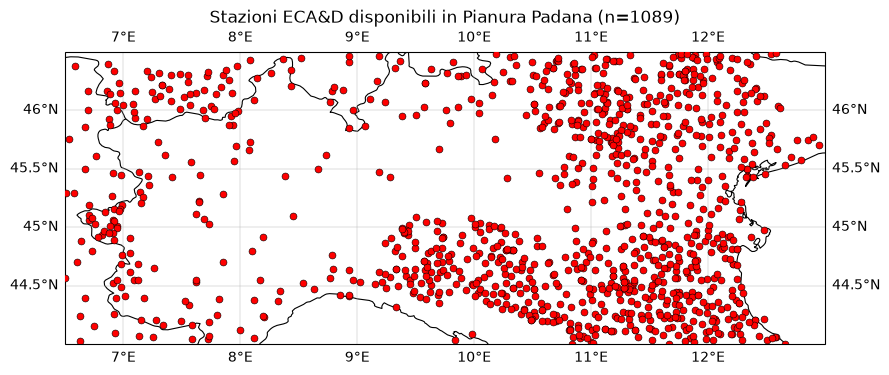

In [ ]:
fig = plt.figure(figsize=(9, 7))

ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
sc = ax.scatter(stations_df["lon"], stations_df["lat"], c="red", s=25,
                    edgecolor="black", linewidth=0.4, transform=ccrs.PlateCarree(), zorder=5)
ax.gridlines(draw_labels=True, linewidth=0.3)


plt.title(f"ECA&D stations available in the Po Valley (n={len(stations_df)})")
plt.tight_layout()
plt.show()


In [ ]:
# setup for downloading the ECA&D data of the selected stations (only those with at least one requested variable)
PARAMETERS = ["tx3", "tn3", "qq2", "rr7"] # maximum temperature, minimum temperature, solar radiation, precipitation
START = "2015-01-01T00:00:00Z"
END   = "2026-08-20T00:00:00Z"   # last date to download (not all stations have data until 2026-08-20, but some do)

def available_parameters(props, wanted=PARAMETERS):
    """Returns the codes in `wanted` actually present in the station properties, looking in
    all the listed providers (a station can have several providers, each with its own
    variant of the variables)."""
    found = set()
    for provider_params in props.get("provider", {}).values():
        found.update(provider_params.keys())
    return sorted(found & set(wanted))

stations_df["available_params"] = stations_df["property"].apply(available_parameters)
stations_df["n_available"] = stations_df["available_params"].apply(len)

print("Stations by number of available variables (0-4):")
print(stations_df["n_available"].value_counts().sort_index())
print()
for p in PARAMETERS:
    n = stations_df["available_params"].apply(lambda lst: p in lst).sum()
    print(f"  stations with {p}: {n}")

# Keep only the stations that have at least one of the 4 requested variables
target_stations = stations_df[stations_df["n_available"] > 0].reset_index(drop=True)
print(f"\nStations with at least one of the requested variables: {len(target_stations)} / {len(stations_df)}")


Stazioni per numero di parametri disponibili (0-4):
n_available
0    391
1    245
2     27
3    329
4     97
Name: count, dtype: int64

  stazioni con tx3: 453
  stazioni con tn3: 453
  stazioni con qq2: 150
  stazioni con rr7: 618

Stazioni con almeno uno dei parametri richiesti: 698 / 1089


Check of the spatial distribution of the stations by variable

In [ ]:
# Administrative boundaries of the Italian regions (source: openpolis/geojson-italy).
# Local cache, so they are not downloaded again at every run of the notebook.
REGIONS_CACHE = REGIONI
REGIONS_URL = "https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson"

if not os.path.exists(REGIONS_CACHE):
    r = requests.get(REGIONS_URL, timeout=30)
    r.raise_for_status()
    with open(REGIONS_CACHE, "wb") as f:
        f.write(r.content)

import geopandas as gpd

regions_gdf = gpd.read_file(REGIONS_CACHE)[["reg_name", "geometry"]]

# The only region kept out of training (geographical extrapolation test).
# Lombardy and Veneto stay in training: they are the regions where we give priority to
# integrating the ARPA data, to make the coverage denser than with ECA&D alone.
TEST_REGIONS = ["Piemonte"]


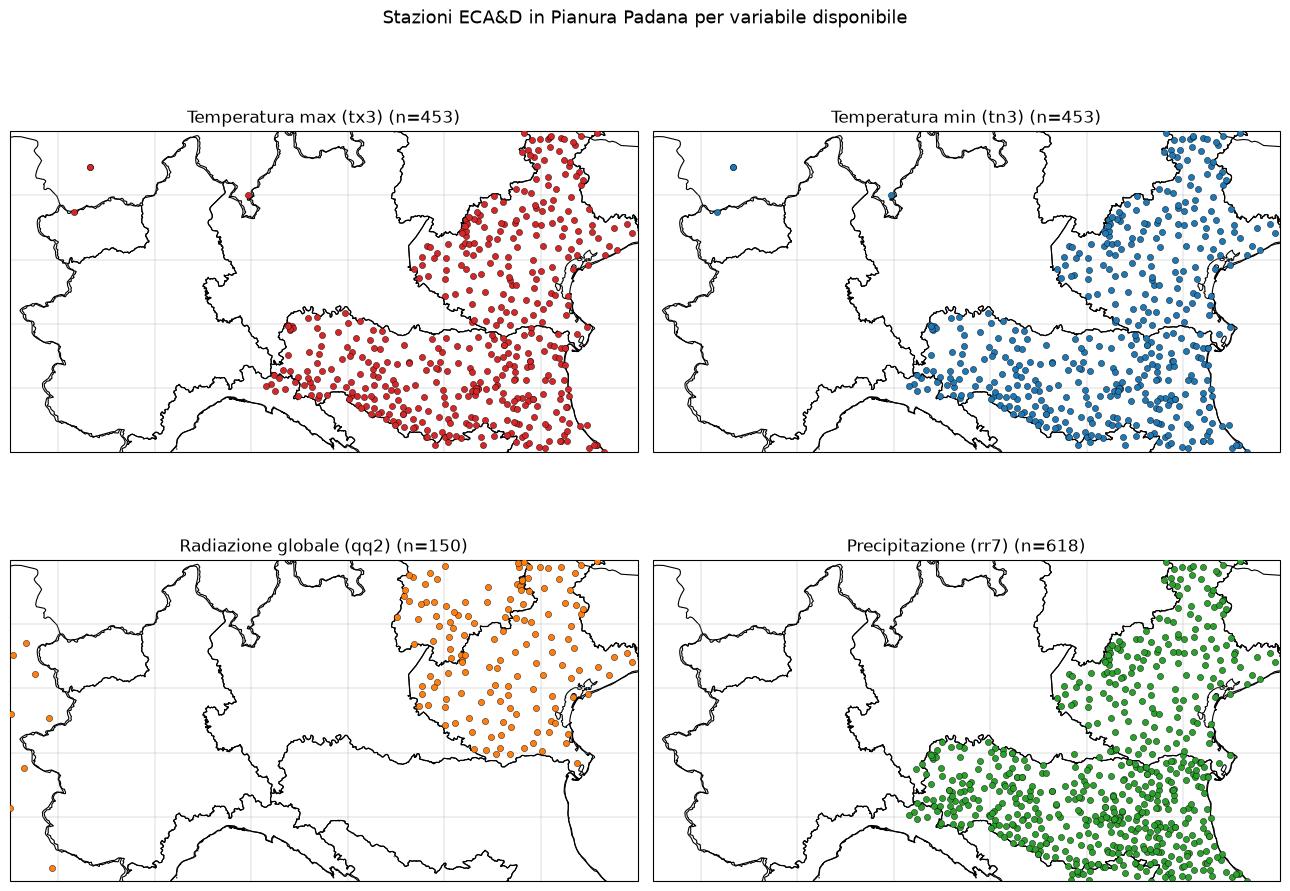

In [ ]:
PARAM_LABELS = {
    "tx3": "Maximum temperature (tx3)",
    "tn3": "Minimum temperature (tn3)",
    "qq2": "Global radiation (qq2)",
    "rr7": "Precipitation (rr7)",
}
PARAM_COLORS = {
    "tx3": "tab:red",
    "tn3": "tab:blue",
    "qq2": "tab:orange",
    "rr7": "tab:green",
}

fig, axes = plt.subplots(
    2, 2, figsize=(13, 10),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

for ax, param in zip(axes.flat, PARAMETERS):
    sub = target_stations[target_stations["available_params"].apply(lambda lst: param in lst)]
    ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax = regions_gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.8, zorder=3)

    ax.scatter(sub["lon"], sub["lat"], c=PARAM_COLORS[param], s=20,
                edgecolor="black", linewidth=0.3, transform=ccrs.PlateCarree(), zorder=5)
    ax.gridlines(draw_labels=False, linewidth=0.3)

    ax.set_title(f"{PARAM_LABELS[param]} (n={len(sub)})")

fig.suptitle("ECA&D stations in the Po Valley by available variable", fontsize=13)
plt.tight_layout()
plt.show()


In [ ]:
# Functions to download the ECA&D data of a specific station/variable,
# to be run for each station and each available variable in the list `target_stations["available_params"]`.
def _nearest_coverage(data, target_lon, target_lat):
    """Extracts (domain+ranges) of the point closest to (target_lon, target_lat).
    Handles both a single CoverageJSON response ("domain"/"ranges" at the top) and a
    CoverageCollection ("coverages": [...]), which the API returns if the bbox includes
    more than one station with data for the requested variable."""
    candidates = data["coverages"] if "coverages" in data else [data]
    best, best_dist = None, None
    for cov in candidates:
        axes = cov["domain"]["axes"]
        x = axes["x"]["values"][0]
        y = axes["y"]["values"][0]
        d = (x - target_lon) ** 2 + (y - target_lat) ** 2
        if best_dist is None or d < best_dist:
            best, best_dist = cov, d
    return best


class FetchError(Exception):
    """Retryable error (network, 5xx, too many 429 in a row): the caller must NOT
    interpret it as "no data" and must not write it to the cache, so at the next run
    the station/variable pair is retried instead of being lost."""
    pass


def fetch_station_parameter(station_id, lon, lat, parameter, start=START, end=END,
                             pause=0.15, max_retries=6):
    """Time series of ONE station for ONE specific EDR variable code (e.g. 'tx3'),
    requested with 'parameter-name'.

    NOTE on the rate limit (checked live on 21/08/2026): the EUMETNET/RODEO gateway
    applies a limit of 400 requests per window for an anonymous IP (HTTP 429 response,
    headers X-RateLimit-Limit/Remaining/Reset). It is NOT a limit on the file size:
    a single request with range 2015-2026 weighs only ~200KB and takes ~1.5s. The problem
    is the NUMBER of requests (one per station/variable pair, about 1.1-1.7k in this area),
    well above 400/window.
    On 429 we wait for the time given in X-RateLimit-Reset and retry (up to max_retries
    times): the loop pauses by itself and resumes automatically.

    - 404 = the station does not expose that variable -> empty Series ("confirmed missing
      data", to be cached).
    - Network error / 5xx / too many 429 in a row -> raises FetchError (NOT to be cached:
      to be retried at the next run)."""
    eps = 0.03  # ~3 km, same margin used in §4 to make up for the offset between the
                # registry coordinates of the station and the /cube grid point
    bbox = f"{lon - eps},{lat - eps},{lon + eps},{lat + eps}"
    url = f"{COLLECTION_URL}/cube"
    params = {
        "bbox": bbox,
        "parameter-name": parameter,
        "datetime": f"{start}/{end}",
        "f": "CoverageJSON",
    }

    for attempt in range(max_retries):
        try:
            r = requests.get(url, params=params, timeout=60)
        except requests.RequestException as e:
            raise FetchError(f"network error: {e}")

        if r.status_code == 429:
            reset_s = int(r.headers.get("X-RateLimit-Reset", 90))
            wait = min(reset_s, 3600) + 5  # safety margin, capped at 1h
            print(f"Rate limit reached (attempt {attempt + 1}/{max_retries}): "
                  f"pausing {wait}s (X-RateLimit-Reset={reset_s}s)...")
            time.sleep(wait)
            continue

        if r.status_code == 404:
            time.sleep(pause)
            return pd.Series(dtype=float, name=parameter)

        if not r.ok:
            raise FetchError(f"HTTP {r.status_code} on {station_id}/{parameter}: {r.text[:300]}")

        time.sleep(pause)  # gentle with the server even when everything goes well
        try:
            data = r.json()
            cov = _nearest_coverage(data, lon, lat)
            times = pd.to_datetime(cov["domain"]["axes"]["t"]["values"])
            values = cov["ranges"][parameter]["values"]
            return pd.Series(values, index=times, name=parameter)
        except (KeyError, TypeError, IndexError, ValueError):
            print(f"Unexpected format for {station_id}/{parameter}. Raw response (excerpt):")
            print(json.dumps(data, indent=2)[:1000])
            return pd.Series(dtype=float, name=parameter)

    raise FetchError(f"too many consecutive 429 on {station_id}/{parameter}")


# Example: try ONE station/variable before running the loop over all of them
# example_row = target_stations.iloc[0]
# example_param = example_row["available_params"][0]
# example_series = fetch_station_parameter(example_row["station_id"], example_row["lon"], example_row["lat"], example_param)
# print(example_row["station_id"], example_param, "->", len(example_series), "observations")
# example_series.head()

Local storage of the ECA&D data

In [ ]:
# On-disk cache per (station, variable) pair: every series downloaded successfully is
# saved IMMEDIATELY in a separate CSV. If the loop stops (rate limit after too many
# retries, kernel stopped by hand, etc.) the work already done is not lost: re-running
# the cell below, the pairs already in the cache are skipped and it resumes from the
# missing ones.
RAW_CACHE_DIR = CACHE_ECAD
os.makedirs(RAW_CACHE_DIR, exist_ok=True)

def _cache_path(sid, param):
    return os.path.join(RAW_CACHE_DIR, f"{sid}__{param}.csv")

def _load_cached(sid, param):
    p = _cache_path(sid, param)
    if not os.path.exists(p):
        return None
    df = pd.read_csv(p, index_col=0, parse_dates=True)
    return df.iloc[:, 0].rename(param) if df.shape[1] else pd.Series(dtype=float, name=param)

def _save_cache(sid, param, s):
    s.to_frame(name=param).to_csv(_cache_path(sid, param), index_label="date")

pairs = [(row["station_id"], row["lon"], row["lat"], p)
         for _, row in target_stations.iterrows()
         for p in row["available_params"]]
print(f"{len(pairs)} station-variable pairs to retrieve (cache in ./{RAW_CACHE_DIR}/).")


1674 coppie stazione-parametro da recuperare (cache in ./ecad_padania_raw_cache/).


In [ ]:
# Actual loop: for each pair, use the cache if present, otherwise download and cache
# immediately. fetch_station_parameter handles the rate limit by itself (pause and retry
# on 429): it can therefore pause for several minutes on its own when the API limit is
# used up, and then resume automatically. You can interrupt the kernel at any time and
# re-run this cell: it restarts from where it stopped.
from tqdm import tqdm

# to be re-run at every use of the notebook
all_data = {}   # {station_id: {parameter: pd.Series}}
failed = []
n_from_cache = 0
n_fetched = 0

for sid, s_lon, s_lat, param in tqdm(pairs):
    cached = _load_cached(sid, param)
    if cached is not None:
        s = cached
        n_from_cache += 1
    else:
        try:
            s = fetch_station_parameter(sid, s_lon, s_lat, param)
        except FetchError as e:
            print(f"Skipping {sid}/{param} (will retry at the next run of this cell): {e}")
            failed.append((sid, param))
            continue
        _save_cache(sid, param, s)
        n_fetched += 1
    all_data.setdefault(sid, {})[param] = s

n_ok = sum(len(d) for d in all_data.values())
print(f"From cache: {n_from_cache} | downloaded now: {n_fetched} | failed/to retry: {len(failed)}")
print(f"Total series available: {n_ok} / {len(pairs)}")
if failed:
    print(f"Re-run this cell to retry the failed pairs (first 10: {failed[:10]})")


  0%|          | 0/1674 [00:00<?, ?it/s]

100%|██████████| 1674/1674 [01:58<00:00, 14.18it/s]

Da cache: 1674 | scaricate ora: 0 | fallite/da ritentare: 0
Totale serie disponibili: 1674 / 1674


In [ ]:
# DataFrames split by year: for each year, rows = calendar dates, columns =
# MultiIndex (station_id, parameter) with the available variables side by side for each
# station (tx3/tn3/qq2/rr7, or the subset that station exposes).
yearly_data = {}

for year in YEARS:
    full_index = pd.date_range(f"{year}-01-01", f"{year}-12-31", freq="D", tz="UTC")
    cols = {}
    for sid, params in all_data.items(): # for each station, take the dictionary {param: Series}
        for param, s in params.items(): # for each variable of the station, take the Series
            if len(s) == 0:
                # empty series (cached 404 "no data", or cache written by a previous run):
                # the index is not a DatetimeIndex, nothing to filter by year.
                continue
            s_year = s[s.index.year == year]
            if len(s_year) == 0:
                continue
            cols[(sid, param)] = s_year.resample("D").mean().reindex(full_index)
    if cols:
        df_year = pd.DataFrame(cols)
        df_year.columns = pd.MultiIndex.from_tuples(df_year.columns, names=["station_id", "parameter"])
        df_year = df_year.sort_index(axis=1)
    else:
        df_year = pd.DataFrame(index=full_index)
    yearly_data[year] = df_year
    print(f"{year}: {df_year.shape[1]} station-variable series, {df_year.shape[0]} days")

# Example: yearly_data[2020]["ecad_0000170"]["tx3"]  -> daily Series
yearly_data[2020].head()


2015: 1440 serie stazione-parametro, 365 giorni
2016: 1428 serie stazione-parametro, 366 giorni
2017: 1399 serie stazione-parametro, 365 giorni
2018: 1430 serie stazione-parametro, 365 giorni
2019: 1386 serie stazione-parametro, 365 giorni
2020: 1300 serie stazione-parametro, 366 giorni
2021: 1305 serie stazione-parametro, 365 giorni
2022: 1326 serie stazione-parametro, 365 giorni
2023: 1315 serie stazione-parametro, 365 giorni
2024: 1331 serie stazione-parametro, 366 giorni
2025: 1278 serie stazione-parametro, 365 giorni
2026: 1269 serie stazione-parametro, 365 giorni


station_id                ecad_0000170         ecad_0000242        \
parameter                          rr7 tn3 tx3          tn3   tx3   
2020-01-01 00:00:00+00:00          NaN NaN NaN          1.0   7.7   
2020-01-02 00:00:00+00:00          NaN NaN NaN          2.4   8.9   
2020-01-03 00:00:00+00:00          NaN NaN NaN          1.3   8.3   
2020-01-04 00:00:00+00:00          NaN NaN NaN          1.9   6.8   
2020-01-05 00:00:00+00:00          NaN NaN NaN          1.6  15.6   

station_id                ecad_0000380            ecad_0000755 ecad_0000854  \
parameter                          rr7  tn3   tx3          qq2          rr7   
2020-01-01 00:00:00+00:00          0.0 -1.6   6.6         84.0          0.0   
2020-01-02 00:00:00+00:00          0.2 -1.1   9.6         84.0          0.0   
2020-01-03 00:00:00+00:00          0.2 -0.5  11.2         78.0          0.0   
2020-01-04 00:00:00+00:00          0.0 -1.1   7.6         55.0          0.0   
2020-01-05 00:00:00+00:00          0.2 -0.6  11.0         84.0          0.0   

station_id                 ... ecad_0027905       ecad_0027906       \
parameter                  ...          tn3   tx3          tn3  tx3   
2020-01-01 00:00:00+00:00  ...         -4.0   8.7         -1.1  5.5   
2020-01-02 00:00:00+00:00  ...         -3.9  10.3          3.4  7.7   
2020-01-03 00:00:00+00:00  ...         -4.1   9.0          0.9  9.2   
2020-01-04 00:00:00+00:00  ...         -3.9   7.5         -0.8  6.9   
2020-01-05 00:00:00+00:00  ...         -4.2   6.2          2.8  9.8   

station_id                ecad_0027908      ecad_0027911       ecad_0027912  \
parameter                          tn3  tx3          tn3   tx3          tn3   
2020-01-01 00:00:00+00:00         -0.6  7.9          0.5   4.7          2.0   
2020-01-02 00:00:00+00:00         -1.7  8.9          2.3   9.8          2.2   
2020-01-03 00:00:00+00:00          0.2  9.6          3.8   9.4          4.2   
2020-01-04 00:00:00+00:00         -0.8  6.1          0.6   6.2          3.2   
2020-01-05 00:00:00+00:00         -1.0  9.4          1.7  10.3          4.8   

station_id                       
parameter                   tx3  
2020-01-01 00:00:00+00:00   9.7  
2020-01-02 00:00:00+00:00  10.9  
2020-01-03 00:00:00+00:00  11.3  
2020-01-04 00:00:00+00:00  10.2  
2020-01-05 00:00:00+00:00  12.8  

[5 rows x 1300 columns]

In [ ]:
# Saving to disk, one table per year. The MultiIndex columns (station_id, parameter)
# are flattened into "station_id__parameter" for CSV compatibility (no dependency on
# pyarrow/fastparquet, which were not installed in this environment).
os.makedirs(ECAD_PER_ANNO, exist_ok=True)
for year, df_year in yearly_data.items():
    if df_year.empty:
        continue
    flat = df_year.copy()
    flat.columns = [f"{sid}__{param}" for sid, param in flat.columns]
    flat.to_csv(os.path.join(ECAD_PER_ANNO, f"ecad_padania_{year}.csv"), index_label="date")
print("Saved in ./ecad_padania_by_year/")

# To reload a year keeping the MultiIndex (station_id, parameter):
# flat = pd.read_csv(os.path.join(ECAD_PER_ANNO, f"ecad_padania_{year}.csv"), index_col=0, parse_dates=True)
# flat.columns = pd.MultiIndex.from_tuples([tuple(c.split("__")) for c in flat.columns],
#                                           names=["station_id", "parameter"])


Salvati in ./ecad_padania_by_year/


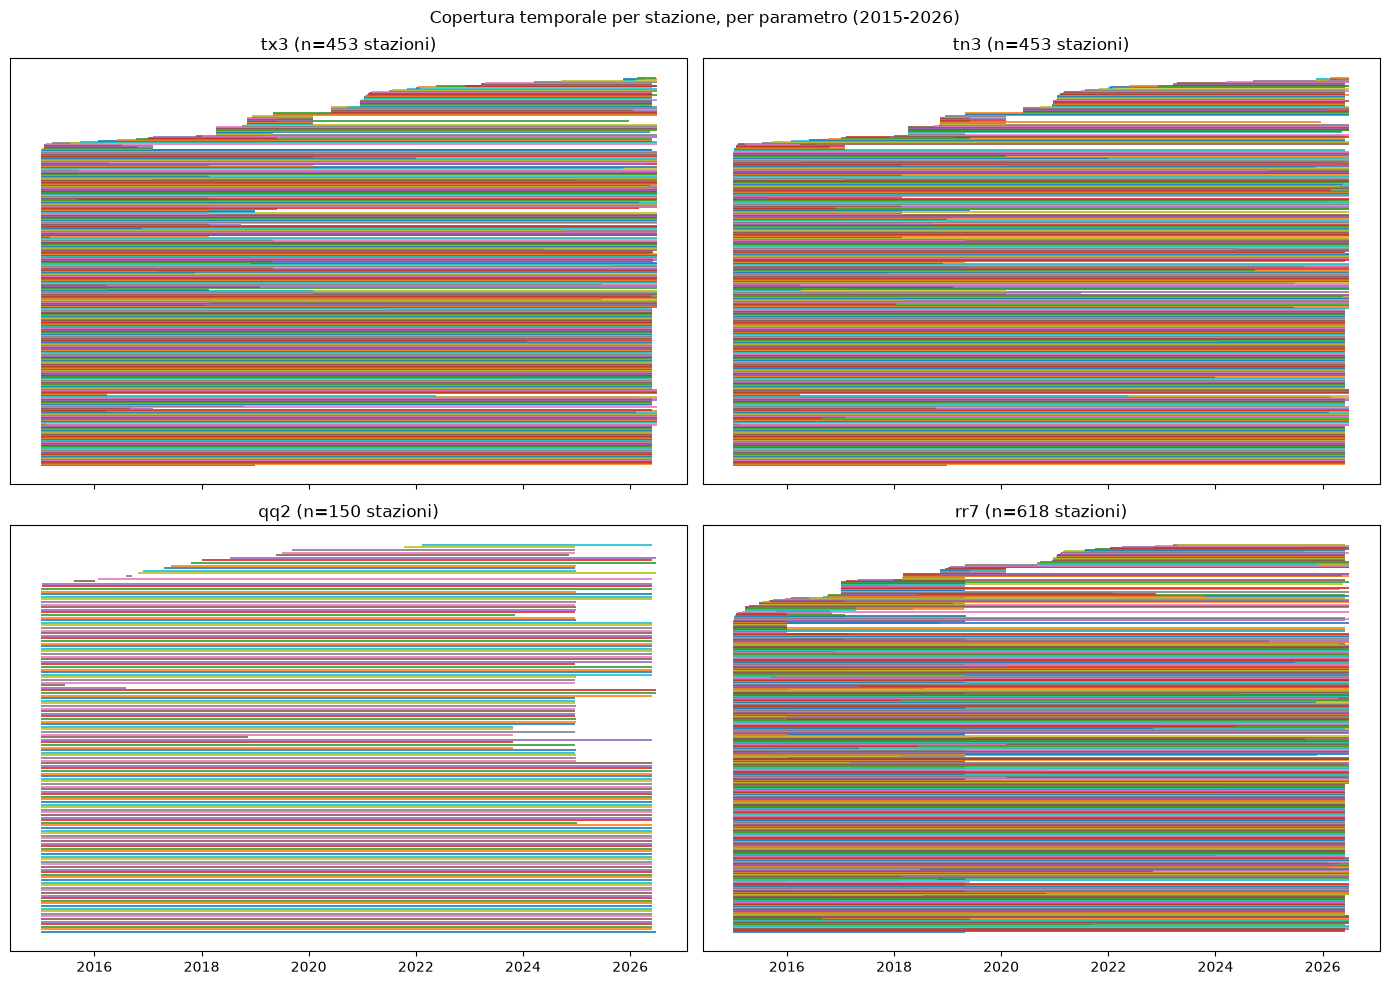

,station_id,parameter,n_obs,first_obs,last_obs
10,ecad_0000755,qq2,4191,2015-01-01 00:00:00+00:00,2026-06-23 00:00:00+00:00
984,ecad_0020871,qq2,579,2015-01-01 00:00:00+00:00,2016-08-01 00:00:00+00:00
985,ecad_0020889,qq2,4179,2015-01-01 00:00:00+00:00,2026-06-23 00:00:00+00:00
986,ecad_0021550,qq2,4156,2015-01-01 00:00:00+00:00,2026-06-23 00:00:00+00:00
1010,ecad_0025805,qq2,3507,2015-01-01 00:00:00+00:00,2026-06-01 00:00:00+00:00
...,...,...,...,...,...
492,ecad_0017630,tx3,0,NaT,NaT
633,ecad_0017695,tx3,0,NaT,NaT
735,ecad_0017751,tx3,0,NaT,NaT
741,ecad_0017753,tx3,0,NaT,NaT


In [ ]:
# Temporal coverage: first/last valid observation for each station-variable pair
coverage_summary = []
for sid, params in all_data.items():
    for param, s in params.items():
        valid = s.dropna()
        coverage_summary.append({
            "station_id": sid,
            "parameter": param,
            "n_obs": len(valid),
            "first_obs": valid.index.min() if len(valid) else pd.NaT,
            "last_obs": valid.index.max() if len(valid) else pd.NaT,
        })

coverage_df = pd.DataFrame(coverage_summary).sort_values(["parameter", "first_obs"])

# Temporal coverage plot, one panel per variable (Gantt style).
# With hundreds of stations per variable the y labels are unreadable: we omit them
# and show only the number of stations in the title of each panel.
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
for ax, param in zip(axes.flat, PARAMETERS):
    sub = coverage_df[coverage_df["parameter"] == param].sort_values("first_obs").reset_index(drop=True)
    for i, row in sub.iterrows():
        if pd.notnull(row["first_obs"]) and pd.notnull(row["last_obs"]):
            ax.plot([row["first_obs"], row["last_obs"]], [i, i], linewidth=1.2, solid_capstyle="butt")
    ax.set_title(f"{param} (n={len(sub)} stations)")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_yticks([])

fig.suptitle("Temporal coverage per station, by variable (2015-2026)")
plt.tight_layout()
plt.show()
coverage_df


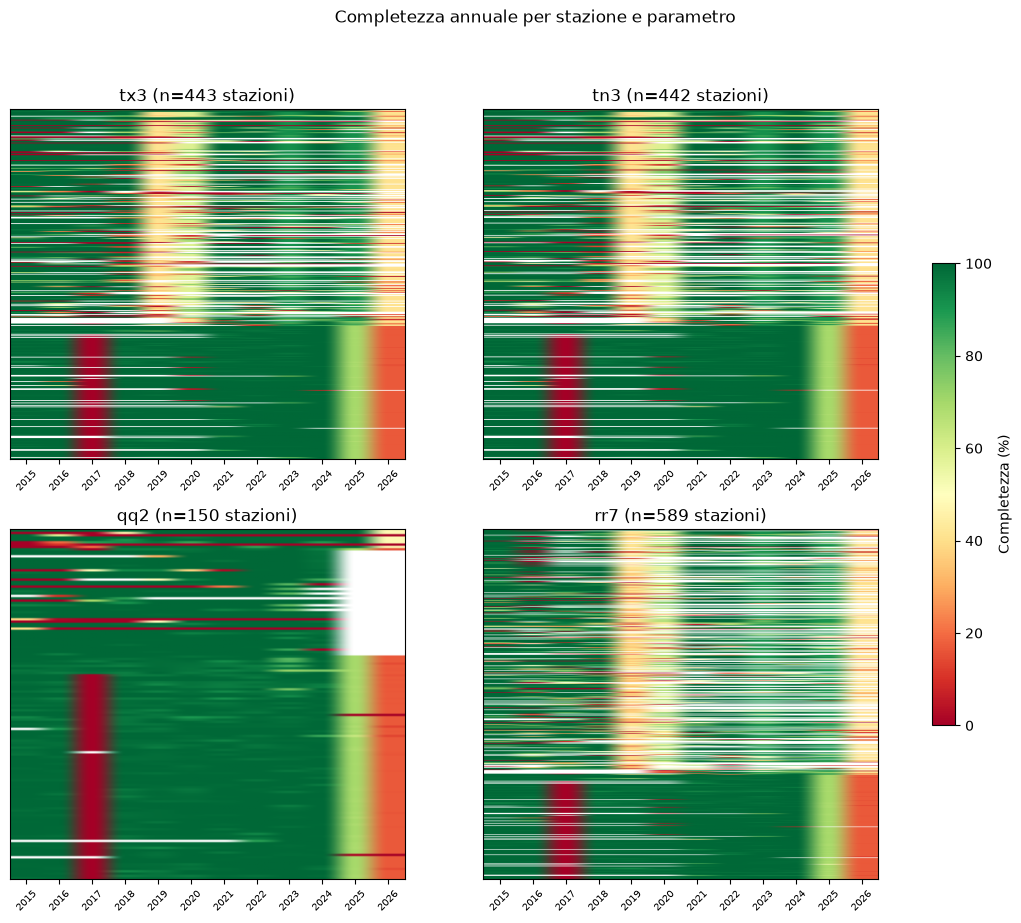

         station_id parameter  year  completeness_pct
0      ecad_0000170       rr7  2015        100.000000
1      ecad_0000170       tn3  2015         99.726027
2      ecad_0000170       tx3  2015         99.726027
3      ecad_0000242       tn3  2015        100.000000
4      ecad_0000242       tx3  2015        100.000000
5      ecad_0000380       rr7  2015         97.808219
6      ecad_0000380       tn3  2015         97.808219
7      ecad_0000380       tx3  2015         97.808219
8      ecad_0000755       qq2  2015        100.000000
9      ecad_0000853       rr7  2015         99.452055
10     ecad_0000854       rr7  2015        100.000000
11     ecad_0000854       tn3  2015         99.726027
12     ecad_0000854       tx3  2015        100.000000
13     ecad_0000855       rr7  2015        100.000000
14     ecad_0000855       tn3  2015        100.000000
15     ecad_0000855       tx3  2015        100.000000
16     ecad_0000856       rr7  2015        100.000000
17     ecad_0000856       tn

In [ ]:
# Annual completeness (%): observations present / expected (daily) observations,
# for each station x variable x year combination, computed directly from the
# annual DataFrames already built in yearly_data.
records = []
for year, df_year in yearly_data.items():
    if df_year.empty:
        continue
    is_leap = (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0))
    expected = 366 if is_leap else 365
    for sid, param in df_year.columns:
        actual = df_year[(sid, param)].dropna().shape[0]
        records.append({
            "station_id": sid,
            "parameter": param,
            "year": year,
            "completeness_pct": 100 * actual / expected,
        })

completeness_long = pd.DataFrame(records)

# Completeness heatmap (stations x years), one panel per variable
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (completeness_long[completeness_long["parameter"] == param]
             .pivot(index="station_id", columns="year", values="completeness_pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, fontsize=7)
    ax.set_yticks([])  # hundreds of stations: labels unreadable

fig.colorbar(im, ax=axes, label="Completeness (%)", shrink=0.6)
fig.suptitle("Annual completeness by station and variable")
plt.show()
with pd.option_context("display.max_rows", None):
    print(completeness_long)


In [ ]:
completeness_long_70 = completeness_long[completeness_long["completeness_pct"] > 70]
num_sensors_above_70 = completeness_long_70["station_id"].count()
with pd.option_context("display.max_rows", None):
    print(completeness_long_70)
print(f"Number of sensors with completeness > 70%: {num_sensors_above_70}/{len(completeness_long)}")

         station_id parameter  year  completeness_pct
0      ecad_0000170       rr7  2015        100.000000
1      ecad_0000170       tn3  2015         99.726027
2      ecad_0000170       tx3  2015         99.726027
3      ecad_0000242       tn3  2015        100.000000
4      ecad_0000242       tx3  2015        100.000000
5      ecad_0000380       rr7  2015         97.808219
6      ecad_0000380       tn3  2015         97.808219
7      ecad_0000380       tx3  2015         97.808219
8      ecad_0000755       qq2  2015        100.000000
9      ecad_0000853       rr7  2015         99.452055
10     ecad_0000854       rr7  2015        100.000000
11     ecad_0000854       tn3  2015         99.726027
12     ecad_0000854       tx3  2015        100.000000
13     ecad_0000855       rr7  2015        100.000000
14     ecad_0000855       tn3  2015        100.000000
15     ecad_0000855       tx3  2015        100.000000
16     ecad_0000856       rr7  2015        100.000000
17     ecad_0000856       tn

C:\Users\acer\AppData\Local\Temp\ipykernel_22144\4113501919.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pivot = (completeness_long_70[completeness_long["parameter"] == param]
C:\Users\acer\AppData\Local\Temp\ipykernel_22144\4113501919.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pivot = (completeness_long_70[completeness_long["parameter"] == param]
C:\Users\acer\AppData\Local\Temp\ipykernel_22144\4113501919.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pivot = (completeness_long_70[completeness_long["parameter"] == param]
C:\Users\acer\AppData\Local\Temp\ipykernel_22144\4113501919.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pivot = (completeness_long_70[completeness_long["parameter"] == param]


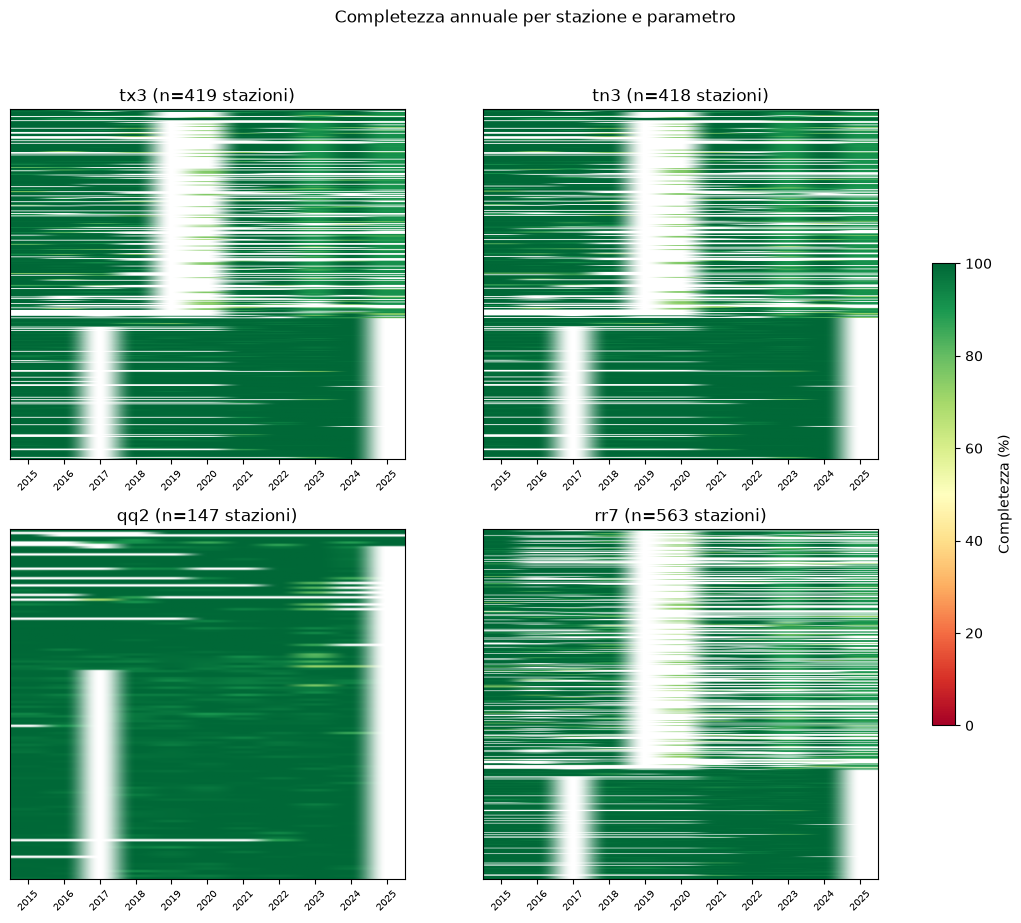

In [ ]:
# Completeness heatmap (stations x years), one panel per variable
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (completeness_long_70[completeness_long["parameter"] == param]
             .pivot(index="station_id", columns="year", values="completeness_pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, fontsize=7)
    ax.set_yticks([])  # hundreds of stations: labels unreadable

fig.colorbar(im, ax=axes, label="Completeness (%)", shrink=0.6)
fig.suptitle("Annual completeness by station and variable")
plt.show()


Diagnosis of the systematic coverage anomalies


In [ ]:
# Count of valid observations per year, for each cached station-variable series
# (ecad_padania_raw_cache/, §6): used to find "isolated gaps" (an almost empty year
# between two full years), different from a normal start/end of activity of the
# station (which is instead a natural tapering at the edges of the activity period).
import glob

ecad_files = glob.glob(os.path.join(CACHE_ECAD, "*.csv"))
_rows = []
for f in ecad_files:
    df = pd.read_csv(f, parse_dates=["date"])
    if df.empty:
        continue
    df["year"] = df["date"].dt.year
    counts = df.groupby("year").size()
    base = os.path.basename(f).replace(".csv", "")
    for y in range(2015, 2027):
        _rows.append({"file": base, "year": y, "n": int(counts.get(y, 0))})

ecad_yearly_counts = pd.DataFrame(_rows).pivot(index="file", columns="year", values="n").fillna(0)

# Isolated gap: current year sparse, BOTH neighbours full (otherwise it would just be
# the natural start/end of the activity period of the station, not an anomaly).
affected_2017 = set(ecad_yearly_counts[(ecad_yearly_counts[2016] > 300)
                                        & (ecad_yearly_counts[2018] > 300)
                                        & (ecad_yearly_counts[2017] < 150)].index)
_rest = ecad_yearly_counts.drop(index=affected_2017)
affected_2019 = set(_rest[(_rest[2018] > 250) & (_rest[2020] > 250) & (_rest[2019] < 200)].index)
_rest2 = _rest.drop(index=affected_2019)
affected_2022 = set(_rest2[(_rest2[2021] > 250) & (_rest2[2023] > 250) & (_rest2[2022] < 150)].index)
affected_er = affected_2019 | affected_2022

def _station_of(base):
    return base.split("__")[0]

veneto_stations = {_station_of(b) for b in affected_2017}
er_stations = {_station_of(b) for b in affected_er}
_prov = {f["id"]: set(f.get("properties", {}).get("provider", {}).keys())
         for f in locations["features"]}
veneto_stations = {s for s in veneto_stations if "Loris Tomiato" in _prov.get(s, set())}
er_stations = {s for s in er_stations if "Valentina Pavan" in _prov.get(s, set())}

all_ecad_stations = {_station_of(b) for b in ecad_yearly_counts.index}

print(f"Stations with the 2017 gap (Veneto group): {len(veneto_stations)}")
print(f"Stations with the 2019-2022 gap (Emilia-Romagna group): {len(er_stations)}")
print(f"Overlap between the two groups: {len(veneto_stations & er_stations)}")
print(f"Total ECA&D stations with at least one cached series: {len(all_ecad_stations)}")

Stazioni con buco 2017 (gruppo Veneto): 151
Stazioni con buco 2019-2022 (gruppo Emilia-Romagna): 78
Overlap tra i due gruppi: 0
Totale stazioni ECA&D con almeno una serie in cache: 670


GET https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/locations?f=json
categoria
Nessuna anomalia sistemica rilevata    441
Buco 2017 (Veneto)                     151
Buco 2019-2022 (Emilia-Romagna)         78
Name: count, dtype: int64


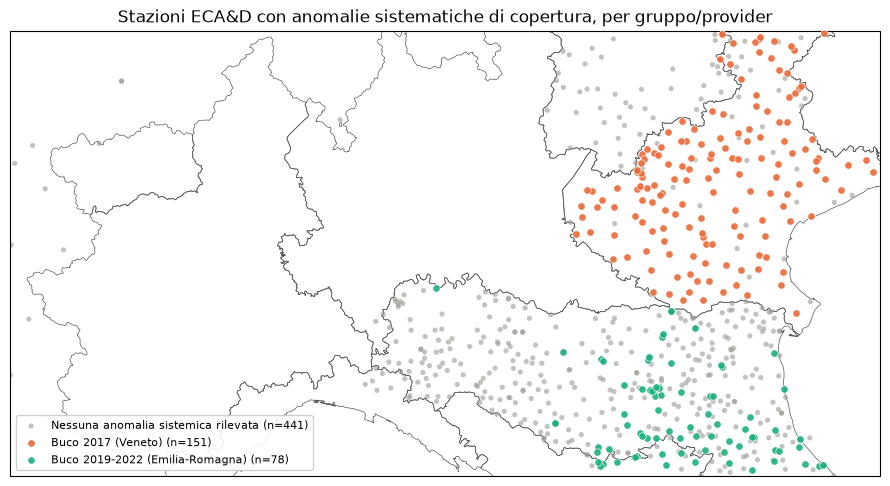

In [ ]:
# Map of the stations by anomaly group, with regional boundaries (same style as the
# other maps of the notebook, §4.1/§6ter). The coordinates come from /locations
# (same registry already used in §4), not from target_stations, so as to include also
# stations excluded elsewhere by the filters: the map reflects the whole downloaded cache.
_locations = edr_get(f"{COLLECTION_URL}/locations", params={"f": "json"})
_feats = {f["id"]: f for f in _locations["features"]}

_records = []
for sid in all_ecad_stations:
    if sid not in _feats:
        continue
    lon, lat = _feats[sid]["geometry"]["coordinates"][:2]
    if sid in veneto_stations:
        cat = "2017 gap (Veneto)"
    elif sid in er_stations:
        cat = "2019-2022 gap (Emilia-Romagna)"
    else:
        cat = "No systematic anomaly found"
    _records.append({"station_id": sid, "lon": lon, "lat": lat, "categoria": cat})

anomaly_stations = pd.DataFrame(_records)
print(anomaly_stations["categoria"].value_counts())

# Palette: neutral grey for the majority without anomalies (background), two distinct
# categorical colours, checked for contrast/colour blindness, for the two highlighted groups.
CAT_COLORS = {
    "No systematic anomaly found": "#9a9a94",
    "2017 gap (Veneto)": "#eb6834",
    "2019-2022 gap (Emilia-Romagna)": "#1baf7a",
}
CAT_ORDER = list(CAT_COLORS.keys())

fig = plt.figure(figsize=(9, 8))

ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=ccrs.PlateCarree())
#ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8)
#ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.8)
regions_gdf.boundary.plot(ax=ax, transform=ccrs.PlateCarree(), color="#555555", linewidth=0.5)
_transform_kw = dict(transform=ccrs.PlateCarree())

for cat in CAT_ORDER:
    sub = anomaly_stations[anomaly_stations["categoria"] == cat]
    is_background = cat == CAT_ORDER[0]
    ax.scatter(sub["lon"], sub["lat"], s=14 if is_background else 28,
               color=CAT_COLORS[cat], edgecolor="none" if is_background else "white",
               linewidth=0.5, alpha=0.6 if is_background else 0.9,
               label=f"{cat} (n={len(sub)})", zorder=2 if is_background else 3, **_transform_kw)

ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title("ECA&D stations with systematic coverage anomalies, by group/provider")
plt.tight_layout()
plt.show()

 Monthly coverage: is there real seasonality?


Completezza media per mese di calendario (2015-2025, tutte le stazioni), con deviazione standard:


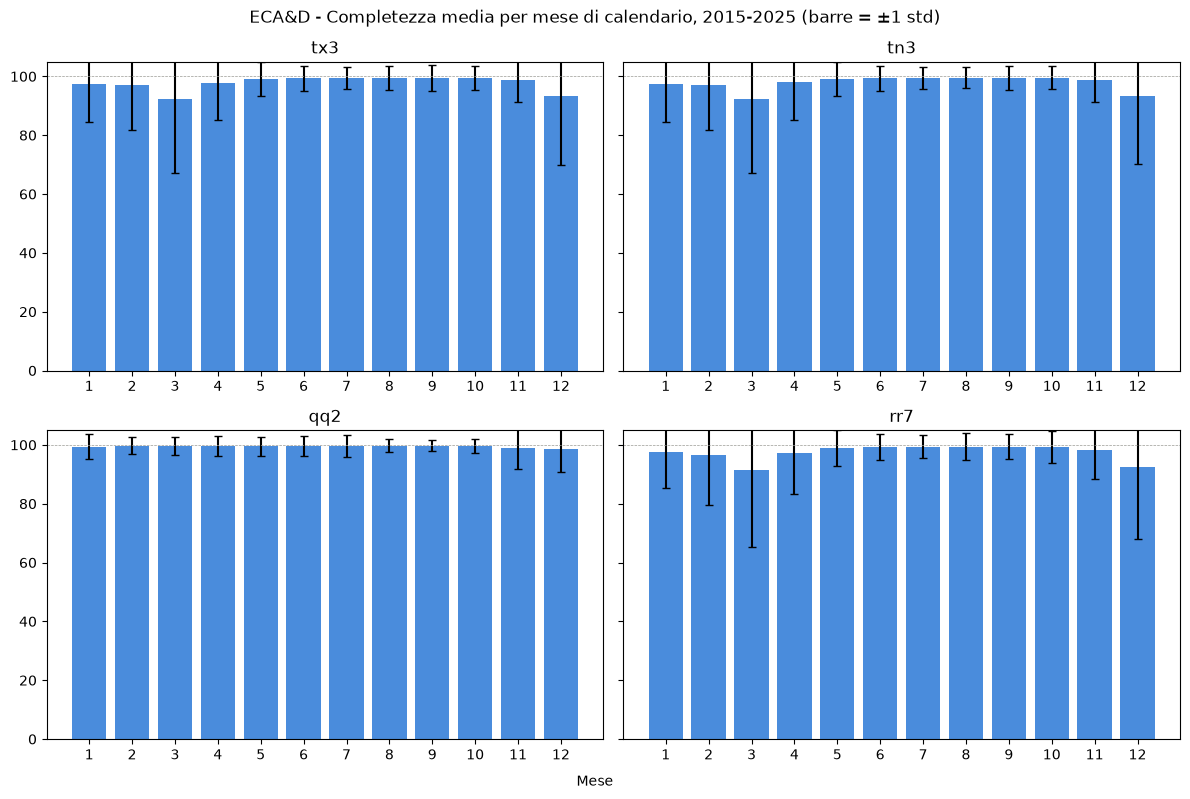

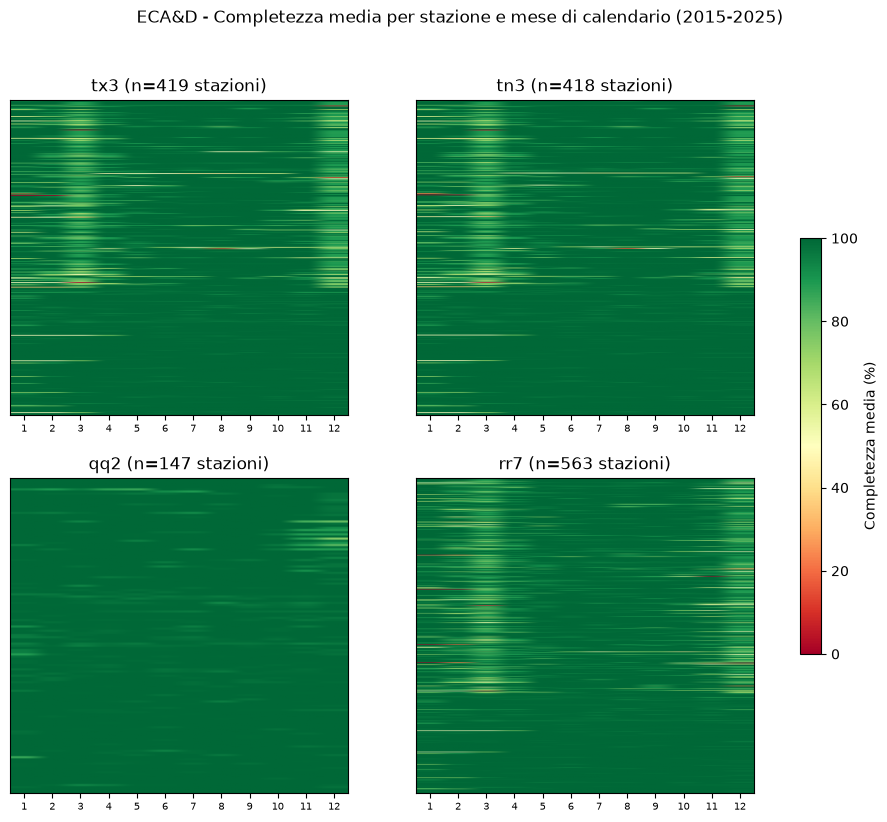

,parameter,month,mean,std
0,qq2,1,99.353369,4.246984
1,qq2,2,99.694222,2.950746
2,qq2,3,99.576261,2.992170
3,qq2,4,99.552012,3.481038
4,qq2,5,99.568913,3.275043
5,qq2,6,99.506454,3.358727
6,qq2,7,99.497881,3.767502
7,qq2,8,99.674235,2.238243
8,qq2,9,99.719058,1.877821
9,qq2,10,99.669336,2.337762


In [ ]:
# Completeness by calendar month (2015-2025), for each cached station-variable series
# (ecad_padania_raw_cache/, §6): same scheme as §6.1 but grouped by month instead of
# by year, to test the seasonality hypothesis.
import calendar

ecad_files = glob.glob(os.path.join(CACHE_ECAD, "*.csv"))
_rows = []
for f in ecad_files:
    df = pd.read_csv(f, parse_dates=["date"])
    if df.empty:
        continue
    df = df[(df["date"].dt.year >= 2015) & (df["date"].dt.year <= 2025)]  # excludes 2026 (current year)
    if df.empty:
        continue
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    base = os.path.basename(f).replace(".csv", "")
    sid, param = base.split("__")
    counts = df.groupby(["year", "month"]).size()
    for (y, m), n in counts.items():
        _rows.append({"station_id": sid, "parameter": param, "year": y, "month": m, "n": n})

ecad_monthly = pd.DataFrame(_rows)
_days_in_month = {m: calendar.monthrange(2015, m)[1] for m in range(1, 13)}
ecad_monthly["expected"] = ecad_monthly["month"].map(_days_in_month)
ecad_monthly["pct"] = (100 * ecad_monthly["n"] / ecad_monthly["expected"]).clip(upper=100)

# Only the station-variable-year combinations with annual completeness > 70% (cell above).
# For those years the grid of the 12 months is rebuilt, so a month without any data
# counts 0% instead of disappearing from the mean.
_sel = completeness_long_70[["station_id", "parameter", "year"]]
_sel = _sel[_sel["year"].between(2015, 2025)]
ecad_monthly_sel = (_sel.merge(pd.DataFrame({"month": range(1, 13)}), how="cross")
                    .merge(ecad_monthly[["station_id", "parameter", "year", "month", "n"]],
                           on=["station_id", "parameter", "year", "month"], how="left")
                    .fillna({"n": 0}))
ecad_monthly_sel["expected"] = [calendar.monthrange(y, m)[1]
                                for y, m in zip(ecad_monthly_sel["year"], ecad_monthly_sel["month"])]
ecad_monthly_sel["pct"] = (100 * ecad_monthly_sel["n"] / ecad_monthly_sel["expected"]).clip(upper=100)

ecad_monthly_agg = ecad_monthly_sel.groupby(["parameter", "month"])["pct"].agg(["mean", "std"]).reset_index()
print("Mean completeness by calendar month (2015-2025, all stations), with standard deviation:")

# Bar chart: mean completeness by month, with ±1 std - one panel per variable.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, param in zip(axes.flat, PARAMETERS):
    sub = ecad_monthly_agg[ecad_monthly_agg["parameter"] == param].sort_values("month")
    ax.bar(sub["month"], sub["mean"], yerr=sub["std"], color="#2a78d6", alpha=0.85, capsize=3)
    ax.set_title(param)
    ax.set_xticks(range(1, 13))
    ax.set_ylim(0, 105)
    ax.axhline(100, color="#9a9a94", linewidth=0.5, linestyle="--")
fig.suptitle("ECA&D - Mean completeness by calendar month, 2015-2025 (bars = ±1 std)")
fig.text(0.5, 0.01, "Month", ha="center")
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

# Station x month heatmap (same RdYlGn style as the other heatmaps of the notebook):
# here one sees WHICH stations a possible monthly pattern comes from, not only whether it
# exists on average - the difference that in the bar chart stays hidden inside the error bars.
ecad_station_month = ecad_monthly_sel.groupby(["station_id", "parameter", "month"])["pct"].mean().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (ecad_station_month[ecad_station_month["parameter"] == param]
             .pivot(index="station_id", columns="month", values="pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(12))
    ax.set_xticklabels(range(1, 13), fontsize=7)
    ax.set_yticks([])
fig.colorbar(im, ax=axes, label="Mean completeness (%)", shrink=0.6)
fig.suptitle("ECA&D - Mean completeness by station and calendar month (2015-2025)")
plt.show()

ecad_monthly_agg

Year x month check and monthly completeness filter

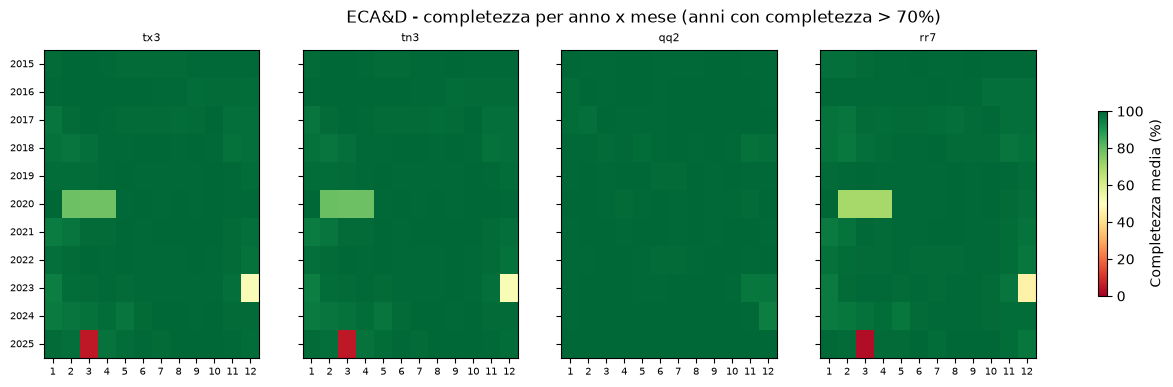

Mesi stazione-parametro validi (>= 70%): 154202 / 160293 (96.2%)


In [ ]:
# Year x month heatmap (mean over the stations), one panel per variable
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    sub = ecad_monthly_sel[ecad_monthly_sel["parameter"] == param]
    pv = (sub.pivot_table(index="year", columns="month", values="pct", aggfunc="mean")
          .reindex(index=range(2015, 2026), columns=range(1, 13)))
    im = ax.imshow(pv.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, interpolation="nearest")
    ax.set_title(f"{param}", fontsize=8)
    ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13), fontsize=7)
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index, fontsize=7)
fig.colorbar(im, ax=axes, label="Mean completeness (%)", shrink=0.6)
fig.suptitle("ECA&D - completeness by year x month (years with completeness > 70%)")
plt.show()

# Monthly completeness filter: station-months below the threshold are excluded from the downstream statistics.
MIN_MONTH_COMPLETENESS = 70
ecad_monthly["ok"] = ecad_monthly["pct"] >= MIN_MONTH_COMPLETENESS
ecad_month_ok = ecad_monthly[ecad_monthly["ok"]]
print(f"Valid station-variable months (>= {MIN_MONTH_COMPLETENESS}%): {len(ecad_month_ok)} / {len(ecad_monthly)} "
      f"({100 * len(ecad_month_ok) / len(ecad_monthly):.1f}%)")


not a real seasonality: it is due only to a few specific years

Download of the Emilia-Romagna global radiation data

In [ ]:
# ARPAE global radiation (Emilia-Romagna): the ECA&D provider for Emilia-Romagna
# (Valentina Pavan) does not supply qq2 (0 stations out of 478, see heatmap above), so the
# radiation for this region is taken directly from the ARPAE-SIMC open data archive
# (BUFR variable B14198, global radiation, hourly mean in W/m2).
#
# One gzipped JSON-lines file per month (~17 MB): each line = one station at one instant.
# On-disk cache per month (already aggregated to daily), same resumable pattern as
# ECA&D/ARPA Lombardia: re-running the cell, the months already cached are skipped.
#
# TIME NOTE: the hourly value with timestamp HH:00 UTC is the mean of the PREVIOUS hour
# (HH-1 -> HH). The day is therefore computed on ts - 1h, so the daily bucket is the
# UTC day 00-24 as for ARPA Lombardia (§6bis). Checked: with this convention the hourly
# mean matches the official ARPAE daily record (timerange 86400, also dated at the end of
# the interval) within 0.5 W/m2.
#
# QC NOTE: at night the pyranometers read slightly negative values (-2/-3 W/m2, ~24% of the
# hourly readings): it is normal noise and must be kept, otherwise almost no day reaches
# the 20 minimum readings. Only values outside [-20, 1200] W/m2 are discarded.
import gzip
import io

ARPAE_BASE = "https://dati-simc.arpae.it/opendata/osservati/meteo/storico"
ARPAE_CACHE_DIR = CACHE_ARPAE
ARPAE_YEARS = range(2016, 2025)  # training years + candidates; for the whole period: YEARS
ARPAE_QC = (-20, 1200)
# The ARPAE archive contains HOURLY means: we compute the daily value ourselves as the mean
# of the hours of the day. If many hours are missing (e.g. exactly the central ones) the mean
# is biased, so a day is valid only with at least ARPAE_MIN_HOURS hours out of 24. The data
# used stays daily.
ARPAE_MIN_HOURS = 20
os.makedirs(ARPAE_CACHE_DIR, exist_ok=True)


def _arpae_month_daily(year, month):
    """Downloads one month of the ARPAE archive and returns the daily radiation per station
    (mean of the valid hourly readings + number of hours used). None if the month is not
    published (yet)."""
    r = requests.get(f"{ARPAE_BASE}/{year}-{month:02d}.json.gz", stream=True, timeout=600)
    if r.status_code == 404:
        return None
    r.raise_for_status()
    recs = []
    for line in io.TextIOWrapper(gzip.GzipFile(fileobj=r.raw), encoding="utf8"):
        o = json.loads(line)
        name = height = val = None
        for block in o.get("data", []):
            v = block.get("vars", {})
            if "B01019" in v:  # registry: station name and elevation (B07030)
                name = v["B01019"]["v"]
                height = v.get("B07030", {}).get("v")
            if "B14198" in v and tuple(block.get("timerange", [])) == (0, 0, 3600):
                val = v["B14198"]["v"]
        if val is not None:
            recs.append((name, o["lat"] / 1e5, o["lon"] / 1e5, height, o["date"], val))
    df = pd.DataFrame(recs, columns=["nome", "lat", "lon", "elevation_m", "ts", "valore"])
    df = df[df["valore"].between(*ARPAE_QC)]
    ts = pd.to_datetime(df["ts"], utc=True).dt.tz_convert(None)
    df["date"] = (ts - pd.Timedelta(hours=1)).dt.floor("D")  # end of interval -> UTC day
    return (df.groupby(["nome", "lat", "lon", "elevation_m", "date"], dropna=False)["valore"]
              .agg(qq2="mean", n_ore="count").reset_index())


arpae_frames, arpae_failed = [], []
for year in ARPAE_YEARS:
    for month in range(1, 13):
        p = os.path.join(ARPAE_CACHE_DIR, f"{year}-{month:02d}.csv")
        if os.path.exists(p):
            arpae_frames.append(pd.read_csv(p, parse_dates=["date"]))
            continue
        try:
            d = _arpae_month_daily(year, month)
        except requests.RequestException as e:
            print(f"Skipping {year}-{month:02d} (will retry at the next run): {e}")
            arpae_failed.append((year, month))
            continue
        if d is None:
            print(f"{year}-{month:02d}: not published, skipping")
            continue
        d.to_csv(p, index=False)
        arpae_frames.append(d)
        print(f"{year}-{month:02d}: {d['nome'].nunique()} stations")

arpae_all = pd.concat(arpae_frames, ignore_index=True)
# The first reading of each month (00:00 of day 1) belongs to the last day of the previous
# month: that day appears in two monthly files with few hours each. The hours are summed
# before the filter, recombining the weighted mean.
arpae_all["somma"] = arpae_all["qq2"] * arpae_all["n_ore"]
arpae_all = (arpae_all.groupby(["nome", "lat", "lon", "elevation_m", "date"], dropna=False)[["somma", "n_ore"]]
             .sum().reset_index())
arpae_all["qq2"] = arpae_all["somma"] / arpae_all["n_ore"]
arpae_all = arpae_all.drop(columns="somma")
# Valid days + only stations in the bbox of the study area
arpae_daily = arpae_all[
    (arpae_all["n_ore"] >= ARPAE_MIN_HOURS)
    & arpae_all["lat"].between(AREA_SOUTH, AREA_NORTH)
    & arpae_all["lon"].between(AREA_WEST, AREA_EAST)
].reset_index(drop=True)
arpae_daily["station_id"] = "arpae_" + arpae_daily["nome"].str.replace(" ", "_")

arpae_stations = arpae_daily.groupby("station_id")[["nome", "lat", "lon", "elevation_m"]].first().reset_index()
print(f"\nARPAE stations with radiation in the bbox: {len(arpae_stations)}")
print(f"Valid station-days (>= {ARPAE_MIN_HOURS} hours): {len(arpae_daily)} "
      f"out of {len(arpae_all)} total station-days")
if arpae_failed:
    print(f"Failed months, re-run the cell to retry: {arpae_failed}")

# Annual completeness per station (valid days / days of the year)
arpae_compl = (arpae_daily.assign(year=arpae_daily["date"].dt.year)
               .groupby(["station_id", "year"]).size().unstack("year"))
arpae_compl = (100 * arpae_compl / [366 if pd.Timestamp(f"{y}-12-31").is_leap_year else 365
                                    for y in arpae_compl.columns]).round(1)
arpae_compl



Stazioni ARPAE con radiazione nel bbox: 29
Giorni-stazione validi (>= 20 ore): 66673 su 70359 giorni-stazione totali


year,2016,2017,2018,2019,2020,2021,2022,2023,2024
station_id,,,,,,,,,
arpae_Bologna_urbana,100.0,100.0,100.0,100.0,97.5,98.6,18.1,NaN,60.7
arpae_Camse,99.2,100.0,99.5,56.2,NaN,NaN,NaN,NaN,NaN
arpae_Cesena_urbana,100.0,100.0,100.0,99.7,100.0,100.0,100.0,49.0,NaN
arpae_Ferrara_urbana,99.5,100.0,100.0,100.0,100.0,100.0,94.5,100.0,95.1
arpae_Fidenza,99.7,8.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arpae_Finale_Emilia,25.4,99.7,99.7,100.0,9.0,99.5,96.2,98.9,91.5
arpae_Forli'_urbana,100.0,100.0,100.0,100.0,100.0,93.4,97.0,99.7,65.6
arpae_GIRALDA,NaN,NaN,NaN,NaN,NaN,35.1,99.5,95.9,99.5
arpae_Granarolo_Faentino,97.8,87.4,69.9,100.0,100.0,100.0,60.3,14.0,53.6


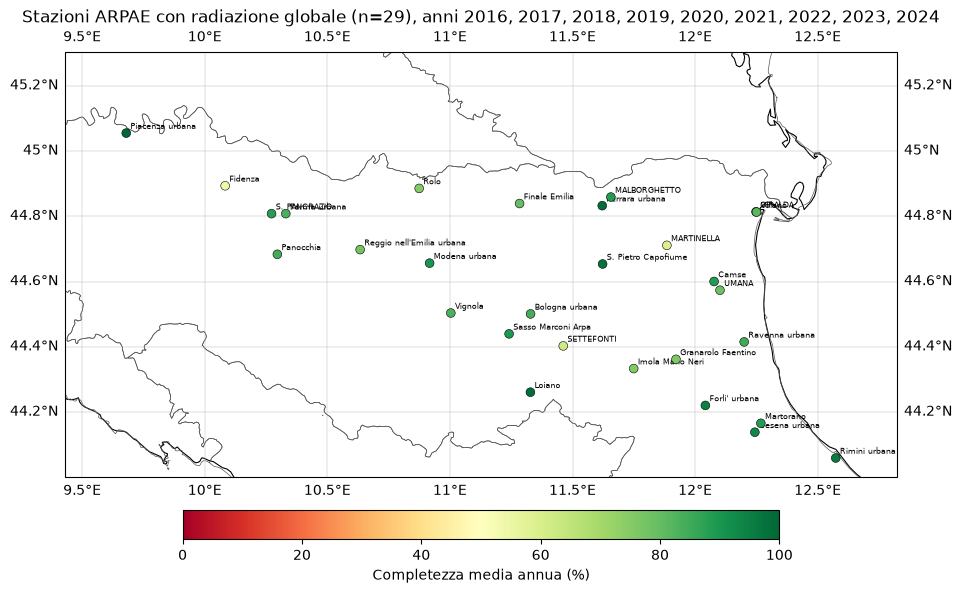

In [ ]:
# Map of the ARPAE stations with global radiation, colour = mean annual completeness
# (mean over ARPAE_YEARS of arpae_compl, cell above).
# Natural Earth coastlines and borders read with geopandas and not with cfeature: with cfeature,
# if the same session has maps in different projections (Mercator + PlateCarree), the cartopy
# cache draws the lines shifted by ~0.2 degrees with respect to regions and stations.
import cartopy.io.shapereader as shpreader

_coste = gpd.read_file(shpreader.natural_earth("10m", "physical", "coastline"))
_confini = gpd.read_file(shpreader.natural_earth("10m", "cultural", "admin_0_boundary_lines_land"))

_st = arpae_stations.merge(arpae_compl.mean(axis=1).rename("compl_media"),
                           left_on="station_id", right_index=True)
_tr = ccrs.PlateCarree()

fig = plt.figure(figsize=(11, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
_coste.plot(ax=ax, transform=_tr, color="black", linewidth=0.8)
_confini.plot(ax=ax, transform=_tr, color="black", linewidth=0.8)
regions_gdf.boundary.plot(ax=ax, transform=_tr, color="#555555", linewidth=0.5)

sc = ax.scatter(_st["lon"], _st["lat"], c=_st["compl_media"], cmap="RdYlGn", vmin=0, vmax=100,
                s=40, edgecolor="black", linewidth=0.4, transform=_tr, zorder=5)
for _, r in _st.iterrows():
    ax.annotate(r["nome"], (r["lon"], r["lat"]), xytext=(3, 3), textcoords="offset points", fontsize=6)

# Zoom on the stations (all in Emilia-Romagna) with a margin; the extent must be set
# AFTER the plots, because geopandas draws worldwide coastlines/borders and widens the limits.
_m = 0.25
ax.set_extent([_st["lon"].min() - _m, _st["lon"].max() + _m,
               max(_st["lat"].min() - _m, AREA_SOUTH), _st["lat"].max() + _m], crs=_tr)
ax.gridlines(draw_labels=True, linewidth=0.3)
fig.colorbar(sc, ax=ax, label="Mean annual completeness (%)", shrink=0.7, orientation="horizontal", pad=0.06)
ax.set_title(f"ARPAE stations with global radiation (n={len(_st)}), years {', '.join(map(str, ARPAE_YEARS))}")
plt.show()

ARPAE qq2 - completezza per anno:
      completezza_media  stazioni_oltre_70  stazioni_con_dati
year                                                         
2016               81.8                 23                 26
2017               84.8                 25                 26
2018               77.6                 22                 24
2019               76.4                 22                 23
2020               62.2                 18                 21
2021               62.2                 15                 23
2022               65.7                 18                 24
2023               52.9                 14                 21
2024               65.8                 17                 24

Completezza media per mese di calendario (tutti gli anni):
{1: 67.0, 2: 68.9, 3: 69.1, 4: 69.8, 5: 69.6, 6: 71.9, 7: 71.8, 8: 71.5, 9: 72.5, 10: 72.6, 11: 68.5, 12: 66.0}


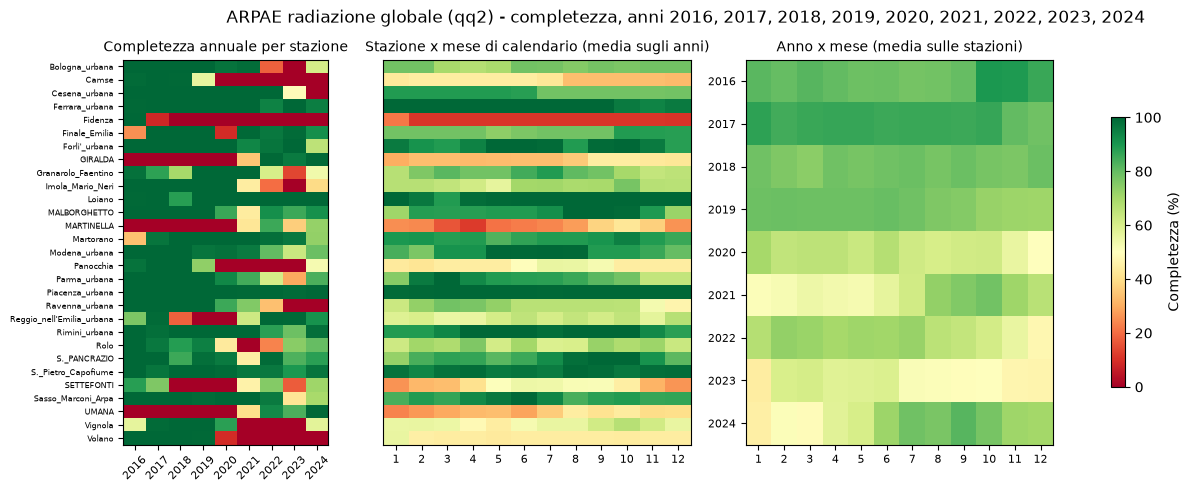

In [ ]:
# ARPAE completeness: same analyses as for ECA&D and ARPA Lombardia (§6.2-6.5).
# The full station x year x month grid over ARPAE_YEARS is built: a month without any
# valid day counts 0% instead of disappearing from the mean (otherwise the completeness
# is inflated). Note: a station activated after the first year counts 0% in the earlier
# years, so the annual completeness also measures the availability of the network.
import calendar

_am = pd.DataFrame([(y, m) for y in ARPAE_YEARS for m in range(1, 13)], columns=["year", "month"])
_n = (arpae_daily.assign(year=arpae_daily["date"].dt.year, month=arpae_daily["date"].dt.month)
      .groupby(["station_id", "year", "month"]).size().rename("n").reset_index())
arpae_monthly = (arpae_stations[["station_id"]].merge(_am, how="cross")
                 .merge(_n, on=["station_id", "year", "month"], how="left").fillna({"n": 0}))
arpae_monthly["expected"] = [calendar.monthrange(y, m)[1] for y, m in zip(arpae_monthly["year"], arpae_monthly["month"])]
arpae_monthly["pct"] = 100 * arpae_monthly["n"] / arpae_monthly["expected"]

# Summary by year: mean completeness and number of almost complete stations
_annua = arpae_monthly.groupby(["station_id", "year"])[["n", "expected"]].sum()
_annua["pct"] = 100 * _annua["n"] / _annua["expected"]
arpae_riepilogo_anni = _annua.groupby("year")["pct"].agg(
    completezza_media="mean", stazioni_oltre_70=lambda x: int((x > 70).sum()),
    stazioni_con_dati=lambda x: int((x > 0).sum())).round(1)
print("ARPAE qq2 - completeness by year:")
print(arpae_riepilogo_anni)
print("\nMean completeness by calendar month (all years):")
print(arpae_monthly.groupby("month")["pct"].mean().round(1).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})
im = None
# 1. station x year
_pv = _annua["pct"].unstack("year")
im = axes[0].imshow(_pv.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, interpolation="nearest")
axes[0].set_xticks(range(len(_pv.columns))); axes[0].set_xticklabels(_pv.columns, rotation=45, fontsize=8)
axes[0].set_yticks(range(len(_pv.index))); axes[0].set_yticklabels(_pv.index.str.replace("arpae_", ""), fontsize=6)
axes[0].set_title("Annual completeness by station", fontsize=10)
# 2. station x calendar month (mean over the years): seasonality per station
_pv = arpae_monthly.groupby(["station_id", "month"])["pct"].mean().unstack("month")
axes[1].imshow(_pv.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, interpolation="nearest")
axes[1].set_xticks(range(12)); axes[1].set_xticklabels(range(1, 13), fontsize=8)
axes[1].set_yticks([])
axes[1].set_title("Station x calendar month (mean over the years)", fontsize=10)
# 3. year x month (mean over the stations): where the gaps are in time
_pv = arpae_monthly.groupby(["year", "month"])["pct"].mean().unstack("month")
axes[2].imshow(_pv.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, interpolation="nearest")
axes[2].set_xticks(range(12)); axes[2].set_xticklabels(range(1, 13), fontsize=8)
axes[2].set_yticks(range(len(_pv.index))); axes[2].set_yticklabels(_pv.index, fontsize=8)
axes[2].set_title("Year x month (mean over the stations)", fontsize=10)
fig.colorbar(im, ax=axes, label="Completeness (%)", shrink=0.7)
fig.suptitle(f"ARPAE global radiation (qq2) - completeness, years {', '.join(map(str, ARPAE_YEARS))}")
plt.show()

## ARPA Lombardia integration (full archive 2015–today)

ECA&D covers Lombardy with only 6 stations (§4.2): we use the ARPA Lombardia network to make the **training** side of the split denser (Lombardy is not in the test).

The sensor registry (`nf78-nj6b`, Socrata) is clean and documented. The readings, instead, are split over several Socrata datasets **without a single index**: the two "live" resources (`647i-nhxk`/`i95f-5avh`) cover only a recent window (checked live: from about mid 2023 to today), but there are also **dedicated historical archives per variable**, with non-standard names that do not show up when searching "sensori meteo" in the catalogue:

| Variable | Historical archive | Recent archive |
|---|---|---|
| Temperature | `d4kj-kbpj` (2011–2020) | `w9wd-u6jh` (from 2021) |
| Precipitation | `2kar-pnuk` (2011–2020) | `pstb-pga6` (from 2021) |
| Global radiation | `63ns-e4tv` (up to 2020, some sensors since the 1980s) | `cxym-eps2` (from 2021) |

The "from 2021" archive empirically stops around early 2026 for some sensors: to cover the last months we also add the two "live" resources as a tail, deduplicating by day. Each sensor also has a quality flag (`stato`): we keep only `stato='VA'` (valid), discarding the missing-data sentinels (e.g. `valore=-999` with `stato='NA'`).

The aggregation is done server side (SoQL `$group`/`date_trunc_ymd`) instead of downloading the raw 10-minute readings.

In [ ]:
# ARPA Lombardia sensor registry (Socrata), filtered to the Po Valley bbox and to the
# sensor types we need. A "Temperatura" station provides both tx3 (max) and tn3 (min)
# from the same raw series aggregated by day.
LOMBARDIA_TIPOLOGIA_TO_PARAM = {
    "Temperatura": ["tx3", "tn3"],
    "Precipitazione": ["rr7"],
    "Radiazione Globale": ["qq2"],
}

lom_registry_rows = []
offset = 0
while True:
    r = requests.get("https://www.dati.lombardia.it/resource/nf78-nj6b.json",
                      params={"$limit": 5000, "$offset": offset}, timeout=30)
    r.raise_for_status()
    batch = r.json()
    if not batch:
        break
    lom_registry_rows.extend(batch)
    offset += 5000

lom_df = pd.DataFrame(lom_registry_rows)
lom_df["lat"] = lom_df["lat"].astype(float)
lom_df["lng"] = lom_df["lng"].astype(float)

lom_df = lom_df[
    lom_df["lat"].between(AREA_SOUTH, AREA_NORTH)
    & lom_df["lng"].between(AREA_WEST, AREA_EAST)
    & lom_df["tipologia"].isin(LOMBARDIA_TIPOLOGIA_TO_PARAM)
].reset_index(drop=True)

print(f"Useful Lombardy sensors in the bbox: {len(lom_df)} ({lom_df['idstazione'].nunique()} stations)")
print(lom_df["tipologia"].value_counts())


Sensori Lombardia utili nel bbox: 748 (336 stazioni)
tipologia
Precipitazione        323
Temperatura           306
Radiazione Globale    119
Name: count, dtype: int64


In [ ]:
# On-disk cache per sensor (a single file already contains the daily max/min/mean/sum):
# resumable as for ECA&D, reuses the same FetchError defined in §6.
#
# TIME ZONE NOTE: the "data" field of ARPA Lombardia is always in fixed standard time
# (UTC+1, never UTC+2 in summer - see the official ARPA Lombardia guide,
# https://www.arpalombardia.it/temi-ambientali/meteo-e-clima/guida-richiesta-dati/:
# "I dati sono sempre riferiti all'ora solare (UTC+1)"), while CERRA and ECA&D (§2, §4)
# are in UTC. To align the three datasets on the same time base, the aggregation "day" is
# computed by shifting "data" back by 1h BEFORE truncating to the day (date_trunc_ymd), so
# the daily bucket matches the UTC solar day instead of the local standard-time day. Cache
# dir renamed (_utc) so as not to mix the CSVs already downloaded with the old convention
# (standard time, not aligned).
LOM_CACHE_DIR = CACHE_LOMBARDIA
os.makedirs(LOM_CACHE_DIR, exist_ok=True)

# One historical + one recent archive per variable (non-standard names, found by inspecting
# the Socrata catalogue by hand - they do not show up searching "sensori meteo"), plus the
# two "live" resources as a tail for the last months not yet merged into the "from 2021" archive.
LOM_OLD_RESOURCE = {
    "Temperatura": "d4kj-kbpj",
    "Precipitazione": "2kar-pnuk",
    "Radiazione Globale": "63ns-e4tv",
}
LOM_NEW_RESOURCE = {
    "Temperatura": "w9wd-u6jh",
    "Precipitazione": "pstb-pga6",
    "Radiazione Globale": "cxym-eps2",
}
LOM_LIVE_RESOURCES = ["647i-nhxk", "i95f-5avh"]
LOM_START = "2015-01-01T00:00:00"
LOM_END = datetime.utcnow().strftime("%Y-%m-%dT00:00:00")

# Shift (in SoQL, ISO 8601 duration format) used to re-bucket "data" from standard time
# (UTC+1) to the UTC solar day before date_trunc_ymd. Checked with a test query on sensor
# 9025 (resource w9wd-u6jh): without the shift the daily buckets all have n=144 (readings
# every 10'); with the 1h shift the boundary moves correctly by one hour between one day
# and the next.
LOM_UTC_SHIFT = "data - 'P0Y0M0DT1H0M0S'::interval"

def _lom_cache_path(sensore_id):
    return os.path.join(LOM_CACHE_DIR, f"{sensore_id}.csv")

def fetch_sensor_daily(sensore_id, tipologia, pause=0.2, max_retries=6):
    """Daily aggregation (max/min/mean/sum) for one sensor: queries the historical and the
    recent archive of its variable, plus the "live" resources as a tail, filters
    stato='VA' and deduplicates by day (keep="first"). The aggregation day is computed in
    UTC (see the note on LOM_UTC_SHIFT above), not in local standard time as in the raw
    ARPA Lombardia data."""
    resources = [LOM_OLD_RESOURCE[tipologia], LOM_NEW_RESOURCE[tipologia], *LOM_LIVE_RESOURCES]
    frames = []
    for resource in resources:
        offset = 0
        rows = []
        while True:
            params = {
                "$select": (f"date_trunc_ymd({LOM_UTC_SHIFT}) as giorno, max(valore) as vmax, "
                            "min(valore) as vmin, avg(valore) as vmed, sum(valore) as vsum, "
                            "count(valore) as n"),
                "$where": (f"idsensore='{sensore_id}' AND stato='VA' "
                           f"AND data >= '{LOM_START}' AND data < '{LOM_END}'"),
                "$group": "giorno",
                "$order": "giorno",
                "$limit": 5000,
                "$offset": offset,
            }
            for attempt in range(max_retries):
                try:
                    r = requests.get(f"https://www.dati.lombardia.it/resource/{resource}.json",
                                      params=params, timeout=60)
                except requests.exceptions.RequestException:
                    # timeout/dropped connection: transient, same treatment as 429/5xx.
                    time.sleep(pause * (attempt + 1) * 5)
                    continue
                if r.status_code == 429 or r.status_code >= 500:
                    # 429 (rate limit) or 5xx (transient Socrata error, e.g. "Internal
                    # error" on queries with an empty result - found empirically on some
                    # sensors/resources): both almost always resolve on retry.
                    time.sleep(pause * (attempt + 1) * 5)
                    continue
                r.raise_for_status()
                break
            else:
                raise FetchError(f"too many errors for sensor {sensore_id} on {resource}")
            batch = r.json()
            rows.extend(batch)
            if len(batch) < 5000:
                break
            offset += 5000
            time.sleep(pause)
        if rows:
            frames.append(pd.DataFrame(rows))

    if not frames:
        return pd.DataFrame(columns=["giorno", "vmax", "vmin", "vmed", "vsum", "n"])

    df = pd.concat(frames, ignore_index=True)
    for col in ["vmax", "vmin", "vmed", "vsum", "n"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["giorno"] = pd.to_datetime(df["giorno"])
    df = df.sort_values("giorno").drop_duplicates(subset="giorno", keep="first").reset_index(drop=True)
    return df

C:\Users\acer\AppData\Local\Temp\ipykernel_22144\2767176000.py:31: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  LOM_END = datetime.utcnow().strftime("%Y-%m-%dT00:00:00")


In [ ]:
# Actual loop with cache, same resumable pattern as §6: can be interrupted and re-run
# without losing the work already done.
from tqdm import tqdm

sensor_ids = lom_df["idsensore"].unique().tolist()
sensor_tipologia = lom_df.set_index("idsensore")["tipologia"].to_dict()
print(f"{len(sensor_ids)} sensors to retrieve (cache in ./{LOM_CACHE_DIR}/).")

lom_daily = {}   # {idsensore: daily DataFrame}
lom_failed = []
n_from_cache = n_fetched = 0

for sid in tqdm(sensor_ids):
    p = _lom_cache_path(sid)
    if os.path.exists(p):
        lom_daily[sid] = pd.read_csv(p, parse_dates=["giorno"])
        n_from_cache += 1
        continue
    try:
        df = fetch_sensor_daily(sid, sensor_tipologia[sid])
    except FetchError as e:
        print(f"Skipping sensor {sid} (will retry at the next run of this cell): {e}")
        lom_failed.append(sid)
        continue
    df.to_csv(p, index=False)
    lom_daily[sid] = df
    n_fetched += 1

print(f"From cache: {n_from_cache} | downloaded now: {n_fetched} | failed: {len(lom_failed)}")
if lom_failed:
    print(f"Re-run this cell to retry (first 10: {lom_failed[:10]})")


748 sensori da recuperare (cache in ./arpa_lombardia_daily_cache_utc/).


100%|██████████| 748/748 [00:10<00:00, 72.06it/s]

Da cache: 748 | scaricati ora: 0 | falliti: 0


In [ ]:
# Builds the (station_id, variable) series in the same scheme as all_data/ECA&D,
# and the station registry compatible with target_stations (region="Lombardia", split="train").
arpa_lom_data = {}   # {station_id: {parameter: pd.Series}}
sensor_to_row = lom_df.set_index("idsensore")

for sid, df in lom_daily.items():
    if df.empty or sid not in sensor_to_row.index:
        continue
    row = sensor_to_row.loc[sid]
    station_id = f"arpalom_{row['idstazione']}"
    tipologia = row["tipologia"]
    idx = pd.DatetimeIndex(df["giorno"])
    dest = arpa_lom_data.setdefault(station_id, {})
    if tipologia == "Temperatura":
        dest["tx3"] = pd.Series(df["vmax"].values, index=idx, name="tx3")
        dest["tn3"] = pd.Series(df["vmin"].values, index=idx, name="tn3")
    elif tipologia == "Precipitazione":
        dest["rr7"] = pd.Series(df["vsum"].values, index=idx, name="rr7")
    elif tipologia == "Radiazione Globale":
        dest["qq2"] = pd.Series(df["vmed"].values, index=idx, name="qq2")

n_series = sum(len(d) for d in arpa_lom_data.values())
print(f"ARPA Lombardia stations with at least one series: {len(arpa_lom_data)} | total series: {n_series}")

arpa_lom_stations = (
    lom_df.drop_duplicates("idstazione")[["idstazione", "nomestazione", "lat", "lng", "quota"]]
    .rename(columns={"lng": "lon", "quota": "elevation_m", "nomestazione": "station_name"})
)
arpa_lom_stations["station_id"] = "arpalom_" + arpa_lom_stations["idstazione"].astype(str)
arpa_lom_stations["available_params"] = arpa_lom_stations["station_id"].map(
    lambda sid: sorted(arpa_lom_data.get(sid, {}).keys())
)
arpa_lom_stations["reg_name"] = "Lombardia"
arpa_lom_stations["split"] = "train"
arpa_lom_stations = arpa_lom_stations[arpa_lom_stations["available_params"].apply(len) > 0].reset_index(drop=True)
print(f"ARPA Lombardia stations with actual data: {len(arpa_lom_stations)}")


Stazioni ARPA Lombardia con almeno una serie: 303 | serie totali: 952
Stazioni ARPA Lombardia con dati effettivi: 303


In [ ]:
# Actual temporal coverage (measured, not assumed) — same scheme as coverage_df.
arpa_lom_coverage = []
for sid, params in arpa_lom_data.items():
    for param, s in params.items():
        valid = s.dropna()
        arpa_lom_coverage.append({
            "station_id": sid,
            "parameter": param,
            "n_obs": len(valid),
            "first_obs": valid.index.min() if len(valid) else pd.NaT,
            "last_obs": valid.index.max() if len(valid) else pd.NaT,
        })

arpa_lom_coverage_df = pd.DataFrame(arpa_lom_coverage).sort_values(["parameter", "first_obs"])
print("ARPA Lombardia temporal coverage (measured live, not documented by the source):")
print(arpa_lom_coverage_df.groupby("parameter")["first_obs"].agg(["min", "max", "count"]))
arpa_lom_coverage_df


Copertura temporale ARPA Lombardia (misurata dal vivo, non documentata dalla fonte):
                 min        max  count
parameter                             
qq2       2014-12-31 2026-02-02    108
rr7       2014-12-31 2026-05-12    284
tn3       2014-12-31 2026-05-12    280
tx3       2014-12-31 2026-05-12    280


,station_id,parameter,n_obs,first_obs,last_obs
12,arpalom_596,qq2,4250,2014-12-31,2026-09-01
19,arpalom_119,qq2,4263,2014-12-31,2026-09-01
35,arpalom_695,qq2,4191,2014-12-31,2026-09-01
42,arpalom_1303,qq2,4251,2014-12-31,2026-09-01
46,arpalom_110,qq2,4263,2014-12-31,2026-09-01
...,...,...,...,...,...
28,arpalom_1090,tx3,381,2025-08-18,2026-09-02
590,arpalom_1986,tx3,374,2025-08-22,2026-09-01
149,arpalom_1985,tx3,246,2025-12-30,2026-09-01
426,arpalom_2181,tx3,212,2026-02-03,2026-09-02


Check of the ARPA Lombardia coverage (spatial and temporal)


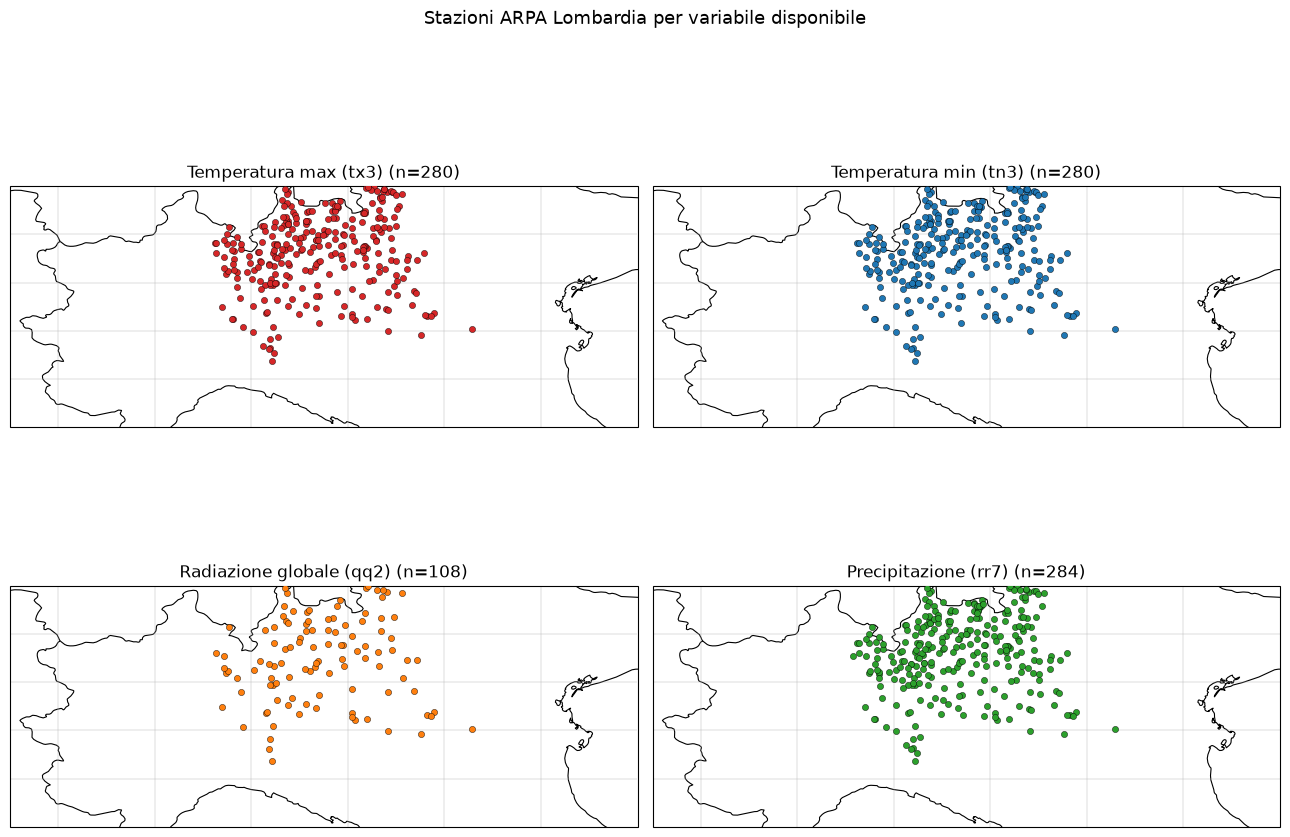

In [ ]:
# Spatial coverage by variable (same style as §4.1, here on ARPA Lombardia).
fig, axes = plt.subplots(
    2, 2, figsize=(13, 10),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

for ax, param in zip(axes.flat, PARAMETERS):
    sub = arpa_lom_stations[arpa_lom_stations["available_params"].apply(lambda lst: param in lst)]

    ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.scatter(sub["lon"], sub["lat"], c=PARAM_COLORS[param], s=20,
                edgecolor="black", linewidth=0.3, transform=ccrs.PlateCarree(), zorder=5)
    ax.gridlines(draw_labels=False, linewidth=0.3)

    ax.set_title(f"{PARAM_LABELS[param]} (n={len(sub)})")

fig.suptitle("ARPA Lombardia stations by available variable", fontsize=13)
plt.tight_layout()
plt.show()


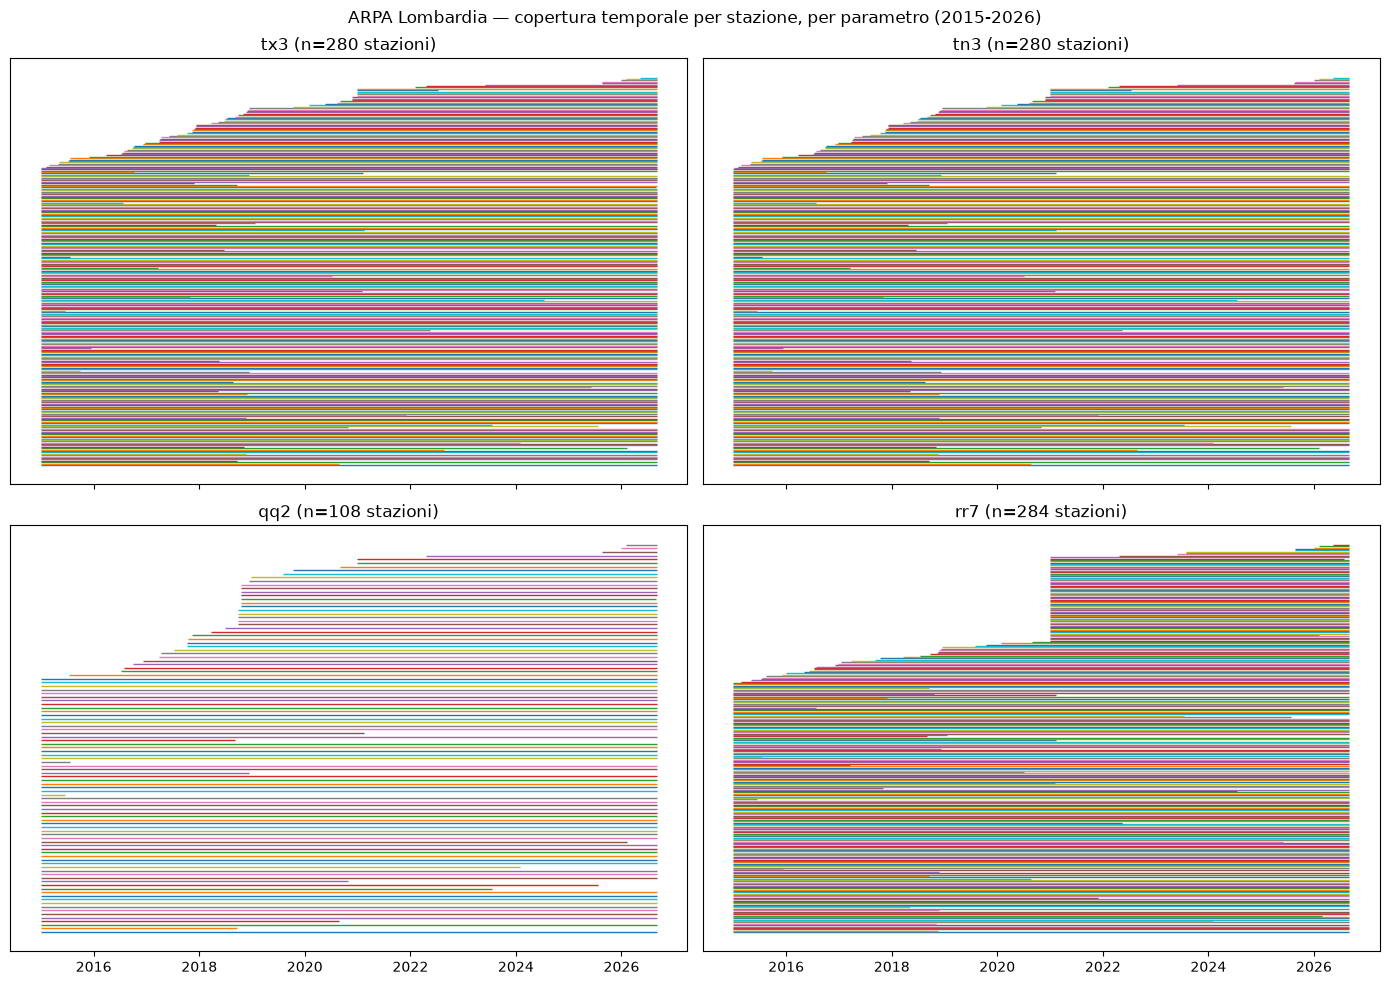

In [ ]:
# Temporal coverage per station, Gantt style (same scheme as §6 on coverage_df).
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
for ax, param in zip(axes.flat, PARAMETERS):
    sub = (arpa_lom_coverage_df[arpa_lom_coverage_df["parameter"] == param]
           .sort_values("first_obs").reset_index(drop=True))
    for i, row in sub.iterrows():
        if pd.notnull(row["first_obs"]) and pd.notnull(row["last_obs"]):
            ax.plot([row["first_obs"], row["last_obs"]], [i, i], linewidth=1.0, solid_capstyle="butt")
    ax.set_title(f"{param} (n={len(sub)} stations)")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_yticks([])

fig.suptitle("ARPA Lombardia — temporal coverage per station, by variable (2015-2026)")
plt.tight_layout()
plt.show()


In [ ]:
# Annual DataFrames (same scheme as yearly_data for ECA&D, §6), here on arpa_lom_data.
# The index is tz-naive by construction (like the CERRA "time" index, §3): unlike ECA&D it
# carries no explicit tz, but since the fix in §6bis (LOM_UTC_SHIFT) the "day" is computed
# in UTC, no longer in standard time (UTC+1) as in the native ARPA convention - so the three
# datasets are aligned on the same instant, even if only ECA&D makes it explicit with a
# tz-aware DatetimeIndex. Keeping it naive here avoids the classic
# "Cannot compare tz-naive and tz-aware" in resample/reindex.
ARPA_LOM_YEARS = list(range(2015, 2027))
arpa_lom_yearly_data = {}

for year in ARPA_LOM_YEARS:
    full_index = pd.date_range(f"{year}-01-01", f"{year}-12-31", freq="D")
    cols = {}
    for sid, params in arpa_lom_data.items():
        for param, s in params.items():
            s_year = s[s.index.year == year]
            if len(s_year) == 0:
                continue
            cols[(sid, param)] = s_year.resample("D").mean().reindex(full_index)
    if cols:
        df_year = pd.DataFrame(cols)
        df_year.columns = pd.MultiIndex.from_tuples(df_year.columns, names=["station_id", "parameter"])
        df_year = df_year.sort_index(axis=1)
    else:
        df_year = pd.DataFrame(index=full_index)
    arpa_lom_yearly_data[year] = df_year
    print(f"{year}: {df_year.shape[1]} station-variable series, {df_year.shape[0]} days")

2015: 707 serie stazione-parametro, 365 giorni
2016: 724 serie stazione-parametro, 366 giorni
2017: 756 serie stazione-parametro, 365 giorni
2018: 797 serie stazione-parametro, 365 giorni
2019: 761 serie stazione-parametro, 365 giorni
2020: 848 serie stazione-parametro, 366 giorni
2021: 843 serie stazione-parametro, 365 giorni
2022: 837 serie stazione-parametro, 365 giorni
2023: 835 serie stazione-parametro, 365 giorni
2024: 831 serie stazione-parametro, 366 giorni
2025: 835 serie stazione-parametro, 365 giorni
2026: 835 serie stazione-parametro, 365 giorni


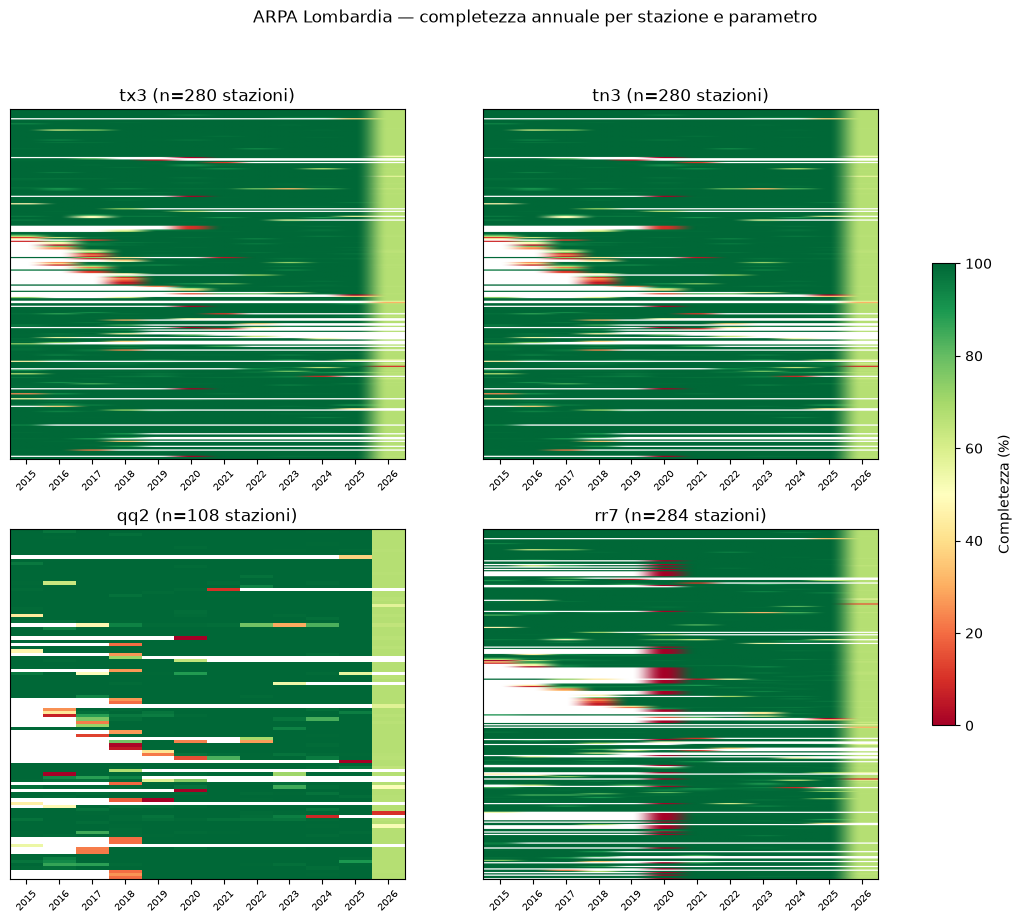

In [ ]:
# Annual completeness (%) per station x variable x year (same scheme as §6 for ECA&D).
records = []
for year, df_year in arpa_lom_yearly_data.items():
    if df_year.empty:
        continue
    is_leap = (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0))
    expected = 366 if is_leap else 365
    for sid, param in df_year.columns:
        actual = df_year[(sid, param)].dropna().shape[0]
        records.append({
            "station_id": sid,
            "parameter": param,
            "year": year,
            "completeness_pct": 100 * actual / expected,
        })

arpa_lom_completeness_long = pd.DataFrame(records)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (arpa_lom_completeness_long[arpa_lom_completeness_long["parameter"] == param]
             .pivot(index="station_id", columns="year", values="completeness_pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, fontsize=7)
    ax.set_yticks([])

fig.colorbar(im, ax=axes, label="Completeness (%)", shrink=0.6)
fig.suptitle("ARPA Lombardia — annual completeness by station and variable")
plt.show()


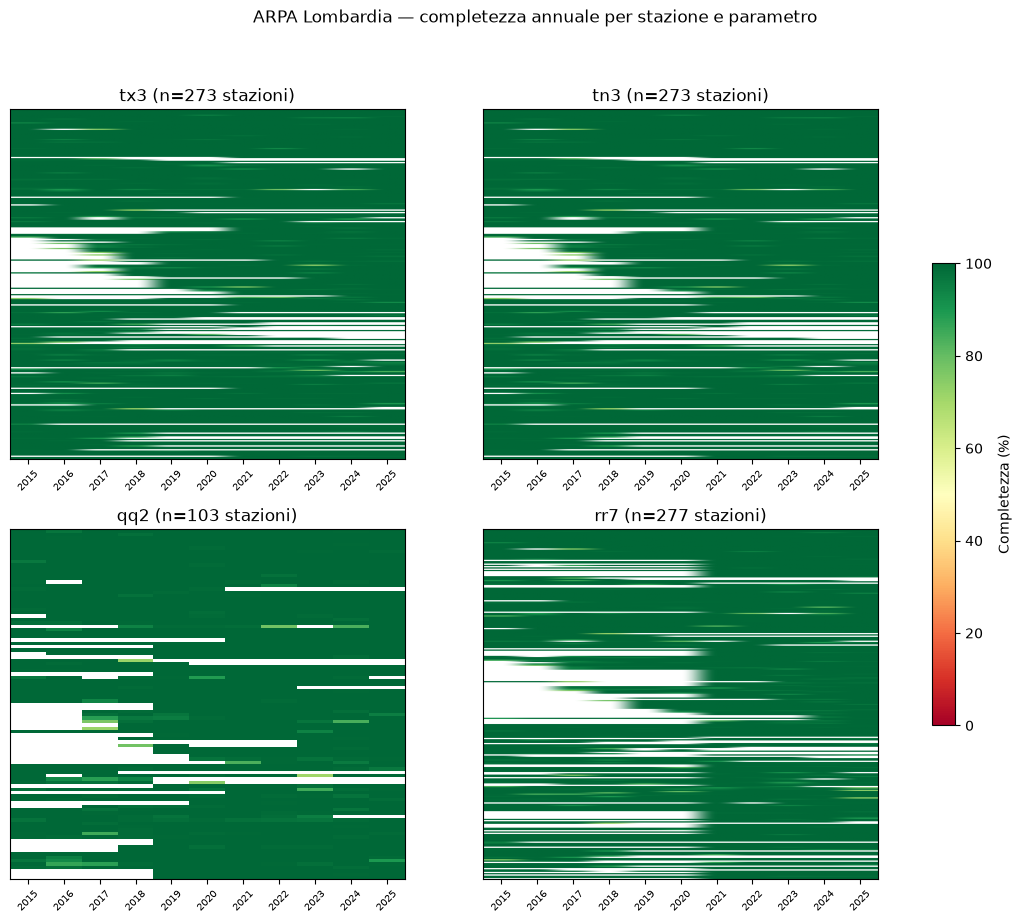

Numero di sensori con completezza >= 70%: 8420/9609 (87.6%)


In [ ]:
arpa_lom_completeness_long_70 = arpa_lom_completeness_long[arpa_lom_completeness_long["completeness_pct"] >= 70]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (arpa_lom_completeness_long_70[arpa_lom_completeness_long_70["parameter"] == param]
             .pivot(index="station_id", columns="year", values="completeness_pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, fontsize=7)
    ax.set_yticks([])

fig.colorbar(im, ax=axes, label="Completeness (%)", shrink=0.6)
fig.suptitle("ARPA Lombardia — annual completeness by station and variable")
plt.show()

num_sensors_70 = arpa_lom_completeness_long_70["station_id"].count()
print(f"Number of sensors with completeness >= 70%: {num_sensors_70}/{len(arpa_lom_completeness_long)} ({100 * num_sensors_70 / len(arpa_lom_completeness_long):.1f}%)")

### 6.5 ARPA Lombardia: year x month heatmap and completeness filter

Same evaluation as §6.3-6.4 applied to ARPA. Result expected from the heatmaps above: no seasonality (completeness ~99% in every month, for each variable). The only exception is `rr7` in December 2020: 60 sensors below the threshold. Checked on the files: 59 of them have **a single record, 2020-12-31, and no data before**, i.e. they are sensors starting on 1 January 2021 whose first record, with the 1h shift to UTC (§6bis), falls on the last day of 2020 (same artefact as the already known 2014-12-31). They are not gaps: they are months with 1 day out of 31 that must be excluded (or the leftover day discarded) before computing monthly statistics. The 60th (sensor 9933) has 7 days in December 2020 in a series started in 2015: a real isolated gap.

Completezza media per mese di calendario (2015-2025, anni con completezza >= 70%), con deviazione standard:


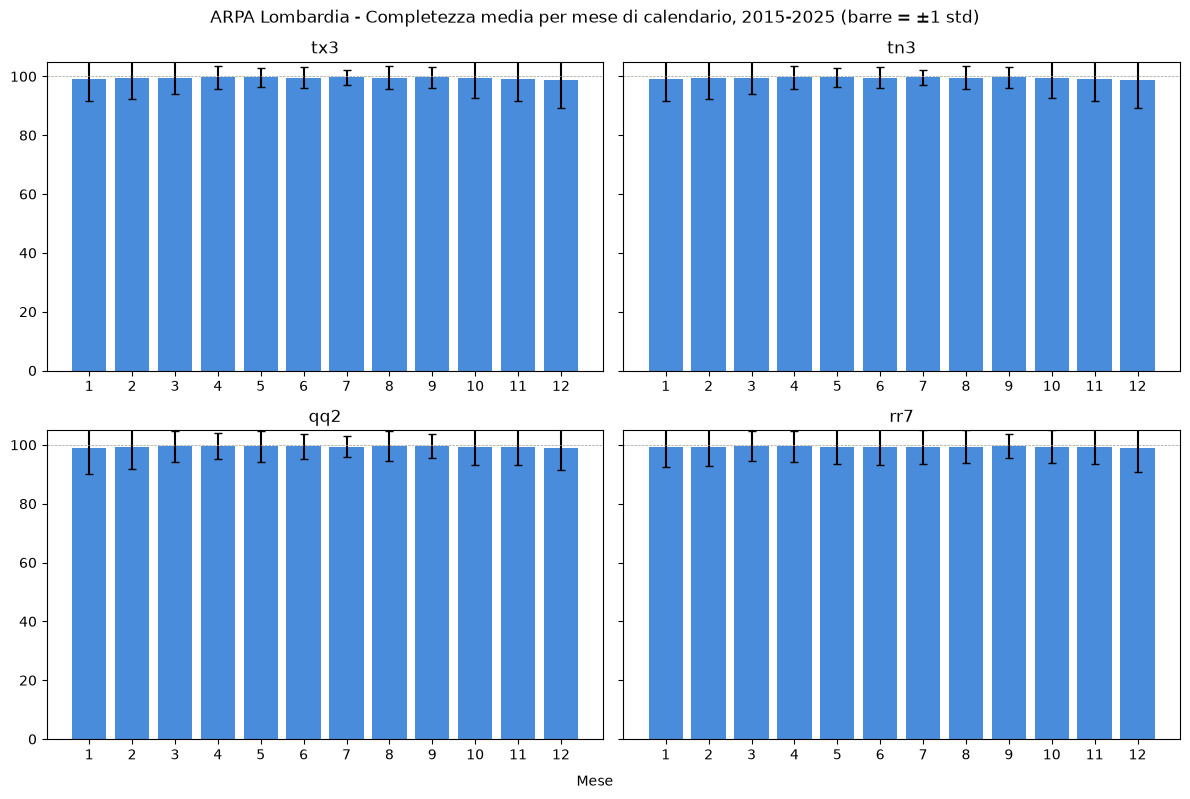

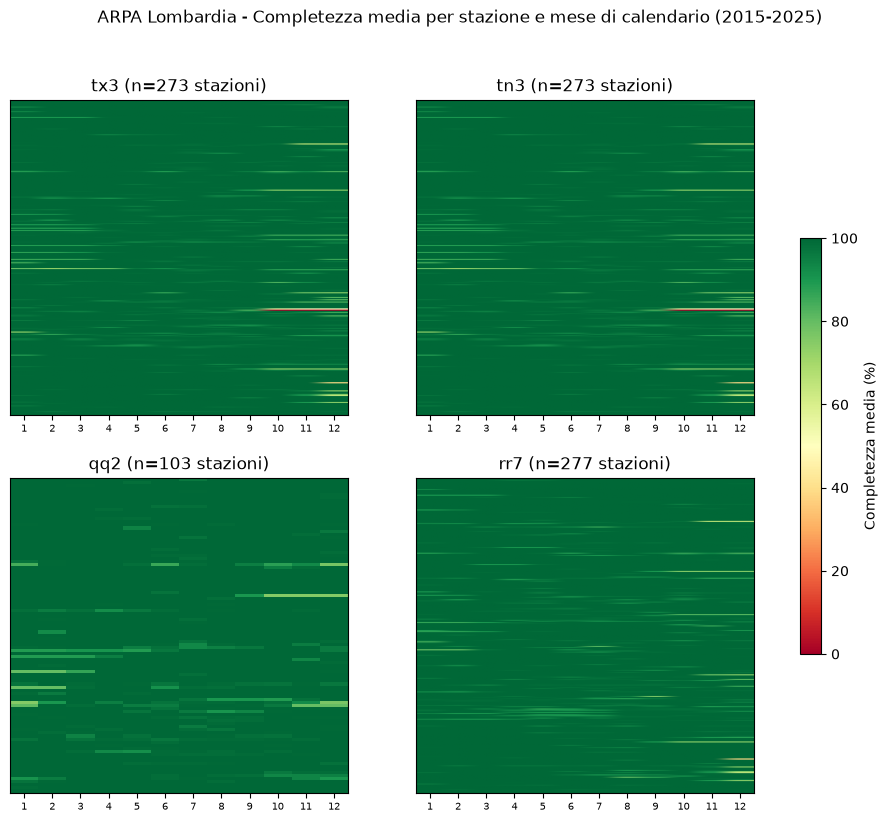

,parameter,month,mean,std
0,qq2,1,98.973299,8.978018
1,qq2,2,99.239222,7.432706
2,qq2,3,99.566278,5.251899
3,qq2,4,99.607843,4.525406
4,qq2,5,99.457848,5.304059
5,qq2,6,99.485294,4.192334
6,qq2,7,99.437517,3.631210
7,qq2,8,99.498509,5.099902
8,qq2,9,99.593838,4.183357
9,qq2,10,99.393467,6.086245


In [ ]:
# Completeness by calendar month (2015-2025), for each cached station-variable series
# (arpa_lombardia_daily_cache_utc/, §6bis): same scheme as the ECA&D analysis (§6.2).
# 2014 must be excluded: the raw file contains a leftover day "2014-12-31" (artefact of the
# 1h shift of LOM_UTC_SHIFT, §6bis), not a coverage gap.
# Mind the ids: the annual completeness (arpa_lom_completeness_long_70) uses the STATION id
# ("arpalom_<idstazione>", as arpa_lom_data), while the cached files are per SENSOR
# (<idsensore>.csv): here we go from sensor to station through the registry.
import calendar

lom_df_season = pd.read_csv(SENSORI_LOMBARDIA)
_sens = lom_df_season.set_index("idsensore")[["idstazione", "tipologia"]]
_TIPOLOGIA_TO_PARAMS = {"Temperatura": ["tx3", "tn3"], "Precipitazione": ["rr7"], "Radiazione Globale": ["qq2"]}

arpa_files = glob.glob(os.path.join(CACHE_LOMBARDIA, "*.csv"))
_rows = []
for f in arpa_files:
    sid = int(os.path.basename(f).replace(".csv", ""))
    if sid not in _sens.index:
        continue
    staz, tipologia = _sens.loc[sid, "idstazione"], _sens.loc[sid, "tipologia"]
    df = pd.read_csv(f, parse_dates=["giorno"])
    if df.empty:
        continue
    df = df[(df["giorno"].dt.year >= 2015) & (df["giorno"].dt.year <= 2025)]
    if df.empty:
        continue
    df["year"] = df["giorno"].dt.year
    df["month"] = df["giorno"].dt.month
    counts = df.groupby(["year", "month"]).size()
    for param in _TIPOLOGIA_TO_PARAMS[tipologia]:
        for (y, m), n in counts.items():
            _rows.append({"station_id": f"arpalom_{staz}", "parameter": param, "year": y, "month": m, "n": n})

# same station with several sensors of the same type: the most complete one is kept
arpa_monthly = pd.DataFrame(_rows).groupby(["station_id", "parameter", "year", "month"], as_index=False)["n"].max()
arpa_monthly["expected"] = arpa_monthly["month"].map(_days_in_month)
arpa_monthly["pct"] = (100 * arpa_monthly["n"] / arpa_monthly["expected"]).clip(upper=100)

# Only the station-variable-year combinations with annual completeness >= 70% (cell above).
# For those years the grid of the 12 months is rebuilt, so a month without any data
# counts 0% instead of disappearing from the mean.
_sel = arpa_lom_completeness_long_70[["station_id", "parameter", "year"]]
_sel = _sel[_sel["year"].between(2015, 2025)]
arpa_monthly_sel = (_sel.merge(pd.DataFrame({"month": range(1, 13)}), how="cross")
                    .merge(arpa_monthly[["station_id", "parameter", "year", "month", "n"]],
                           on=["station_id", "parameter", "year", "month"], how="left")
                    .fillna({"n": 0}))
arpa_monthly_sel["expected"] = [calendar.monthrange(y, m)[1]
                                for y, m in zip(arpa_monthly_sel["year"], arpa_monthly_sel["month"])]
arpa_monthly_sel["pct"] = (100 * arpa_monthly_sel["n"] / arpa_monthly_sel["expected"]).clip(upper=100)

arpa_monthly_agg = arpa_monthly_sel.groupby(["parameter", "month"])["pct"].agg(["mean", "std"]).reset_index()
print("Mean completeness by calendar month (2015-2025, years with completeness >= 70%), with standard deviation:")

# Bar chart: mean completeness by month, with ±1 std - one panel per variable.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, param in zip(axes.flat, PARAMETERS):
    sub = arpa_monthly_agg[arpa_monthly_agg["parameter"] == param].sort_values("month")
    ax.bar(sub["month"], sub["mean"], yerr=sub["std"], color="#2a78d6", alpha=0.85, capsize=3)
    ax.set_title(param)
    ax.set_xticks(range(1, 13))
    ax.set_ylim(0, 105)
    ax.axhline(100, color="#9a9a94", linewidth=0.5, linestyle="--")
fig.suptitle("ARPA Lombardia - Mean completeness by calendar month, 2015-2025 (bars = ±1 std)")
fig.text(0.5, 0.01, "Month", ha="center")
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

# Station x month heatmap (same RdYlGn style as the other heatmaps of the notebook):
# here one sees WHICH stations a possible monthly pattern comes from, not only whether it
# exists on average - the difference that in the bar chart stays hidden inside the error bars.
arpa_station_month = arpa_monthly_sel.groupby(["station_id", "parameter", "month"])["pct"].mean().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    pivot = (arpa_station_month[arpa_station_month["parameter"] == param]
             .pivot(index="station_id", columns="month", values="pct"))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_title(f"{param} (n={pivot.shape[0]} stations)")
    ax.set_xticks(range(12))
    ax.set_xticklabels(range(1, 13), fontsize=7)
    ax.set_yticks([])
fig.colorbar(im, ax=axes, label="Mean completeness (%)", shrink=0.6)
fig.suptitle("ARPA Lombardia - Mean completeness by station and calendar month (2015-2025)")
plt.show()

arpa_monthly_agg

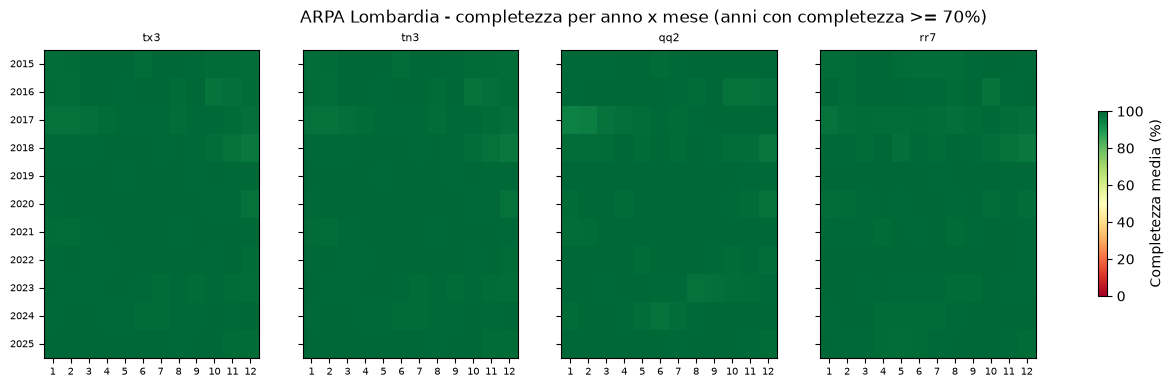

Mesi stazione-parametro validi (>= 70%): 101589 / 102290 (99.3%)
Mesi scartati per parametro e anno:
parameter  qq2  rr7  tn3  tx3
year                         
2015         5   20   19   19
2016        10   25   26   26
2017        17   23   27   27
2018        22   28   27   27
2019         6   12    7    7
2020         6   71   16   16
2021         1   12    8    8
2022         6    9   10   10
2023         8   14   17   17
2024         4   10   13   13
2025         6   20   13   13
rr7, mesi con piu' stazioni sotto soglia:
year  month
2020  12       60
2016  10        8
2018  5         5
      11        5
2015  6         5
dtype: int64


In [ ]:
# Year x month heatmap (mean over the stations), one panel per variable
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
im = None
for ax, param in zip(axes.flat, PARAMETERS):
    sub = arpa_monthly_sel[arpa_monthly_sel["parameter"] == param]
    pv = (sub.pivot_table(index="year", columns="month", values="pct", aggfunc="mean")
          .reindex(index=range(2015, 2026), columns=range(1, 13)))
    im = ax.imshow(pv.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, interpolation="nearest")
    ax.set_title(f"{param}", fontsize=8)
    ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13), fontsize=7)
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index, fontsize=7)
fig.colorbar(im, ax=axes, label="Mean completeness (%)", shrink=0.6)
fig.suptitle("ARPA Lombardia - completeness by year x month (years with completeness >= 70%)")
plt.show()

# Monthly completeness filter (same threshold as §6.3): station-months below the threshold are
# excluded from the downstream statistics.
arpa_monthly["ok"] = arpa_monthly["pct"] >= MIN_MONTH_COMPLETENESS
arpa_month_ok = arpa_monthly[arpa_monthly["ok"]]
print(f"Valid station-variable months (>= {MIN_MONTH_COMPLETENESS}%): {len(arpa_month_ok)} / {len(arpa_monthly)} "
      f"({100 * len(arpa_month_ok) / len(arpa_monthly):.1f}%)")
print("Discarded months by variable and year:")
print((~arpa_monthly["ok"]).groupby([arpa_monthly["parameter"], arpa_monthly["year"]]).sum().unstack(0))
print("rr7, months with the most stations below the threshold:")
print(arpa_monthly[(arpa_monthly["parameter"] == "rr7") & ~arpa_monthly["ok"]].groupby(["year", "month"]).size().sort_values(ascending=False).head(5))

### 6.6 Training table: Aurora + observations

One row per station, day and variable: observation (`obs`), daily Aurora forecast at the station location (`aurora`, in physical units), the other Aurora variables at the same point, DEM elevation and `residual = obs - aurora`, which is the target of the downscaling head.

- **Aurora**: daily fields cropped to the AOI (`aurora_campi/`, extracted on Lightning with `extract_aurora_campi.py`), **bilinearly interpolated at the exact location of each station**: same procedure as the high-resolution maps, so training and maps see the same input. Besides the value of the variable, the head receives the other Aurora variables at the point (the four main variables, temperature and humidity aloft, boundary layer, cloudiness, wind, pressure, snow, geopotential at 500 hPa) and the difference between the station elevation and the Aurora elevation (`AURORA_FEATURE`). Choice checked with `esperimento_bilineare.py`: compared with the nearest cell with the variable alone, -12/-16% error for all variables, in all folds. **No latitude and longitude**: with the coordinates the network learns corrections tied to the station locations and, in a region never seen, extrapolates them unstably.
- **Units**: rr7 and qq2 are raw; the scale factor (sum of observations / sum of Aurora) is computed **only on the training rows** and also applied to the test, which has the same units. Saved in `fattori_scala_aurora.json` for the maps.
- **Observations**: rebuilt here from the data downloaded in the notebook (`ecad_padania_raw_cache/`, `arpa_lombardia_daily_cache_utc/`, `arpa_piemonte_daily_cache/`, `arpae_daily`), with an explicit QC, the same for all sources: physical range and, for ARPA Lombardia, at least 80% of the expected readings in the day. **No z-score filter**: the previous pipeline removed the values with |z| > 4 per station and month, i.e. exactly the days of heavy rain; the obvious errors are removed later, with the checks of §7. ECA&D must be shifted by -1 day (the API puts the date at the end of the interval, see §2).
- **Coordinates**: ARPA Lombardia with the UTM coordinates of the registry (lat/lng are wrong for 8 stations, see §7.1), Monte Cimone on the summit (`CORREZIONI_MANUALI`). **Elevation**: GLO-30 DEM at the point.
- **Split**: all the `TRAIN_YEARS` are `train` (validation with the region x year cross-validation, `cv_regione_anno.py`); Piedmont is `test`, to be used only once at the end, and is saved in a separate table (`test_table_aurora.parquet`). The test rows exist only if the Aurora fields of the `TEST_YEARS` are available.

In [ ]:
# Configuration
from campi_aurora import carica_campi, interpola_punti
from descrittori_terreno import FORMA_RILIEVO, dem_elevation, descrittori

TRAIN_YEARS = [2016, 2022, 2023]   # all in training (validation: region x year CV)
TEST_YEARS = [2020]                # ARPA Piemonte, final test
TABLE_OUT = TABELLA_TRAINING
TEST_TABLE_OUT = TABELLA_TEST   # Piedmont, kept separate from training
FATTORI_OUT = FATTORI_SCALA   # read by mappa_downscaling.py
AURORA_COL = {"tx3": "tx3_aurora", "tn3": "tn3_aurora", "rr7": "rr7_aurora_raw", "qq2": "qq2_aurora_raw"}
AURORA_DA_SCALARE = {"rr7", "qq2"}  # tx3/tn3 are already in degrees C
TABLE_QC = {"tx3": (-30, 50), "tn3": (-40, 35), "qq2": (0, 450), "rr7": (0, 300)}  # clip of Aurora
# Wrong coordinates in the source registry, corrected by hand: uid -> (lat, lon)
CORREZIONI_MANUALI = {
    "ecad_0002082": (44.1942, 10.6992),  # Monte Cimone, summit 2165 m (ECA&D: 44.2, 10.7, rounded to 0.1 degrees)
}

# Aurora variables given to the head besides the value of the variable itself (see the text above).
# a_<param> = the four main variables in physical units; dz = station elevation - Aurora elevation.
AURORA_FEATURE = ["a_tx3", "a_tn3", "a_rr7", "a_qq2",
                  "sup_2t_media", "sup_msl_media", "sup_10u_media", "sup_10v_media", "sup_vento10_max",
                  "sup_i10fg_media", "sup_blh_media", "sup_ttr_1h_media", "sup_scaled_sf_1h_media",
                  "atm_t_925", "atm_t_850", "atm_t_700", "atm_t_500", "atm_q_925", "atm_q_850", "atm_q_700",
                  "atm_z_500", "atm_u_850", "atm_v_850", "dz"]
# Terrain shape around the station (descrittori_terreno.py, GLO-30 DEM at ~90 m): position in the
# terrain at 3 scales (tpi_*), slope, aspect. Used by the model for tn3 and qq2
# (train_downscaling_head.py, FEATURE_EXTRA); the maps compute it in the same way in each pixel.
# variables to read from the fields (the pressure-level ones have all levels: only those used are kept)
_CAMPI_VAR = (list(AURORA_COL.values()) + ["orog_aurora"]
              + [c for c in AURORA_FEATURE if c.startswith("sup_")]
              + ["atm_t_media", "atm_q_media", "atm_z_media", "atm_u_media", "atm_v_media"])
_COL_PUNTI = (list(AURORA_COL.values()) + ["orog_aurora"]
              + [c for c in AURORA_FEATURE if c.startswith(("sup_", "atm_"))])

In [ ]:
# Daily observations rebuilt from the data downloaded in this notebook, with an explicit QC,
# the same for all sources:
#  - physical range (OBS_QC). Precipitation up to 800 mm: on the Ligurian-Piedmontese Apennines
#    there have been days above 700 mm. The ECA&D qq2 values in another unit (up to ~30000) fall here.
#  - ARPA Lombardia: a day is valid with at least MIN_FRAZ_LETTURE of the readings expected for the
#    sensor frequency in that period (144 every 10 minutes, 24 hourly: 25 sensors switch from
#    one frequency to the other). With fewer readings the precipitation sum and the radiation
#    mean are underestimated. ARPAE already has the analogous rule (20 hours out of 24, §6.3).
#  - NO z-score filter. The previous pipeline removed all the values with |z| > 4 with respect
#    to the mean and standard deviation of the same station in the same month: for precipitation,
#    exactly the days of heavy rain (~21 thousand ECA&D, ~15 thousand in the Piedmont test, 2015-2024).
#    The real extremes must be kept; the obvious errors are removed later, with the checks of §7.
import ast
from pyproj import Transformer

OBS_QC = {"tx3": (-30, 50), "tn3": (-40, 35), "qq2": (0, 450), "rr7": (0, 800)}
MIN_FRAZ_LETTURE = 0.8
ANNI_OBS = set(TRAIN_YEARS) | set(TEST_YEARS)
_oss = []

# ECA&D: dates at the end of the interval (-P1D) -> UTC day D-1; coordinates from the API registry (§2)
_anag = pd.read_csv(STAZIONI_ECAD).set_index("station_id")
for f in glob.glob(os.path.join(CACHE_ECAD, "*.csv")):
    sid, param = os.path.basename(f).replace(".csv", "").split("__")
    d = pd.read_csv(f)
    if d.empty or sid not in _anag.index:
        continue
    d["date"] = pd.to_datetime(d["date"], utc=True).dt.tz_convert(None) - pd.Timedelta(days=1)
    d = d[d["date"].dt.year.isin(ANNI_OBS)].dropna(subset=[param])
    _oss.append(pd.DataFrame({"uid": sid, "source": "ecad", "parameter": param, "date": d["date"].values,
                              "obs": d[param].values, "lat": _anag.loc[sid, "lat"], "lon": _anag.loc[sid, "lon"]}))

# ARPA Lombardia: UTC day (1h shift, §6bis); UTM coordinates of the registry (lat/lng are
# wrong for 8 stations, see §7.1). One uid per sensor, as in the Aurora extractions.
_reg = pd.read_csv(SENSORI_LOMBARDIA).set_index("idsensore")
_reg["lon_utm"], _reg["lat_utm"] = Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True).transform(
    _reg["cgb_est"].values, _reg["cgb_nord"].values)
_COL = {"Temperatura": [("tx3", "vmax"), ("tn3", "vmin")], "Precipitazione": [("rr7", "vsum")],
        "Radiazione Globale": [("qq2", "vmed")]}
for f in glob.glob(os.path.join(CACHE_LOMBARDIA, "*.csv")):
    s = int(os.path.basename(f).replace(".csv", ""))
    d = pd.read_csv(f)
    if d.empty or s not in _reg.index:
        continue
    d["giorno"] = pd.to_datetime(d["giorno"])
    d = d.sort_values("giorno")
    # expected sensor frequency: rolling median of the readings per day (24 if hourly)
    _attese = np.where(d["n"].rolling(31, center=True, min_periods=1).median() <= 30, 24, 144)
    d = d[(d["n"] >= MIN_FRAZ_LETTURE * _attese) & d["giorno"].dt.year.isin(ANNI_OBS)]
    for param, col in _COL[_reg.loc[s, "tipologia"]]:
        _oss.append(pd.DataFrame({"uid": f"arpalom_{s}", "source": "arpa_lom", "parameter": param,
                                  "date": d["giorno"].values, "obs": d[col].values,
                                  "lat": _reg.loc[s, "lat_utm"], "lon": _reg.loc[s, "lon_utm"]}))

# ARPAE (Emilia-Romagna radiation, §6.3): already daily on the UTC day, with at least 20 valid hours
_ad = arpae_daily[arpae_daily["date"].dt.year.isin(ANNI_OBS)]
_oss.append(pd.DataFrame({"uid": _ad["station_id"].values, "source": "arpae", "parameter": "qq2",
                          "date": _ad["date"].values, "obs": _ad["qq2"].values,
                          "lat": _ad["lat"].values, "lon": _ad["lon"].values}))

# ARPA Piemonte: ARPA daily data (day 00-24 UTC); radiation in MJ/m2 -> mean W/m2.
# Coordinates from the ARPA Piemonte registry (API), saved once in arpa_piemonte_stazioni.csv.
_PIE_ANAG = STAZIONI_PIEMONTE
if not os.path.exists(_PIE_ANAG):
    _r = requests.get("https://utility.arpa.piemonte.it/meteoidro/stazione_meteorologica/",
                      params={"page": 1}, timeout=60).json()
    pd.DataFrame([{"uid": st["fk_id_punto_misura_meteo"].rstrip("/").split("/")[-1],
                   "nome": st["denominazione"], "lat": st["latitudine_n_wgs84_d"],
                   "lon": st["longitudine_e_wgs84_d"], "quota": st["quota_stazione"]}
                  for st in _r["results"]]).drop_duplicates("uid", keep="last").to_csv(_PIE_ANAG, index=False)
_pie = pd.read_csv(_PIE_ANAG).set_index("uid")
_PIE_COL = {"tmax": ("tx3", 1.0), "tmin": ("tn3", 1.0), "ptot": ("rr7", 1.0), "rtot": ("qq2", 1e6 / 86400)}
for f in glob.glob(os.path.join(CACHE_PIEMONTE, "*.csv")):
    u = os.path.basename(f).replace(".csv", "")
    d = pd.read_csv(f, parse_dates=["data"])
    if d.empty or u not in _pie.index:
        continue
    d = d[d["data"].dt.year.isin(ANNI_OBS)]
    for col, (param, fattore) in _PIE_COL.items():
        dd = d.dropna(subset=[col])
        _oss.append(pd.DataFrame({"uid": u, "source": "arpa_piemonte", "parameter": param,
                                  "date": dd["data"].values, "obs": dd[col].values * fattore,
                                  "lat": _pie.loc[u, "lat"], "lon": _pie.loc[u, "lon"]}))

osservazioni = pd.concat(_oss, ignore_index=True)
_n0 = len(osservazioni)
_lo = osservazioni["parameter"].map({k: v[0] for k, v in OBS_QC.items()})
_hi = osservazioni["parameter"].map({k: v[1] for k, v in OBS_QC.items()})
osservazioni = osservazioni[osservazioni["obs"].between(_lo, _hi)].reset_index(drop=True)
print(f"observations: {len(osservazioni)} ({_n0 - len(osservazioni)} removed outside the physical range)")

# Coordinates corrected by hand (Monte Cimone: ECA&D rounds them to 0.1 degrees, the station is on the summit)
for _u, (_la, _lo2) in CORREZIONI_MANUALI.items():
    osservazioni.loc[osservazioni["uid"] == _u, ["lat", "lon"]] = [_la, _lo2]

# No training station in the test region (Piedmont), which must stay never seen
_st = osservazioni.drop_duplicates("uid")[["uid", "lat", "lon"]]
_g = gpd.sjoin(gpd.GeoDataFrame(_st, geometry=gpd.points_from_xy(_st["lon"], _st["lat"]), crs="EPSG:4326"),
               regions_gdf[["reg_name", "geometry"]], how="left", predicate="within")
_in_test = set(_g.loc[_g["reg_name"].isin(TEST_REGIONS), "uid"])
_fuori = (osservazioni["source"] != "arpa_piemonte") & osservazioni["uid"].isin(_in_test)
print(f"non-Piedmont stations inside the test region, removed from training: {sorted(_in_test - set(_pie.index))}")
osservazioni = osservazioni[~_fuori].reset_index(drop=True)
osservazioni.groupby(["source", "parameter"]).size().unstack(fill_value=0)

In [ ]:
# Aurora bilinearly interpolated at the location of each station, from the daily fields (aurora_campi/).
# Each station takes Aurora at its own point: there is no longer any need to borrow the series of
# another station in the same cell (ARPAE, stations with corrected coordinates).
_stazioni = osservazioni.drop_duplicates("uid")[["uid", "source", "lat", "lon"]]
_aurora_punti = []
for _anni, _quali, _nome in [(TRAIN_YEARS, _stazioni[_stazioni["source"] != "arpa_piemonte"], "training"),
                              (TEST_YEARS, _stazioni[_stazioni["source"] == "arpa_piemonte"], "test")]:
    _disp = [y for y in _anni if glob.glob(os.path.join(CAMPI_AURORA, f"aurora_campi_{y}-*.nc"))]
    if set(_anni) - set(_disp):
        print(f"WARNING: the Aurora fields are missing for {_nome} {sorted(set(_anni) - set(_disp))} "
              f"(extract_aurora_campi.py on Lightning): those rows do not enter the table")
    if not _disp:
        continue
    _campi = carica_campi(_disp, variabili=_CAMPI_VAR)
    _p = interpola_punti(_campi, _quali["lat"], _quali["lon"], "linear", ids=_quali["uid"])
    _p = _p.rename(columns={"punto": "uid"})[["uid", "date"] + _COL_PUNTI]
    _aurora_punti.append(_p.astype({c: "float32" for c in _COL_PUNTI}))
    print(f"Aurora for {_nome} {_disp}: {len(_p)} station-days, {_quali['uid'].nunique()} stations")
aurora_punti = pd.concat(_aurora_punti, ignore_index=True)

In [ ]:
# Table rows: observation + Aurora at the same point and day, DEM elevation, scale factors
_meta = osservazioni.drop_duplicates("uid").set_index("uid")[["lat", "lon"]]
_meta["elev"] = dem_elevation(_meta["lat"].values, _meta["lon"].values)
_forma = descrittori(_meta["lat"].values, _meta["lon"].values, con_distanze=False)[FORMA_RILIEVO]
_meta = _meta.join(_forma.set_axis(_meta.index).astype("float32"))
_obs = osservazioni.drop(columns=["lat", "lon"]).join(_meta, on="uid")
_obs = _obs[((_obs["source"] != "arpa_piemonte") & _obs["date"].dt.year.isin(TRAIN_YEARS))
            | ((_obs["source"] == "arpa_piemonte") & _obs["date"].dt.year.isin(TEST_YEARS))]

_lungo = aurora_punti.melt(id_vars=["uid", "date"], value_vars=list(AURORA_COL.values()),
                           var_name="col", value_name="aurora_raw")
_lungo["parameter"] = _lungo["col"].map({v: k for k, v in AURORA_COL.items()})
tabella = _obs.merge(_lungo.drop(columns="col"), on=["uid", "date", "parameter"], how="inner")
tabella["split"] = np.where(tabella["source"] == "arpa_piemonte", "test", "train")

# Raw -> physical units factor: only from the training rows (sum of obs / sum of Aurora),
# also applied to the test (same raw units). Clip of Aurora to the physical ranges, residual.
fattori_scala = {"tx3": 1.0, "tn3": 1.0}
for _p in AURORA_DA_SCALARE:
    _m = (tabella["parameter"] == _p) & (tabella["split"] == "train")
    fattori_scala[_p] = float(tabella.loc[_m, "obs"].sum() / tabella.loc[_m, "aurora_raw"].sum())
tabella["aurora"] = tabella["aurora_raw"] * tabella["parameter"].map(fattori_scala)
for _p, (_lo, _hi) in TABLE_QC.items():
    _m = tabella["parameter"] == _p
    tabella.loc[_m, "aurora"] = tabella.loc[_m, "aurora"].clip(_lo, _hi)
tabella["residual"] = tabella["obs"] - tabella["aurora"]
print("Aurora scale factors (from training):", {k: f"{v:.6g}" for k, v in fattori_scala.items()})

# The other Aurora variables at the point: the four main ones in physical units and dz
_extra = aurora_punti.copy()
for _p, _c in AURORA_COL.items():
    _extra[f"a_{_p}"] = (_extra[_c] * fattori_scala[_p]).clip(*TABLE_QC[_p]).astype("float32")
tabella = tabella.merge(_extra[["uid", "date", "orog_aurora"] + [c for c in AURORA_FEATURE if c != "dz"]],
                        on=["uid", "date"], how="left")
tabella["dz"] = (tabella["elev"] - tabella["orog_aurora"]).astype("float32")
print(f"rows: train {int((tabella['split'] == 'train').sum())}, test {int((tabella['split'] == 'test').sum())}")

In [ ]:
# Saving the table and the scale factors
TABLE_COLS = (["uid", "source", "parameter", "date", "obs", "aurora", "residual", "lat", "lon", "elev", "split"]
              + AURORA_FEATURE + FORMA_RILIEVO)
tabella = tabella.dropna(subset=["lat", "lon", "elev", "aurora"] + AURORA_FEATURE + FORMA_RILIEVO)[TABLE_COLS]
# training and test in two separate files: the test must never end up in training by mistake
tabella[tabella["split"] == "train"].to_parquet(TABLE_OUT, index=False)
tabella[tabella["split"] == "test"].to_parquet(TEST_TABLE_OUT, index=False)
json.dump({"fattori_scala": fattori_scala, "aurora_feature": AURORA_FEATURE, "table_qc": TABLE_QC,
           "forma_rilievo": FORMA_RILIEVO},
          open(FATTORI_OUT, "w"), indent=1)
print(f"saved {TABLE_OUT}: {int((tabella['split'] == 'train').sum())} rows, "
      f"{TEST_TABLE_OUT}: {int((tabella['split'] == 'test').sum())} rows, and {FATTORI_OUT}")
if not (tabella["split"] == "test").any():
    print("WARNING: no test rows (the Aurora fields of the TEST_YEARS are needed)")
tabella.groupby(["split", "source", "parameter"]).size().unstack(fill_value=0)

### 7.1 Outliers in the daily series, all sources (2016, 2022, 2023)

The QC of §7 counts the problems per series and only on ECA&D. Here the check is extended to **all the sources** (ECA&D, ARPA Lombardia, ARPA Piemonte, ARPAE) for the years used in training, and it marks **the single suspicious values** with a flag, without removing anything: what to discard is decided afterwards, by looking at the results.

Principles:
- **Flag, do not delete.** The real extreme events (heat waves, cloudbursts) are exactly those the model must learn.
- **Aurora is not part of any criterion.** Discarding the days on which the observation is far from Aurora would remove exactly the cases where Aurora is most wrong, making the model look better than it is.
- **Different criteria per variable:** for tx3/tn3/qq2 a robust z-score on the seasonal anomaly + comparison with the neighbouring stations on the same day (an extreme value that the neighbours also have is a real event, an isolated one is suspicious); for qq2 also the physical clear-sky limit (SARAH `SISC`); for rr7, which is almost always zero and does not lend itself to a z-score, consistency checks with the neighbours and accumulation after a gap.
- The **station registry** must be checked too: a wrong coordinate matters more than a few anomalous values.

Data source: the table of §6.6 (`training_table_aurora.parquet`), which already has all the sources with dates on the UTC day (ECA&D already shifted by -1 day), the corrected coordinates and the DEM elevation.

In [32]:
# Observations of all the sources for the training years ("obs" only: Aurora is not needed here).
import glob
import re
import xarray as xr

OUT_YEARS = TRAIN_YEARS  # training years of the table (§6.6)
_cols = ["uid", "source", "parameter", "date", "obs", "lat", "lon", "elev", "split"]
obs_all = pd.read_parquet(TABLE_OUT, columns=_cols)
obs_all = obs_all[obs_all["date"].dt.year.isin(OUT_YEARS)]
# Test (ARPA Piemonte, TEST_YEARS): the checks are done on the COMPLETE daily series of the
# observations (§6.6), not on the rows of the test table, which has Aurora only one day every 2.
# With a gap every two days each heavy rain looked like an "accumulation after a gap" (468 of the
# 490 suspicious rr7 values in Piedmont) and stuck sequences could not be seen.
if os.path.exists(TEST_TABLE_OUT):
    _st_test = pd.read_parquet(TEST_TABLE_OUT, columns=["uid", "lat", "lon", "elev"]).drop_duplicates("uid")
    _oss_test = osservazioni[(osservazioni["source"] == "arpa_piemonte")
                             & osservazioni["date"].dt.year.isin(TEST_YEARS)]
    _oss_test = _oss_test.drop(columns=["lat", "lon"]).merge(_st_test, on="uid").assign(split="test")
    obs_all = pd.concat([obs_all, _oss_test[_cols]], ignore_index=True)
obs_all = obs_all.reset_index(drop=True)
out_stations = obs_all.drop_duplicates("uid")[["uid", "source", "lat", "lon", "elev"]].reset_index(drop=True)

print(f"{len(obs_all)} observations, {len(out_stations)} stations, years {OUT_YEARS} + Piedmont test "
      f"{sorted(obs_all.loc[obs_all['split'] == 'test', 'date'].dt.year.unique())}")
print(obs_all.groupby(["source", "parameter"]).size().unstack().fillna(0).astype(int))

2542211 osservazioni, 1578 stazioni, anni [2016, 2022, 2023] + test Piemonte [np.int32(2020)]
parameter         qq2     rr7     tn3     tx3
source                                       
arpa_lom        94047  247584  251968  251978
arpa_piemonte   22094  104377  100582  100589
arpae           21241       0       0       0
ecad           152941  446991  373648  374171


source     arpa_lom  arpa_piemonte  arpae  ecad
parameter                                      
qq2             103             62     29   148
rr7             275            287      0   521
tn3             270            278      0   415
tx3             270            278      0   416


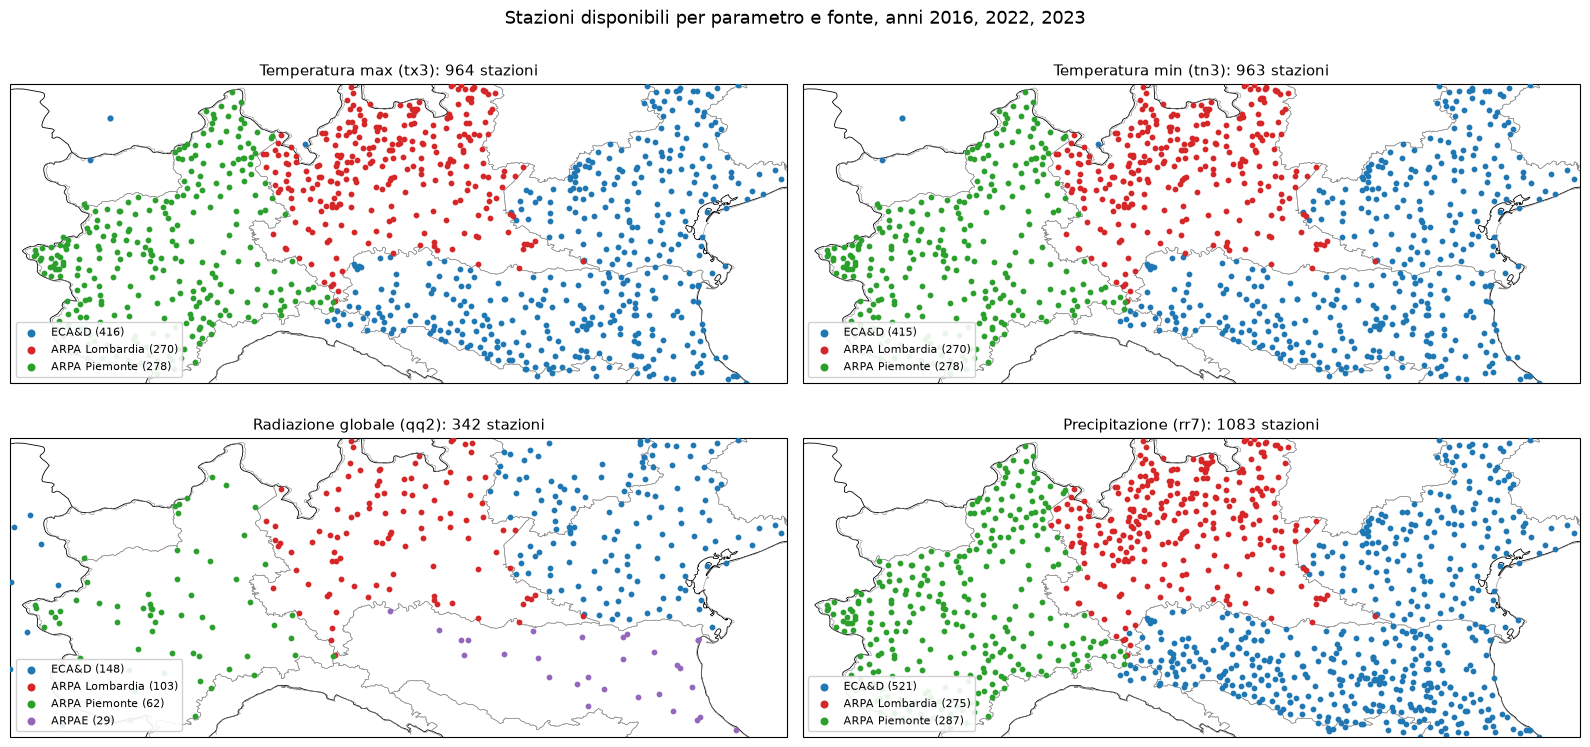

In [33]:
# Map of all the available stations by variable, coloured by source.
# Stations = those with at least one observation in the OUT_YEARS in the training table
# (coordinates already corrected in §6.6: UTM for ARPA Lombardia, CORREZIONI_MANUALI).
# Natural Earth coastlines and borders read with geopandas (not with cfeature: see the note on the ARPAE map).
import cartopy.io.shapereader as shpreader

FONTI_COLORI = {"ecad": "#1f77b4", "arpa_lom": "#d62728", "arpa_piemonte": "#2ca02c", "arpae": "#9467bd"}
FONTI_NOMI = {"ecad": "ECA&D", "arpa_lom": "ARPA Lombardia", "arpa_piemonte": "ARPA Piemonte", "arpae": "ARPAE"}
_st_param = obs_all.drop_duplicates(["uid", "parameter"])[["uid", "source", "parameter", "lat", "lon"]]
print(_st_param.groupby(["parameter", "source"]).size().unstack(fill_value=0))

_coste = gpd.read_file(shpreader.natural_earth("10m", "physical", "coastline"))
_confini = gpd.read_file(shpreader.natural_earth("10m", "cultural", "admin_0_boundary_lines_land"))
_tr = ccrs.PlateCarree()

fig, axes = plt.subplots(2, 2, figsize=(16, 8), subplot_kw={"projection": _tr})
for ax, param in zip(axes.flat, ["tx3", "tn3", "qq2", "rr7"]):
    # aspect=None: geopandas does not touch the axis proportions (otherwise the panels after
    # the first one are distorted in different ways)
    _coste.plot(ax=ax, color="black", linewidth=0.6, aspect=None)
    _confini.plot(ax=ax, color="black", linewidth=0.6, aspect=None)
    regions_gdf.boundary.plot(ax=ax, color="#888888", linewidth=0.4, aspect=None)
    sub = _st_param[_st_param["parameter"] == param]
    for fonte, col in FONTI_COLORI.items():
        s = sub[sub["source"] == fonte]
        if len(s):
            ax.scatter(s["lon"], s["lat"], s=10, color=col, transform=_tr, zorder=5,
                       label=f"{FONTI_NOMI[fonte]} ({len(s)})")
    # extent set AFTER the plots: geopandas draws worldwide coastlines/borders and widens the limits
    ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=_tr)
    ax.legend(loc="lower left", fontsize=8, framealpha=0.9, markerscale=1.5)
    ax.set_title(f"{PARAM_LABELS.get(param, param)}: {len(sub)} stations", fontsize=11)
fig.suptitle(f"Available stations by variable and source, years {', '.join(map(str, OUT_YEARS))}", fontsize=13)
plt.tight_layout()
plt.show()

In [34]:
# Registry 1: elevation declared by the source vs 30 m DEM elevation at the station location.
# A large difference almost always means wrong (or rounded) coordinates, not a wrong DEM.
# ARPA Piemonte does not store the declared elevation in the local registry (coordinates
# taken from the API, see extract_aurora_daily_piemonte.py) - here it is retrieved too,
# from the same API, field "quota_stazione".
import ast

_quota = {}
_s = pd.read_csv(STAZIONI_ECAD)
for sid, prop in zip(_s["station_id"], _s["property"]):
    _quota[sid] = ast.literal_eval(prop).get("height_above_mean_sea_level")
_l = pd.read_csv(SENSORI_LOMBARDIA)
_quota.update({f"arpalom_{i}": q for i, q in zip(_l["idsensore"], _l["quota"])})
for f in glob.glob(os.path.join(CACHE_ARPAE, "*.csv")):
    _a = pd.read_csv(f, usecols=["nome", "elevation_m"]).drop_duplicates("nome")
    _quota.update({"arpae_" + n.replace(" ", "_"): q for n, q in zip(_a["nome"], _a["elevation_m"])})
import requests

_pie = requests.get("https://utility.arpa.piemonte.it/meteoidro/stazione_meteorologica/",
                     params={"page": 1}, timeout=30).json()
_quota.update({
    s["fk_id_punto_misura_meteo"].rstrip("/").split("/")[-1]: s.get("quota_stazione")
    for s in _pie["results"]
})

out_stations["quota_dichiarata"] = pd.to_numeric(out_stations["uid"].map(_quota), errors="coerce")
out_stations["diff_quota"] = out_stations["elev"] - out_stations["quota_dichiarata"]
SOGLIA_QUOTA_M = 200
_bad = out_stations[out_stations["diff_quota"].abs() > SOGLIA_QUOTA_M]
print("Difference |DEM - declared| by source (m):")
print(out_stations.groupby("source")["diff_quota"].apply(lambda x: x.abs().describe(percentiles=[.5, .9])).unstack().round(1))
print(f"\nStations with |difference| > {SOGLIA_QUOTA_M} m: {len(_bad)}")
_bad.sort_values("diff_quota", key=abs, ascending=False)[["uid", "source", "lat", "lon", "elev", "quota_dichiarata", "diff_quota"]]

Differenza |DEM - dichiarata| per fonte (m):
               count  mean    std  min  50%   90%     max
source                                                   
arpa_lom       648.0  10.0   18.1  0.0  3.9  21.4   139.6
arpa_piemonte  300.0   4.7    5.8  0.0  3.1  10.0    44.6
arpae           29.0   7.3   10.2  0.1  2.0  22.2    37.2
ecad           601.0  26.8  271.8  0.0  2.4  16.1  4394.8

Stazioni con |differenza| > 200 m: 4


,uid,source,lat,lon,elev,quota_dichiarata,diff_quota
255,ecad_0017730,ecad,44.81306,12.20444,-1.772837,4393.0,-4394.772837
244,ecad_0017715,ecad,44.80806,10.33028,62.386074,3718.0,-3655.613926
248,ecad_0017722,ecad,44.90917,9.72778,136.023041,3502.0,-3365.976959
176,ecad_0017626,ecad,44.52556,10.01528,802.244873,8.0,794.244873


In [35]:
# Registry 1c: ECA&D - elevations and coordinates, without a second source to cross-check
# (unlike Lombardy, §1b, here there is a single pair of coordinates per station).
#
# 1) "quota_dichiarata == 0" is not always missing data: in the Po delta and in the Venetian
#    lagoon it is the true elevation (e.g. Berra, Ostellato, Porto Garibaldi, Chioggia - the DEM
#    also gives ~0 there). It is a missing-data placeholder ONLY for a group of Alpine stations
#    of the same provider ("Consorzio MISTRAL"), where the DEM gives 800-2300 m: there the
#    elevation 0 is clearly wrong, not a plain.
# 2) The coordinates have no second source to cross-check them, but some are rounded to 2
#    decimals or fewer (~1km+ of imprecision) - in mountain terrain this can be enough to
#    explain most of the DEM-declared difference that otherwise looks like just "the 30m DEM
#    resolution".

_prov = {}
for sid, prop in zip(_s["station_id"], _s["property"]):
    p = ast.literal_eval(prop) if isinstance(prop, str) else prop
    _prov[sid] = ", ".join(sorted(p.get("provider", {}).keys()))

_ecad = out_stations[out_stations["source"] == "ecad"].copy()
_ecad["quota_dichiarata"] = _ecad["uid"].map(_quota)
_ecad["provider"] = _ecad["uid"].map(_prov)
_ecad["diff_quota"] = _ecad["elev"] - _ecad["quota_dichiarata"]

_zero = _ecad[_ecad["quota_dichiarata"] == 0]
print("ECA&D stations with declared elevation = 0, by provider (mean DEM elevation = true elevation if close to 0):")
print(_zero.groupby("provider")["elev"].agg(n="size", quota_dem_media="mean").round(0))


def _ndec(x):
    s = f"{x:.10f}".rstrip("0")
    return len(s.split(".")[1]) if "." in s else 0


_ecad["coord_arrotondata"] = (_ecad["lat"].apply(_ndec) <= 2) | (_ecad["lon"].apply(_ndec) <= 2)
print(f"\nECA&D stations with rounded coordinates (<=2 decimals, ~1km+ of imprecision): "
      f"{_ecad['coord_arrotondata'].sum()} out of {len(_ecad)}")
print("Share of stations with |elevation difference| > 200m, rounded vs precise:")
print(_ecad.groupby("coord_arrotondata")["diff_quota"].apply(lambda x: (x.abs() > SOGLIA_QUOTA_M).mean()).round(3))


Stazioni ECA&D con quota dichiarata = 0, per provider (quota DEM media = vera quota se vicina a 0):
                 n  quota_dem_media
provider                           
Loris Tomiato    5             -0.0
Valentina Pavan  5              1.0

Stazioni ECA&D con coordinate arrotondate (<=2 decimali, ~1km+ di imprecisione): 36 su 601
Quota di stazioni con |differenza quota| > 200m, arrotondate vs precise:
coord_arrotondata
False    0.007
True     0.000
Name: diff_quota, dtype: float64


In [36]:
# Registry 1b: ARPA Lombardia has two pairs of coordinates in the registry, lat/lng and UTM 32N
# (cgb_est/cgb_nord). For some stations they are tens of km apart: the UTM ones are right (at the
# UTM point the DEM gives the declared elevation), lat/lng are not. The training table already
# uses the UTM ones (§6.6), with DEM elevation and Aurora interpolated at the right point. Here the
# problem in the registry is documented.
import rasterio
from pyproj import Transformer

_reg = pd.read_csv(SENSORI_LOMBARDIA)
_reg["lon_utm"], _reg["lat_utm"] = Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True).transform(
    _reg["cgb_est"].values, _reg["cgb_nord"].values)
# helper needed here and reused later in the notebook
if "_dist_km" not in globals():
    def _dist_km(lat1, lon1, lat2, lon2):
        lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
        a = (
            np.sin((lat2 - lat1) / 2) ** 2
            + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
        )
        return 6371 * 2 * np.arcsin(np.sqrt(a))

_reg["scarto_km"] = _dist_km(
    _reg["lat"].values,
    _reg["lng"].values,
    _reg["lat_utm"].values,
    _reg["lon_utm"].values,
)

with rasterio.open(DEM) as _dem:
    _reg["DEM_latlng"] = [v[0] for v in _dem.sample(list(zip(_reg["lng"], _reg["lat"])))]
    _reg["DEM_utm"] = [v[0] for v in _dem.sample(list(zip(_reg["lon_utm"], _reg["lat_utm"])))]

coord_sbagliate = (_reg[_reg["scarto_km"] > 1]
                   .groupby(["nomestazione", "quota", "lat", "lng", "lat_utm", "lon_utm", "scarto_km",
                             "DEM_latlng", "DEM_utm"])["idsensore"]
                   .apply(lambda s: ", ".join(map(str, sorted(s)))).reset_index()
                   .sort_values("scarto_km", ascending=False))
print(f"Sensors with lat/lng and UTM more than 1 km apart: {(_reg['scarto_km'] > 1).sum()} "
      f"({len(coord_sbagliate)} stations) out of {len(_reg)}")
print("Median error |DEM - declared elevation|: with lat/lng "
      f"{(coord_sbagliate['DEM_latlng'] - coord_sbagliate['quota']).abs().median():.0f} m, with UTM "
      f"{(coord_sbagliate['DEM_utm'] - coord_sbagliate['quota']).abs().median():.0f} m")
coord_sbagliate.round({"lat": 4, "lng": 4, "lat_utm": 4, "lon_utm": 4, "scarto_km": 1, "DEM_latlng": 0, "DEM_utm": 0})

Sensori con lat/lng e UTM a piu' di 1 km: 21 (8 stazioni) su 748
Errore |DEM - quota dichiarata| mediano: con lat/lng 824 m, con UTM 3 m


,nomestazione,quota,lat,lng,lat_utm,lon_utm,scarto_km,DEM_latlng,DEM_utm,idsensore
7,Virgilio Mantova Cerese,19,46.1080,9.3780,45.1150,10.7926,155.9,785.0,22.0,"2524, 2533, 2535"
1,Ispra prato,193,45.9963,9.9547,45.8143,8.6146,105.6,996.0,215.0,"2235, 2239"
3,Motta Visconti SMR,100,46.1344,9.3638,45.2820,8.9886,99.2,206.0,103.0,"4001, 4004, 4008"
6,Vertemate con Minoprio villa,322,45.8511,10.2048,45.7183,9.0856,88.0,1167.0,309.0,"2471, 2476, 2477"
2,Ispra tetto,193,45.8800,9.7016,45.8143,8.6146,84.5,1077.0,215.0,"2200, 2204, 2206"
0,Capralba,96,46.0882,9.1322,45.4448,9.6455,81.9,974.0,95.0,"2388, 2390, 2395"
4,Talamona San Giorgio,840,46.4437,9.3833,46.1233,9.6306,40.4,2338.0,840.0,"1420, 1421"
5,Tirano Viale Italia,439,46.2163,10.1704,46.2177,10.1565,1.1,437.0,438.0,"5931, 5932"


              uid source        elev  quota_dichiarata  \
176  ecad_0017626   ecad  802.244873               8.0   
244  ecad_0017715   ecad   62.386074            3718.0   
248  ecad_0017722   ecad  136.023041            3502.0   
255  ecad_0017730   ecad   -1.772837            4393.0   

     dist_km_quota_dichiarata                                   caso  
176                       NaN  quota dichiarata sbagliata (metadato)  
244                       NaN  quota dichiarata sbagliata (metadato)  
248                       NaN  quota dichiarata sbagliata (metadato)  
255                       NaN  quota dichiarata sbagliata (metadato)  


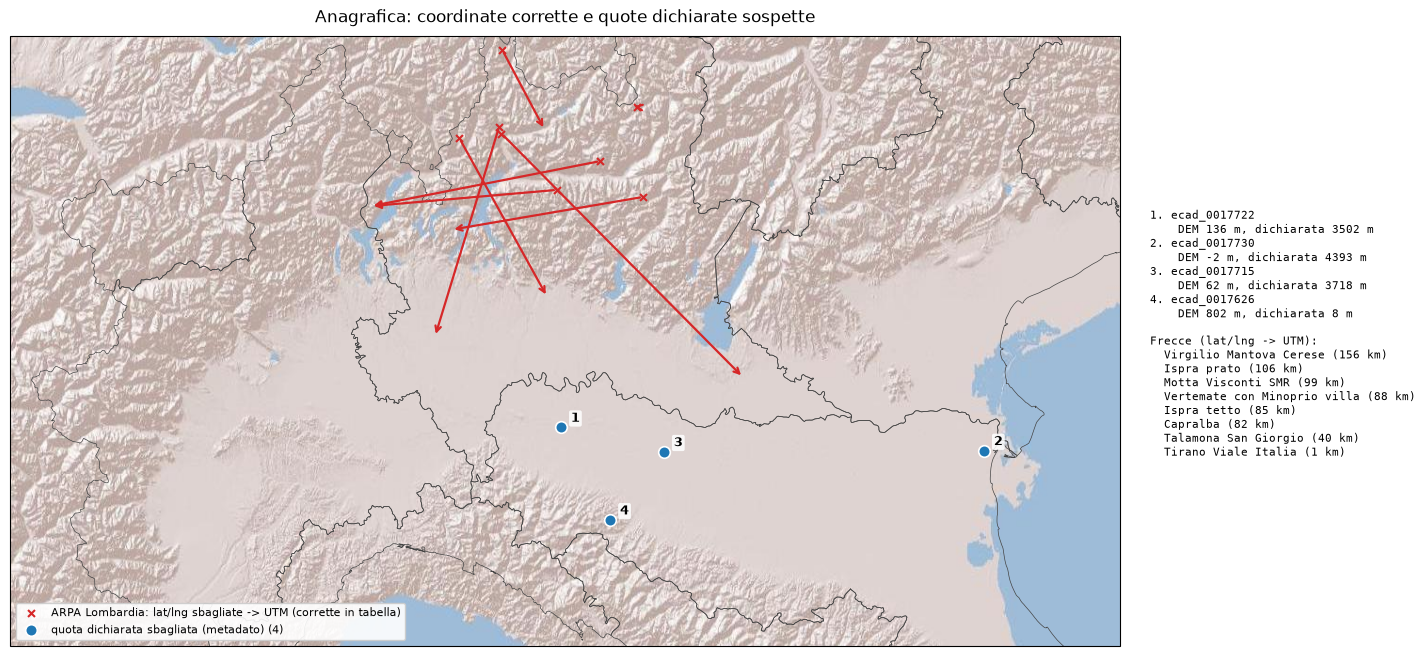

In [37]:
# Map on shaded relief:
#   - arrows: ARPA Lombardia stations moved from lat/lng (wrong) to UTM (right);
#   - points: stations that after the correction still have |DEM elevation - declared| > SOGLIA_QUOTA_M,
#     checked on the DEM within 3 km: if the declared elevation exists nowhere in the surroundings
#     the error is in the metadata (the DEM is right and the "elev" feature is not affected),
#     if it exists a short distance away the coordinates are imprecise.
# Background: Esri World Shaded Relief tiles downloaded by cartopy (needs the network).
import cartopy.io.img_tiles as cimgt
from rasterio.windows import Window


class _EsriRilievo(cimgt.GoogleWTS):
    def _image_url(self, tile):
        x, y, z = tile
        return ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                f"World_Shaded_Relief/MapServer/tile/{z}/{y}/{x}")


def _quota_nei_dintorni(lat, lon, quota, raggio_km=3, toll_m=25):
    """Distance (km) of the nearest DEM point with elevation within toll_m of the declared one,
    NaN if there is none within raggio_km."""
    with rasterio.open(DEM) as d:
        row, col = d.index(lon, lat)
        dy = d.res[1] * 111.2
        dx = d.res[0] * 111.2 * np.cos(np.radians(lat))
        hy, hx = int(raggio_km / dy), int(raggio_km / dx)
        a = d.read(1, window=Window(col - hx, row - hy, 2 * hx + 1, 2 * hy + 1), boundless=True, fill_value=np.nan)
    yy, xx = np.mgrid[-hy:hy + 1, -hx:hx + 1]
    dist = np.hypot(yy * dy, xx * dx)
    ok = (np.abs(a - quota) <= toll_m) & (dist <= raggio_km)
    return float(dist[ok].min()) if ok.any() else np.nan


quote_sospette = out_stations[out_stations["diff_quota"].abs() > SOGLIA_QUOTA_M].copy()
quote_sospette["dist_km_quota_dichiarata"] = [
    _quota_nei_dintorni(r.lat, r.lon, r.quota_dichiarata) for r in quote_sospette.itertuples()]
quote_sospette["caso"] = np.where(quote_sospette["dist_km_quota_dichiarata"].isna(),
                                  "wrong declared elevation (metadata)", "imprecise coordinates")
print(quote_sospette[["uid", "source", "elev", "quota_dichiarata", "dist_km_quota_dichiarata", "caso"]])

_punti = (quote_sospette.groupby(["lat", "lon", "elev", "quota_dichiarata", "caso"])["uid"]
          .apply(lambda u: ", ".join(sorted(u))).reset_index()
          .sort_values("lat", ascending=False).reset_index(drop=True))
_tiles = _EsriRilievo()
_tr = ccrs.PlateCarree()
_colori = {"wrong declared elevation (metadata)": "#1f77b4", "imprecise coordinates": "#ff7f0e"}

fig = plt.figure(figsize=(15, 7))
ax = fig.add_axes([0.02, 0.05, 0.74, 0.88], projection=_tiles.crs)
ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=_tr)
ax.add_image(_tiles, 8)
regions_gdf.boundary.plot(ax=ax, transform=_tr, color="#444444", linewidth=0.5)

for k, r in enumerate(coord_sbagliate.itertuples()):
    ax.annotate("", xy=(r.lon_utm, r.lat_utm), xytext=(r.lng, r.lat),
                xycoords=_tr._as_mpl_transform(ax), textcoords=_tr._as_mpl_transform(ax),
                arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.6), zorder=4)
    ax.scatter(r.lng, r.lat, s=25, marker="x", color="#d62728", transform=_tr, zorder=5,
               label="ARPA Lombardia: wrong lat/lng -> UTM (corrected in the table)" if k == 0 else None)
for caso, col in _colori.items():
    sub = _punti[_punti["caso"] == caso]
    if len(sub):
        ax.scatter(sub["lon"], sub["lat"], s=70, color=col, edgecolor="white", linewidth=1.2,
                   transform=_tr, zorder=6, label=f"{caso} ({quote_sospette['caso'].eq(caso).sum()})")

# On the map only a number per point; the details in a list on the side
_elenco = []
for k, r in _punti.iterrows():
    ax.annotate(str(k + 1), xy=(r["lon"], r["lat"]), xycoords=_tr._as_mpl_transform(ax),
                xytext=(7, 4), textcoords="offset points", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    _elenco.append(f"{k + 1}. {r['uid']}\n    DEM {r['elev']:.0f} m, declared {r['quota_dichiarata']:.0f} m")
_elenco += ["", "Arrows (lat/lng -> UTM):"] + [
    f"  {r.nomestazione} ({r.scarto_km:.0f} km)" for r in coord_sbagliate.itertuples()]
fig.text(0.78, 0.5, "\n".join(_elenco), fontsize=8, va="center", family="monospace")

ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title("Station registry: corrected coordinates and suspicious declared elevations", pad=10)
plt.show()

In [38]:
# Registry 2: stations duplicated between different sources (same sensor published twice,
# e.g. by ECA&D and by the regional network). In training they would count twice. Criterion:
# stations of different sources less than 2 km apart, same variable, identical values (within 0.1)
# on more than 90% of the days in common.
def _dist_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

_D = _dist_km(out_stations["lat"].values[:, None], out_stations["lon"].values[:, None],
              out_stations["lat"].values[None, :], out_stations["lon"].values[None, :])
_src = out_stations["source"].values
_pairs = [(i, j) for i, j in zip(*np.where(_D < 2)) if i < j and _src[i] != _src[j]]

_dup_rows = []
_by_uid = {k: g.set_index(["parameter", "date"])["obs"] for k, g in obs_all.groupby("uid")}
for i, j in _pairs:
    u1, u2 = out_stations.loc[i, "uid"], out_stations.loc[j, "uid"]
    common = pd.concat([_by_uid[u1], _by_uid[u2]], axis=1, join="inner").dropna()
    if len(common) < 30:
        continue
    _dup_rows.append({"uid_1": u1, "uid_2": u2, "dist_km": round(_D[i, j], 2), "giorni_comuni": len(common),
                      "quota_identici": round(((common.iloc[:, 0] - common.iloc[:, 1]).abs() <= 0.1).mean(), 3)})
dup_stations = pd.DataFrame(_dup_rows, columns=["uid_1", "uid_2", "dist_km", "giorni_comuni", "quota_identici"])
print(f"Pairs of stations of different sources less than 2 km apart: {len(dup_stations)}")
print(f"Of which probable duplicates (>90% identical values): {(dup_stations['quota_identici'] > 0.9).sum()}")
dup_stations.sort_values("quota_identici", ascending=False)

Coppie di stazioni di fonti diverse a meno di 2 km: 7
Di cui probabili duplicati (>90% valori identici): 1


,uid_1,uid_2,dist_km,giorni_comuni,quota_identici
0,ecad_0011611,arpalom_8222,0.15,364,0.923
3,ecad_0027786,arpalom_8222,1.98,1087,0.701
5,ecad_0027853,arpalom_7043,1.30,717,0.682
1,ecad_0011611,arpalom_8223,0.15,728,0.680
6,ecad_0027853,arpalom_7046,1.30,1446,0.145
4,ecad_0027786,arpalom_8223,1.98,2178,0.097
2,ecad_0027786,arpalom_17506,1.98,727,0.006


In [39]:
# Common tools for the checks on the series.
OUT_Z = 5                 # robust |z| threshold (MAD): ~5 sigma, only values really off the scale
OUT_RAGGIO_KM = {"tx3": 50, "tn3": 50, "qq2": 50, "rr7": 25}
OUT_MIN_VICINI = 3        # neighbours with data on that day, minimum for the spatial comparison
# For tx3/tn3/qq2 the neighbours must have a similar elevation: in winter with a temperature
# inversion the foggy plain and the sunny hill 20 km away differ by many degrees and many W/m2
# (checked: without this constraint 75% of the tx3 flags fell between October and February).
OUT_MAX_DZ = 200          # m


def _mad(x):
    return 1.4826 * (x - x.median()).abs().median()


def _vicini(st, raggio_km, max_dz=None):
    """uid -> list of the uids within raggio_km (same variable, any source), and with an
    elevation difference <= max_dz if given."""
    D = _dist_km(st["lat"].values[:, None], st["lon"].values[:, None],
                 st["lat"].values[None, :], st["lon"].values[None, :])
    if max_dz is not None:
        D[np.abs(st["elev"].values[:, None] - st["elev"].values[None, :]) > max_dz] = np.inf
    np.fill_diagonal(D, np.inf)
    uids = st["uid"].values
    return {u: list(uids[D[k] < raggio_km]) for k, u in enumerate(uids)}


def _run_identici(df, min_giorni):
    """True on the values that belong to a sequence of >= min_giorni CONSECUTIVE days
    with an identical value (stuck sensor)."""
    df = df.sort_values(["uid", "date"])
    nuovo = ((df["obs"].diff() != 0) | (df["uid"] != df["uid"].shift())
             | (df["date"].diff() != pd.Timedelta(days=1)))
    gruppo = nuovo.cumsum()
    return (df.groupby(gruppo)["obs"].transform("size") >= min_giorni).reindex(df.index)


def _confronto_vicini(df, valori, raggio_km, max_dz=None):
    """For each station-day: median, maximum and number of the neighbours' values on that day.
    `valori` is the column to compare (anomaly for tx3/tn3/qq2, obs for rr7)."""
    st = df.drop_duplicates("uid")[["uid", "lat", "lon", "elev"]]
    vic = _vicini(st, raggio_km, max_dz)
    M = df.pivot_table(index="date", columns="uid", values=valori)
    out = []
    for u, vv in vic.items():
        vv = [v for v in vv if v in M.columns]
        if not vv or u not in M.columns:
            continue
        nb = M[vv]
        out.append(pd.DataFrame({"uid": u, "date": M.index, "vic_mediana": nb.median(axis=1).values,
                                 "vic_max": nb.max(axis=1).values, "vic_n": nb.notna().sum(axis=1).values}))
    res = df[["uid", "date"]].merge(pd.concat(out), on=["uid", "date"], how="left")
    res["vic_n"] = res["vic_n"].fillna(0).astype(int)
    return res.set_index(df.index)

In [40]:
# SARAH-3 clear-sky radiation (SISC, W/m2, UTC day) at the location of each qq2 station:
# physical upper limit for the measured radiation. Cached on disk (reading ~1100 files).
SISC_CACHE = file_tabella(f"sarah_sisc_stazioni_qq2_{'_'.join(map(str, OUT_YEARS))}.csv.gz")  # one cache per set of years
_qq2_st = out_stations[out_stations["uid"].isin(obs_all.loc[obs_all["parameter"] == "qq2", "uid"])]

# the cache is reused only if it contains all the current qq2 stations (otherwise it is rebuilt)
_ok_cache = os.path.exists(SISC_CACHE) and set(_qq2_st["uid"]) <= set(pd.read_csv(SISC_CACHE, usecols=["uid"])["uid"])
if _ok_cache:
    sisc = pd.read_csv(SISC_CACHE, parse_dates=["date"])
else:
    _files = sorted(glob.glob(os.path.join(SARAH_RAW, "SISdm*.nc")))
    with xr.open_dataset(_files[0]) as _ds:
        _iy = np.abs(_ds["lat"].values[None, :] - _qq2_st["lat"].values[:, None]).argmin(axis=1)
        _ix = np.abs(_ds["lon"].values[None, :] - _qq2_st["lon"].values[:, None]).argmin(axis=1)
    _fr = []
    for f in _files:
        d = pd.Timestamp(re.search(r"SISdm(\d{8})", f).group(1))
        if d.year not in set(obs_all["date"].dt.year):
            continue
        with xr.open_dataset(f) as _ds:
            _fr.append(pd.DataFrame({"uid": _qq2_st["uid"].values, "date": d,
                                     "sisc": _ds["SISC"].isel(time=0).values[_iy, _ix]}))
    sisc = pd.concat(_fr, ignore_index=True)
    sisc.to_csv(SISC_CACHE, index=False)
print(f"SISC for {sisc['uid'].nunique()} qq2 stations, {sisc['date'].nunique()} days")

# Check per STATION. Clouds make the measured/clear-sky ratio vary from day to day, but over
# several years nearby stations (same clouds) have similar values. A station with a site or
# sensor problem (shade of an obstacle or of the terrain, miscalibrated or dirty sensor) is low
# on ALL days, even the clearest ones: the daily flags cannot see it, because each value taken
# alone is plausible, so the whole station must be assessed. Criterion: on clear days (90th
# percentile of the ratio) it does not reach 0.8 AND it is at least 0.15 below the neighbours
# within 30 km. A low median ratio with normal clear days is NOT enough: it is fog or local
# cloudiness, real conditions of the site (checked: e.g. arpalom_6476, median 0.50 but clear days 1.04).
_r = obs_all[obs_all["parameter"] == "qq2"].merge(sisc, on=["uid", "date"])
_r["r"] = _r["obs"] / _r["sisc"]
qq2_rapporto = (_r.groupby("uid")
                .agg(source=("source", "first"), lat=("lat", "first"), lon=("lon", "first"),
                     elev=("elev", "first"), n=("r", "size"), rapporto_mediano=("r", "median"),
                     rapporto_sereni=("r", lambda x: x.quantile(0.9)))
                .reset_index())
_Dq = _dist_km(qq2_rapporto["lat"].values[:, None], qq2_rapporto["lon"].values[:, None],
               qq2_rapporto["lat"].values[None, :], qq2_rapporto["lon"].values[None, :])
np.fill_diagonal(_Dq, np.inf)
qq2_rapporto["sereni_vicini"] = [np.median(qq2_rapporto["rapporto_sereni"].values[_Dq[i] < 30])
                                 if (_Dq[i] < 30).sum() >= 3 else np.nan for i in range(len(qq2_rapporto))]
qq2_stazioni_sospette = qq2_rapporto[(qq2_rapporto["rapporto_sereni"] < 0.8)
                                     & (qq2_rapporto["rapporto_sereni"] < qq2_rapporto["sereni_vicini"] - 0.15)]
qq2_stazioni_sospette.to_csv(QQ2_SOSPETTE, index=False)  # read by ablation_esclusioni.py
print("Measured/clear-sky ratio per station, median and clear days:",
      qq2_rapporto[["rapporto_mediano", "rapporto_sereni"]].median().round(2).to_dict())
print(f"Suspicious qq2 stations (site/sensor): {len(qq2_stazioni_sospette)} out of {len(qq2_rapporto)}")
qq2_stazioni_sospette.round(2)

SISC per 342 stazioni qq2, 1462 giorni
Rapporto misurata/cielo sereno per stazione, mediana e giorni sereni: {'rapporto_mediano': 0.81, 'rapporto_sereni': 1.0}
Stazioni qq2 sospette (sito/sensore): 8 su 342


,uid,source,lat,lon,elev,n,rapporto_mediano,rapporto_sereni,sereni_vicini
118,arpalom_17476,arpa_lom,46.29,9.34,1358.20,730,0.63,0.78,0.95
207,ecad_0026108,ecad,46.19,11.68,803.45,1096,0.50,0.75,0.95
225,ecad_0026197,ecad,45.76,11.17,1173.64,1013,0.36,0.63,0.94
231,ecad_0026205,ecad,46.38,10.63,2961.97,6,0.00,0.00,0.93
233,ecad_0026214,ecad,46.16,10.76,759.00,1095,0.47,0.63,0.94
237,ecad_0026234,ecad,46.45,11.01,1098.25,1096,0.59,0.77,0.94
245,ecad_0026277,ecad,46.18,10.63,1417.15,1079,0.49,0.74,0.92
260,ecad_0027744,ecad,46.39,12.36,524.23,1005,0.62,0.78,0.94


In [41]:
# tx3 / tn3 / qq2: anomaly with respect to the station-month (median), robust z (MAD) in time
# and in space (station anomaly minus the median of the neighbours' anomalies on that day,
# neighbours within OUT_RAGGIO_KM and with a similar elevation), both with a scale per station-month.
#   flag_z        : |temporal z| > OUT_Z -> extreme value for that station and that month
#   flag_spaziale : |spatial z|  > OUT_Z -> the value departs from the neighbours on that day
#   flag_bloccato : >= 4 consecutive days with an identical value (stuck sensor)
#   flag_sereno   : (qq2 only) radiation > 1.2 x SARAH clear sky + 25 W/m2. Wide margin:
#                   SARAH computes the clear sky on the mean elevation of a ~5 km pixel and without
#                   snow, so in the mountains it underestimates it (the exceedances of 1.15 were
#                   almost all in winter and on stations at ~650 m median elevation)
# A "flag_z" value WITHOUT "flag_spaziale" but with neighbours available is a real event
# (extreme shared with the area), not an error.
# station-months without enough neighbours -> median of NaN only: harmless warning
warnings.filterwarnings("ignore", message="Mean of empty slice")
_flags = []
for param in ["tx3", "tn3", "qq2"]:
    d = obs_all[obs_all["parameter"] == param].copy()
    d["mese"] = d["date"].dt.month
    g = d.groupby(["uid", "mese"])["obs"]
    d["anom"] = d["obs"] - g.transform("median")
    d["z_temporale"] = d["anom"] / g.transform(_mad).replace(0, np.nan)

    d = d.join(_confronto_vicini(d, "anom", OUT_RAGGIO_KM[param], OUT_MAX_DZ)[["vic_mediana", "vic_n"]])
    d["diff_vicini"] = np.where(d["vic_n"] >= OUT_MIN_VICINI, d["anom"] - d["vic_mediana"], np.nan)
    # scale per station-MONTH: the normal spread between neighbours changes a lot with the season
    # (patchy fog in winter, thunderstorms in summer); with a single scale per station the
    # flags were concentrated in December (tx3) and in June (qq2)
    gd = d.groupby(["uid", "mese"])["diff_vicini"]
    d["z_spaziale"] = (d["diff_vicini"] - gd.transform("median")) / gd.transform(_mad).replace(0, np.nan)

    d["flag_z"] = d["z_temporale"].abs() > OUT_Z
    d["flag_spaziale"] = d["z_spaziale"].abs() > OUT_Z
    d["flag_bloccato"] = _run_identici(d, 4)
    if param == "qq2":
        d = d.merge(sisc, on=["uid", "date"], how="left").set_index(d.index)
        d["flag_sereno"] = d["obs"] > 1.2 * d["sisc"] + 25
    _flags.append(d)

flags_cont = pd.concat(_flags, ignore_index=True)
flags_cont["flag_sereno"] = flags_cont["flag_sereno"].eq(True)
flags_cont["estremo_confermato"] = (flags_cont["flag_z"] & ~flags_cont["flag_spaziale"]
                                    & (flags_cont["vic_n"] >= OUT_MIN_VICINI))
print("Flagged values (tx3/tn3/qq2):")
print(flags_cont.groupby("parameter")[["flag_z", "flag_spaziale", "flag_bloccato", "flag_sereno",
                                        "estremo_confermato"]].sum())

Valori segnalati (tx3/tn3/qq2):
           flag_z  flag_spaziale  flag_bloccato  flag_sereno  \
parameter                                                      
qq2           781           2420            132           68   
tn3           405           1119             52            0   
tx3            67           2147             25            0   

           estremo_confermato  
parameter                      
qq2                       599  
tn3                       341  
tx3                        57  


In [42]:
# rr7: precipitation is zero on most days, the z-score makes no sense. Checks:
#   flag_pioggia_isolata : >= 20 mm while ALL the neighbours (>= 3, within 25 km) have < 1 mm (isolated rain)
#   flag_secco_isolato   : 0 mm while the median of the neighbours is >= 20 mm (stuck/clogged gauge)
#   flag_accumulo        : day after a gap with precipitation >= max(30 mm, 99th percentile of the
#                          station): possibly the sum of several days recorded on one
#   flag_bloccato        : >= 3 consecutive days with the same value >= 1 mm. Not below 1 mm:
#                          0.2 mm is a single tip of the tipping-bucket gauge, and several days
#                          in a row at 0.2 are drizzle/dew, not a stuck sensor
d = obs_all[obs_all["parameter"] == "rr7"].copy().sort_values(["uid", "date"])
d = d.join(_confronto_vicini(d, "obs", OUT_RAGGIO_KM["rr7"])[["vic_mediana", "vic_max", "vic_n"]])
_ok = d["vic_n"] >= OUT_MIN_VICINI
d["flag_pioggia_isolata"] = _ok & (d["obs"] >= 20) & (d["vic_max"] < 1)
d["flag_secco_isolato"] = _ok & (d["obs"] == 0) & (d["vic_mediana"] >= 20)
_dopo_buco = (d["uid"] == d["uid"].shift()) & (d["date"].diff() > pd.Timedelta(days=1))
_p99 = d.groupby("uid")["obs"].transform(lambda x: x.quantile(0.99))
d["flag_accumulo"] = _dopo_buco & (d["obs"] >= np.maximum(30, _p99))
d["flag_bloccato"] = _run_identici(d, 3) & (d["obs"] >= 1)
flags_rr7 = d
print("Flagged values (rr7):")
print(flags_rr7[["flag_pioggia_isolata", "flag_secco_isolato", "flag_accumulo", "flag_bloccato"]].sum())

Valori segnalati (rr7):
flag_pioggia_isolata     30
flag_secco_isolato      172
flag_accumulo            38
flag_bloccato            54
dtype: int64


In [43]:
# Summary: a single flag table for all the variables. "sospetto" (suspicious) = at least one flag of
# a probable error; the extremes confirmed by the neighbours are NOT suspicious.
_err_cont = ["flag_spaziale", "flag_bloccato", "flag_sereno"]
_err_rr7 = ["flag_pioggia_isolata", "flag_secco_isolato", "flag_accumulo", "flag_bloccato"]
flags_cont["sospetto"] = flags_cont[_err_cont].any(axis=1)
flags_rr7["sospetto"] = flags_rr7[_err_rr7].any(axis=1)
outlier_flags = pd.concat([flags_cont, flags_rr7], ignore_index=True)
_flag_cols = [c for c in outlier_flags.columns if c.startswith("flag_")]
outlier_flags[_flag_cols + ["estremo_confermato"]] = outlier_flags[_flag_cols + ["estremo_confermato"]].eq(True)

out_summary = (outlier_flags.groupby(["source", "parameter"])
               .agg(n=("obs", "size"), sospetti=("sospetto", "sum"), estremi_confermati=("estremo_confermato", "sum")))
out_summary["sospetti_%"] = (100 * out_summary["sospetti"] / out_summary["n"]).round(3)
print(out_summary)

# Stations with the highest share of suspicious values (candidates for a manual check)
out_by_station = (outlier_flags.groupby(["uid", "source", "parameter"])["sospetto"]
                  .agg(n="size", sospetti="sum").reset_index())
out_by_station["sospetti_%"] = (100 * out_by_station["sospetti"] / out_by_station["n"]).round(2)

# Saving only the flagged rows (to decide afterwards what to exclude from training)
OUT_FLAGS_FILE = file_tabella(f"outlier_flags_{'_'.join(map(str, OUT_YEARS))}.csv.gz")  # read by ablation_esclusioni.py
_salva = outlier_flags[outlier_flags["sospetto"] | outlier_flags["estremo_confermato"] | outlier_flags["flag_z"]]
_salva[["uid", "source", "parameter", "date", "obs"] + _flag_cols + ["estremo_confermato", "sospetto"]].to_csv(
    OUT_FLAGS_FILE, index=False)
print(f"\nSaved {len(_salva)} flagged rows in {OUT_FLAGS_FILE}")
out_by_station.sort_values("sospetti_%", ascending=False).head(15)

                              n  sospetti  estremi_confermati  sospetti_%
source        parameter                                                  
arpa_lom      qq2         94047       894                 300       0.951
              rr7        247584       133                   0       0.054
              tn3        251968       393                  10       0.156
              tx3        251978       579                  13       0.230
arpa_piemonte qq2         22094       234                  57       1.059
              rr7        104377        53                   0       0.051
              tn3        100582       343                 290       0.341
              tx3        100589       528                   9       0.525
arpae         qq2         21241       201                  81       0.946
ecad          qq2        152941      1266                 161       0.828
              rr7        446991       106                   0       0.024
              tn3        373648       

,uid,source,parameter,n,sospetti,sospetti_%
2727,ecad_0026205,ecad,qq2,6,6,100.00
2707,ecad_0026122,ecad,qq2,724,49,6.77
2183,ecad_0017581,ecad,tx3,87,4,4.60
2541,ecad_0017801,ecad,tx3,88,4,4.55
1157,arpalom_17429,arpa_lom,qq2,465,20,4.30
1180,arpalom_17501,arpa_lom,qq2,730,29,3.97
107,PIE-001097-900,arpa_piemonte,qq2,366,14,3.83
245,PIE-001270-901,arpa_piemonte,tx3,366,14,3.83
212,PIE-001232-900,arpa_piemonte,tx3,363,13,3.58
2658,ecad_0017873,ecad,tx3,30,1,3.33


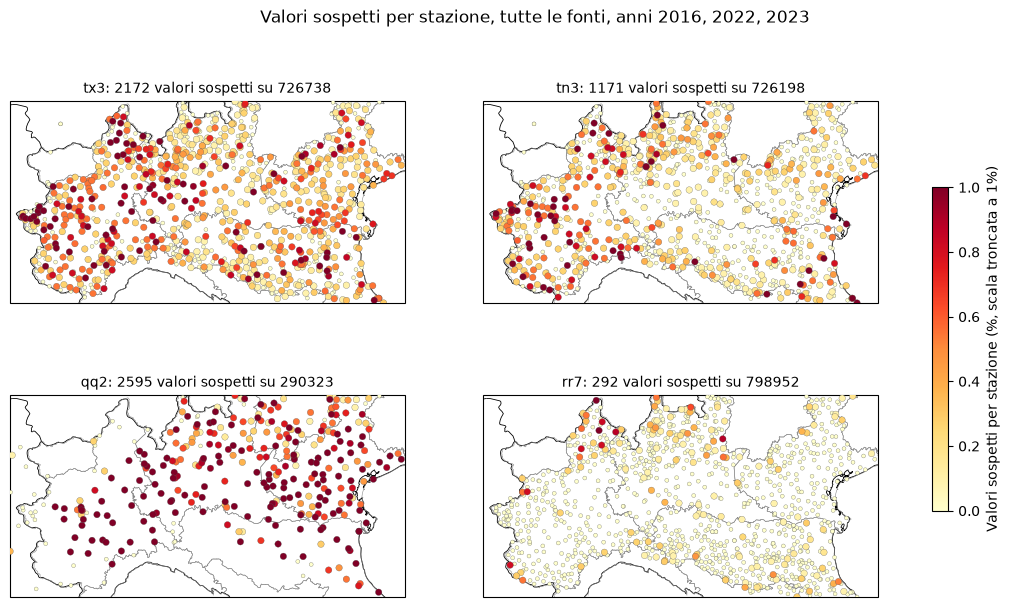

In [44]:
# Map: share of suspicious values per station, one panel per variable. Natural Earth coastlines
# and borders read with geopandas (see the note on the ARPAE map: with cfeature the lines can
# end up shifted if the session has maps in different projections).
import cartopy.io.shapereader as shpreader

_coste = gpd.read_file(shpreader.natural_earth("10m", "physical", "coastline"))
_confini = gpd.read_file(shpreader.natural_earth("10m", "cultural", "admin_0_boundary_lines_land"))
_tr = ccrs.PlateCarree()
_m = out_by_station.merge(out_stations[["uid", "lat", "lon"]], on="uid")

fig, axes = plt.subplots(2, 2, figsize=(14, 7), subplot_kw={"projection": _tr})
for ax, param in zip(axes.flat, ["tx3", "tn3", "qq2", "rr7"]):
    sub = _m[_m["parameter"] == param].sort_values("sospetti_%")
    _coste.plot(ax=ax, transform=_tr, color="black", linewidth=0.6)
    _confini.plot(ax=ax, transform=_tr, color="black", linewidth=0.6)
    regions_gdf.boundary.plot(ax=ax, transform=_tr, color="#888888", linewidth=0.4)
    sc = ax.scatter(sub["lon"], sub["lat"], c=sub["sospetti_%"], cmap="YlOrRd", vmin=0, vmax=1,
                    s=np.where(sub["sospetti_%"] > 0, 22, 8), edgecolor="#555555", linewidth=0.2,
                    transform=_tr, zorder=5)
    ax.set_extent([AREA_WEST, AREA_EAST, AREA_SOUTH, AREA_NORTH], crs=_tr)
    ax.set_title(f"{param}: {int(sub['sospetti'].sum())} suspicious values out of {int(sub['n'].sum())}", fontsize=10)
fig.colorbar(sc, ax=axes, label="Suspicious values per station (%, scale capped at 1%)", shrink=0.6)
fig.suptitle(f"Suspicious values per station, all sources, years {', '.join(map(str, OUT_YEARS))}")
plt.show()

**Results (2016, 2022, 2023 + Piedmont test 2020).** The data are clean overall: the suspicious values are between 0.02% and 1.1% per source and variable, and tx3 < tn3 never happens. The things to decide are few and concrete:

- **Registry, coordinates.** In the ARPA Lombardia registry `lat`/`lng` are wrong by 40-155 km for 8 stations (21 sensors: e.g. "Virgilio Mantova Cerese" ended up above Lake Como, "Ispra" in Val Seriana), while the UTM coordinates of the same registry are right (median DEM elevation error 824 m with lat/lng, 3 m with UTM). Four of these would not have been found by the elevation check alone, because the wrong point happened to have a similar elevation. Monte Cimone (ECA&D) had coordinates rounded to 0.1 degrees, 650 m below the summit. **The training table is already corrected** (§6.6: UTM for ARPA Lombardia, `CORREZIONI_MANUALI` for Monte Cimone): right coordinates, DEM elevation and Aurora interpolated at the right point. On the 10 corrected stations present in the table the observed bias - Aurora (Aurora interpolated at the wrong point vs at the right point, same 2016/2022/2023 rows) dropped for tx3 from +4.9 to +2.8 degrees and for qq2 from +15.3 to -1.8 W/m2.
- **Registry, elevations.** After the correction 4 ECA&D stations (provider Valentina Pavan) remain with an impossible declared elevation: Piacenza 3502 m, Parma 3718 m, Pomposa 4393 m in the plain, Fugazzolo 8 m on the Apennines. In the DEM within 3 km that elevation exists nowhere, so the error is in the metadata: the DEM is right and the training feature `elev` is not affected.
- **Registry, duplicates.** `ecad_0011611` and `arpalom_8222` are 150 m apart and have 94% identical values: it is the same station published by two sources, and in training it counts twice. Only one of the two must be kept.
- **qq2, whole stations.** Over several years nearby stations see the same clouds and have a similar measured/clear-sky ratio; a station that is low even on the clearest days has a site or sensor problem affecting every value, which the daily flags cannot find. With the criterion "clear days < 0.8 and at least 0.15 below the neighbours" there are 8 stations (`qq2_stazioni_sospette.csv`), almost all in Alpine valleys: besides miscalibrated sensors, it can be terrain shading, a real effect of the site but not representative of the area. A fixed threshold on the median ratio alone (e.g. 0.6) was wrong: it cut stations with normal clear days (fog, local cloudiness) and the continuous tail of the distribution.
- **Single values.** After the two adjustments to the neighbour comparison (similar elevation, scale per station-month) the flags are evenly distributed over the months, so they do not depend on the season. For rr7 the cases are few: 30 isolated rains, 172 dry days with the neighbours under rain, 38 possible accumulations after a gap, 54 stuck sequences (with the observations of the previous pipeline the accumulations were 277: the z > 4 filter removed the days of heavy rain, and the day after looked like an accumulation after a gap).

The flagged rows are in `outlier_flags_2016_2022_2023.csv.gz`. Next step: decide the exclusions (duplicate, anomalous qq2 stations, coordinates to check, `sospetto` values) and measure their effect with leave-one-region-out (`inutili/loro_cv.py`, later replaced by the region x year CV of `cv_regione_anno.py`): checked with `ablation_esclusioni.py`, removing the duplicate, the anomalous qq2 stations and the qq2/rr7 flags does not change the RMSE measurably (differences below the variability between seeds), so the cleaning serves mainly to have reliable validation/test metrics. The `OUT_Z` threshold can be raised to reduce the spatial flags, which at 5 remain 0.1-0.5% for tx3/tn3.

### 7.2 Exclusions from training

From the checks of §7.1 only the cases that are **obvious errors** are excluded, checked by group (comparison with Aurora, physical consistency with the neighbours): neither the extreme values nor the spatial flags of tx3/tn3 are removed, since they turned out to be real weather.

- **duplicate between sources**: of the pair, the station with fewer data is removed;
- **qq2, whole stations** with a site or sensor problem (`qq2_stazioni_sospette`): on clear days they do not reach the clear sky;
- **qq2, single days**: above the SARAH clear sky or stuck values;
- **rr7, single days**: isolated rain, isolated dry day, accumulation after a gap, stuck values.

The training table stays intact: the exclusions go into `esclusioni_training.csv` and are applied by `train_downscaling_head.py` and by the cross-validation (`cv_regione_anno.py`, `cv_comune.py`) before training, so a comparison with and without is always possible. On training the effect is negligible (checked with `ablation_esclusioni.py`); the main reason is to have validation and test (Piedmont) metrics not distorted by wrong values.

In [45]:
# Exclusions: one row per whole station (empty date; empty parameter = all variables)
# or per single day. Saved in esclusioni_training.csv, applied by the training scripts.
# The "motivo" (reason) values are kept in Italian, as stored in the file:
# "duplicato tra fonti" = duplicate between sources; qq2 station below the clear sky (site/sensor);
# qq2 above the clear sky or stuck; rr7 inconsistent with the neighbours, accumulation or stuck.
_n_righe = obs_all.groupby("uid").size()
_dup = dup_stations[dup_stations["quota_identici"] > 0.9]
_dup_fuori = [u1 if _n_righe.get(u1, 0) < _n_righe.get(u2, 0) else u2
              for u1, u2 in zip(_dup["uid_1"], _dup["uid_2"])]

_f = outlier_flags
_m_qq2 = (_f["parameter"] == "qq2") & (_f["flag_sereno"] | _f["flag_bloccato"])
_m_rr7 = (_f["parameter"] == "rr7") & _f[["flag_pioggia_isolata", "flag_secco_isolato",
                                          "flag_accumulo", "flag_bloccato"]].any(axis=1)
esclusioni = pd.concat([
    pd.DataFrame({"uid": _dup_fuori, "parameter": None, "date": pd.NaT, "motivo": "duplicato tra fonti"}),
    qq2_stazioni_sospette[["uid"]].assign(parameter="qq2", date=pd.NaT,
                                          motivo="qq2: stazione sotto il cielo sereno (sito/sensore)"),
    _f.loc[_m_qq2, ["uid", "parameter", "date"]].assign(motivo="qq2: sopra il cielo sereno o bloccato"),
    _f.loc[_m_rr7, ["uid", "parameter", "date"]].assign(motivo="rr7: incoerente con i vicini, accumulo o bloccato"),
], ignore_index=True)
esclusioni.to_csv(ESCLUSIONI, index=False)

# Table rows affected, by reason and by split
_intere = esclusioni[esclusioni["date"].isna()]
_giorni = esclusioni[esclusioni["date"].notna()]
_toccate = pd.concat([
    obs_all.merge(_intere[_intere["parameter"].isna()][["uid", "motivo"]], on="uid"),
    obs_all.merge(_intere[_intere["parameter"].notna()][["uid", "parameter", "motivo"]], on=["uid", "parameter"]),
    obs_all.merge(_giorni[["uid", "parameter", "date", "motivo"]], on=["uid", "parameter", "date"]),
]).drop_duplicates(["uid", "parameter", "date"])
print(f"Saved esclusioni_training.csv: {len(esclusioni)} entries, {len(_toccate)} table rows "
      f"({100 * len(_toccate) / len(obs_all):.2f}%)")
print(f"Duplicate stations removed: {_dup_fuori}")
_toccate.groupby(["motivo", "split"]).size().unstack(fill_value=0)

Salvato esclusioni_training.csv: 501 voci, 8676 righe della tabella (0.34%)
Stazioni duplicate tolte: ['arpalom_8222']


split,test,train
motivo,,
duplicato tra fonti,0,1094
qq2: sopra il cielo sereno o bloccato,1,169
qq2: stazione sotto il cielo sereno (sito/sensore),0,7120
"rr7: incoerente con i vicini, accumulo o bloccato",53,239


**Result:** the best phase for both providers (Veneto and Emilia-Romagna) is the one with the day
starting at **21:00 UTC** (offset -3h with respect to UTC midnight), not 0h.
The mean rr7-CERRA correlation rises from ~0.25-0.31 (UTC day) to ~0.65-0.75 (day from
21 UTC), confirming the hypothesis: -3h is the multiple of 3h closest to the real local midnight
(23:00 UTC in CET, 22:00 UTC in CEST) that can be reached with the CERRA resolution.
The same convention (day = [21:00 UTC day-1, 21:00 UTC]) must also be used for
`tx3`/`tn3`/`qq2` in the comparison with CERRA, for consistency, even if the expected impact on
daily maxima/minima is smaller than on an accumulation like `rr7` (§ previous
discussion). The residual correlation (~0.65-0.75, not 1) reflects the physical limit of the
station-point vs grid-cell comparison (local convection, orography), no longer a
time-zone artefact.